# 0.Import knihoven 

In [1]:
import os
import csv
import json
import pandas as pd
import numpy as np

import openpyxl
from openpyxl.utils.dataframe import dataframe_to_rows

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from pathlib import Path
import re

# 1. Projekt financování sociálních služeb - data

## 1.1 Import zdrojových dat

Data za jednotlivé roky z databáze MOS - "mos_data_2024". "mos_data_2023" atd.
-> jednotlivé datové soubory obsahují rok, kód ukazatele, kód území a hodnotu ukazatele
-> z těchto datových souborů nevíme, co jsou jednotlivé kódy ukazatelů, proto je nutné je mergovat na číselníky
-> data za všechny roky jsou spojené do DataFrame "mos_data_all"

**číselník ukazatelů - "mos_ukaz"**<br>
-> kód, název ukazatele, mj, platiod, platido, okruh, zdroj, verifikace csu, metodika<br>
-> důležité je zde to napojení kódu na název, dále pak okruh<br>

**Číselník území - "mos_uzemi"**<br>
-> kód, obec, platiod, platido, okres, soorp<br>
-> tady zjistíme jaké území se skrývá pod kódem území<br>

**Číselník okruhů - "mos_okruhy"**<br>
-> tematické okruhy jsou uvedeny v souboru "mos_ukaz", zde je pro ně číselník<br>

**Merge všech DataFrame - "mos_full"**<br>
-> left join relevantních DF:<br>
    - mos_data_all<br>
    - mos_ukaz<br>
    - mos_uzemi<br>
    - mos_okruhy<br>


### 1.1.1 Nadregionální síť sociálních služeb

**Zdroj dat** <br>

Data za jednotlivé roky z webu MPSV - "nadregion_2020", "nadregion_2021" atd.

Data o dotacích z webu MPSV
Data jsou stažena z webu MPSV (https://mpsv.gov.cz/c-j-mpsv-2026-20439-vysledky-dotacniho-rizeni-mpsv-pro-kraje-a-hlavni-mesto-prahu-v-oblasti-poskytovani-socialnich-sluzeb-za-roky-2020-2025). 

**Obsah datových souborů**<br>
Jsou zde csv soubory pro jednotlivé roky. Informace z nich plynoucí je suma dotace přidělovaná MPSV konkrétnímu poskytovately soc. službe v rámci nadregionální sítě soc. služeb. Data za jednotlivé roky jsou vyčištěná a spojená do DF "nadregion_all"

In [2]:
# Načtení dat z nadregionální sítě za jednotlivé roky

roky = range(2020, 2026)

text_sloupce = ["Název poskytovatele", "IČO", "ID služby", "Druh služby"]

nadregion_data = {}
for rok in roky:
    nadregion_data[rok] = pd.read_csv(
        f"nadregion_{rok}.csv",
        sep=";",
        encoding="utf-8-sig",   # případně "cp1250", viz níže
        decimal=",",
        thousands=" ",
        dtype={s: "string" for s in text_sloupce},
        low_memory=False
    )

print(f"Načteno {len(nadregion_data)} souborů: {sorted(nadregion_data)}")

Načteno 6 souborů: [2020, 2021, 2022, 2023, 2024, 2025]


In [3]:
# 1) zahodit úplně prázdné sloupce (Unnamed artefakty) a prázdné řádky
for rok in nadregion_data:
    df = nadregion_data[rok]
    df = df.dropna(axis=1, how="all")   # sloupce bez jediné hodnoty
    df = df.dropna(axis=0, how="all")   # řádky bez jediné hodnoty
    nadregion_data[rok] = df.reset_index(drop=True)

# 2) kontrola
for rok, df in nadregion_data.items():
    print(rok, df.shape, "| chybí Rok:", df["Rok"].isna().sum(), "|", list(df.columns))

2020 (179, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']
2021 (192, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']
2022 (202, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']
2023 (218, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']
2024 (222, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']
2025 (161, 6) | chybí Rok: 0 | ['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok']


In [4]:
# # Sloupec Rok sjednotíme na nullable Int64 – po importu bývá float (2021.0)
for rok in nadregion_data:
    nadregion_data[rok]["Rok"] = nadregion_data[rok]["Rok"].astype("Int64")

In [5]:
# DIAGNOSTIKA (nemění data): kontrola konzistence dtypů mezi ročníky.
prehled = pd.DataFrame({rok: df.dtypes for rok, df in nadregion_data.items()})
display(prehled)

print("Sloupce s různým typem mezi ročníky:")
display(prehled[prehled.nunique(axis=1) > 1])

,2020,2021,2022,2023,2024,2025
Název poskytovatele,string[python],string[python],string[python],string[python],string[python],string[python]
IČO,string[python],string[python],string[python],string[python],string[python],string[python]
ID služby,string[python],string[python],string[python],string[python],string[python],string[python]
Druh služby,string[python],string[python],string[python],string[python],string[python],string[python]
Přidělená dotace,object,object,object,object,object,object
Rok,Int64,Int64,Int64,Int64,Int64,Int64


Sloupce s různým typem mezi ročníky:


,2020,2021,2022,2023,2024,2025


In [6]:
# ČIŠTĚNÍ SLOUPCE "Přidělená dotace" → číselný typ
# Vstup: hodnoty přišly ze zdroje jako text (dtype=object), viz diagnostika výše.
# Typické nečistoty: nezlomitelná mezera jako oddělovač tisíců ("1 000 000"),
# desetinná čárka a přilepená měna ("125 000 Kč").
def na_cislo(s):
    return pd.to_numeric(
        s.astype("string")
         .str.replace(r"[\s\u00a0]", "", regex=True)
         .str.replace(",", ".", regex=False)
         .str.replace("Kč", "", regex=False)
         .str.strip(),
        errors="coerce"
    ).astype("Float64")
    
# Aplikace na všechny ročníky – přepisuje sloupec na místě.
# Idempotentní: opakované spuštění buňky už vyčištěná čísla nepoškodí.
for rok in nadregion_data:
    nadregion_data[rok]["Přidělená dotace"] = na_cislo(nadregion_data[rok]["Přidělená dotace"])

# KONTROLA PO PŘEVODU (nemění data).
# Smysl: errors="coerce" selhává tiše. Když se v novém ročníku změní formát zápisu,
# sloupec by se beze zjevné chyby přepsal na NA. Sledované ukazatele:
#   dtype  – musí být Float64 u všech ročníků (jinak převod neproběhl)
#   součet – řádová kontrola proti oficiálním výkazům dotací
#   min/max – odhalí záporné hodnoty nebo řádovou chybu (chybějící/nadbytečné nuly)
#   chybí  – skokový nárůst = signál nového formátu zápisu, ne skutečně prázdná data
for rok, df in nadregion_data.items():
    d = df["Přidělená dotace"]
    print(rok, d.dtype, "| součet:", f"{d.sum():,.0f}",
          "| min:", d.min(), "| max:", d.max(), "| chybí:", d.isna().sum())

2020 Float64 | součet: 832,782,576 | min: 137500.0 | max: 31357400.0 | chybí: 0
2021 Float64 | součet: 1,139,031,962 | min: 126500.0 | max: 40760045.0 | chybí: 0
2022 Float64 | součet: 1,078,507,186 | min: 223782.0 | max: 42275071.0 | chybí: 0
2023 Float64 | součet: 1,520,210,324 | min: 248588.0 | max: 49505909.0 | chybí: 0
2024 Float64 | součet: 1,520,992,400 | min: 190300.0 | max: 48989900.0 | chybí: 0
2025 Float64 | součet: 1,167,597,370 | min: 284583.0 | max: 44351000.0 | chybí: 0


In [7]:
# DIAGNOSTIKA (nemění data): lze ročníky spojovat podle IČO?
# Nevalidní = není přesně 8 číslic; typicky Excel odřízl vedoucí nuly (01234567 → 1234567).
# Skok v počtu unikátů = změna klasifikace služeb nebo nejednotný zápis poskytovatele.
for rok, df in nadregion_data.items():
    ico = df["IČO"].astype("string").str.strip()
    print(rok,
          "| IČO nevalidní:", (~ico.str.fullmatch(r"\d{8}", na=False)).sum(),
          "| druhů služeb:", df["Druh služby"].nunique(),
          "| názvů poskytovatelů:", df["Název poskytovatele"].nunique())

2020 | IČO nevalidní: 36 | druhů služeb: 21 | názvů poskytovatelů: 91
2021 | IČO nevalidní: 39 | druhů služeb: 21 | názvů poskytovatelů: 97
2022 | IČO nevalidní: 41 | druhů služeb: 22 | názvů poskytovatelů: 103
2023 | IČO nevalidní: 46 | druhů služeb: 22 | názvů poskytovatelů: 110
2024 | IČO nevalidní: 46 | druhů služeb: 22 | názvů poskytovatelů: 114
2025 | IČO nevalidní: 31 | druhů služeb: 21 | názvů poskytovatelů: 86


In [8]:
# Spojení všech ročníků + kontrola výskytu druhů služeb (překlepy, dvojí zápisy).
# ignore_index=True kvůli duplicitním indexům; to_string() zabrání zkrácení výpisu.
vsechny = pd.concat(nadregion_data.values())
print(vsechny["Druh služby"].value_counts().to_string())

Druh služby
odborné sociální poradenství                                                  349
sociální rehabilitace                                                         162
telefonická krizová pomoc                                                      91
služby následné péče                                                           85
terapeutické komunity                                                          77
domovy pro seniory                                                             68
domovy se zvláštním režimem                                                    44
tísňová péče                                                                   37
odlehčovací služby                                                             36
raná péče                                                                      31
tlumočnické služby                                                             25
sociálně aktivizační služby pro rodiny s dětmi                                 22
teré

In [9]:
# NORMALIZACE SLOUPCE "Druh služby"
# Cíl: jeden druh služby = jeden zápis, aby fungovaly agregace a spojení ročníků.
def norm_druh(s):
    return (s.astype("string")
             .str.replace(r"\s+", " ", regex=True)   # zalomení řádků i vícenásobné mezery
             .str.strip()
             .str.lower()
             .replace({"": pd.NA}))

mapovani = {
    "sas pro seniory a osoby se zdravotním postižením":
        "sociálně aktivizační služby pro seniory a osoby se zdravotním postižením",
}

for rok in nadregion_data:
    nadregion_data[rok]["Druh služby"] = norm_druh(nadregion_data[rok]["Druh služby"]).replace(mapovani)

# kontrola
vsechny = pd.concat(nadregion_data.values())
print("unikátních druhů:", vsechny["Druh služby"].nunique())
print(vsechny["Druh služby"].value_counts(dropna=False).to_string())

unikátních druhů: 22
Druh služby
odborné sociální poradenství                                                349
sociální rehabilitace                                                       162
telefonická krizová pomoc                                                    91
služby následné péče                                                         85
terapeutické komunity                                                        77
domovy pro seniory                                                           68
domovy se zvláštním režimem                                                  44
tísňová péče                                                                 37
odlehčovací služby                                                           36
sociálně aktivizační služby pro rodiny s dětmi                               32
raná péče                                                                    31
sociálně aktivizační služby pro seniory a osoby se zdravotním postižením     28
tlumočn

In [10]:
# sjednocení zápisu názvů
for rok in nadregion_data:
    nadregion_data[rok]["Název poskytovatele"] = (
        nadregion_data[rok]["Název poskytovatele"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# kontrola, kde jedno IČO odpovídá více názvům
vsechny = pd.concat(nadregion_data.values())
kontrola = vsechny.groupby("IČO")["Název poskytovatele"].nunique()
display(kontrola[kontrola > 1])

IČO
19495056    2
24732915    2
25380443    2
26537036    2
27574601    2
29368227    2
44990901    2
48136093    2
499811      2
5268800     2
552534      2
61383082    2
6229654     2
62690361    3
70100691    2
70818134    2
Name: Název poskytovatele, dtype: int64

In [11]:
# Kontroly konzistence a duplicity v datech: jedno IČO vs. název poskytovatele, jedno ID služby vs. poskytovatel/druh služby a duplicity v rámci roku

vsechny = pd.concat(nadregion_data, names=["rok_souboru"]).reset_index(level=0)

# jedno IČO = jeden název?
k1 = vsechny.groupby("IČO")["Název poskytovatele"].nunique()
print("IČO s více názvy:", (k1 > 1).sum())
display(k1[k1 > 1].head(10))

# jedno ID služby = jeden poskytovatel a jeden druh?
k2 = vsechny.groupby("ID služby")[["IČO", "Druh služby"]].nunique()
print("\nID služby s více IČO:", (k2["IČO"] > 1).sum())
print("ID služby s více druhy:", (k2["Druh služby"] > 1).sum())
display(k2[(k2 > 1).any(axis=1)].head(10))

# duplicita v rámci roku
dupl = vsechny[vsechny.duplicated(["rok_souboru", "ID služby"], keep=False)]
print("\nřádků s duplicitním ID služby v rámci roku:", len(dupl))
display(dupl.sort_values(["rok_souboru", "ID služby"]).head(10))

IČO s více názvy: 16


IČO
19495056    2
24732915    2
25380443    2
26537036    2
27574601    2
29368227    2
44990901    2
48136093    2
499811      2
5268800     2
Name: Název poskytovatele, dtype: int64


ID služby s více IČO: 0
ID služby s více druhy: 0


,IČO,Druh služby
ID služby,,



řádků s duplicitním ID služby v rámci roku: 0


,rok_souboru,Název poskytovatele,IČO,ID služby,Druh služby,Přidělená dotace,Rok


In [12]:
# zobrazení inkonzietsntních názvů a IČO

varianty = (vsechny.groupby("IČO")["Název poskytovatele"]
            .unique()
            .loc[lambda s: s.map(len) > 1])

for ico, nazvy in varianty.items():
    print(ico)
    for n in nazvy:
        print("   ", repr(n))
    print()

19495056
    'Domov Potoky, z.ú. (bývalé JIPRO CASH)'
    'Domov Potoky, z.ú.'

24732915
    'VČELKA senior care o.p.s.'
    'VČELKA sociální služby o.p.s.'

25380443
    'Renarkon, o.p.s'
    'Renarkon, o. p. s'

26537036
    'Romodrom o.p.s.'
    'Romodrom, o.p.s.'

27574601
    'Nadační fond na podporu rozvoje hospicového hnutí v ČR Umění doprovázet'
    'Nadační fond na podporu rozvoje hospicového hnutí v ČR, Umění doprovázet'

29368227
    'Renadi, o.p.s.'
    'RENADI, o.p.s.'

44990901
    'ROZKOŠ bez RIZIKA, z. s.'
    'ROZKOŠ bez RIZIKA, z.s.'

48136093
    'Diakonie ČCE - Středisko celostátních programů a služeb'
    'Středisko celostátních programů a služeb'

499811
    'Centrum pro dětský sluch Tamtam, o.p.s.'
    'Centrum o.p.s.'

5268800
    'Centrum LOCIKA'
    'Centrum LOCIKA, z.ú.'

552534
    'Společnost E - Czech Epilepsy Association, z.s.'
    'Společnost E - Czech, Epilepsy Association, z.s.'

61383082
    'Ústřední vojenská nemocnice Praha'
    'Ústřední vojenská n

In [13]:
slozka_dat = Path(".")

# Najde nadregion_2020.csv až nadregion_2025.csv
soubory = sorted(slozka_dat.glob("nadregion_20*.csv"))

if not soubory:
    raise FileNotFoundError(
        "V aktuální složce nebyly nalezeny soubory nadregion_20XX.csv."
    )

print("Nalezené soubory:")
for soubor in soubory:
    print("-", soubor.name)

data_po_letech = []

for soubor in soubory:
    # Z názvu, např. nadregion_2020.csv, vybere rok 2020.
    vysledek = re.search(r"(\d{4})", soubor.stem)
    rok = int(vysledek.group(1))

    df_rok = pd.read_csv(
        soubor,
        sep=";",
        encoding="utf-8-sig",
        dtype={"IČO": "string"},
    )

    # Přidá informaci, odkud řádek pochází.
    df_rok["Rok"] = rok
    df_rok["Zdrojový soubor"] = soubor.name

    data_po_letech.append(df_rok)

# Spojení dat všech let pod sebe.
vsechny = pd.concat(
    data_po_letech,
    ignore_index=True,
    sort=False,
)

print(f"\nCelkem řádků: {len(vsechny):,}")
print("Načtené roky:", sorted(vsechny["Rok"].unique()))

Nalezené soubory:
- nadregion_2020.csv
- nadregion_2021.csv
- nadregion_2022.csv
- nadregion_2023.csv
- nadregion_2024.csv
- nadregion_2025.csv

Celkem řádků: 1,174
Načtené roky: [2020, 2021, 2022, 2023, 2024, 2025]


In [14]:
# Jelikož se v datasetu objevují různé názvy organizací pod jedním a tím samým IČO, je potřeba sladit názvy (normalizovat)

# 1. Bezpečná normalizace IČO
# ------------------------------------------------------------
# IČO ponecháváme jako text, aby se s ním správně spojovalo.
# Funguje i v případě, že bylo po načtení vyhodnoceno jako číslo nebo float.
vsechny["IČO"] = (
    vsechny["IČO"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Původní název zachováme pro kontrolu.
vsechny["Název poskytovatele – původní"] = vsechny["Název poskytovatele"]


# ------------------------------------------------------------
# 2. Kanonické názvy podle IČO
# ------------------------------------------------------------
kanonicke_nazvy = {
    "17639786": "VAŠE sociální služby s.r.o.",
    "19495056": "Domov Potoky, z.ú.",
    "24732915": "VČELKA sociální služby o.p.s.",
    "25380443": "Renarkon, o.p.s.",
    "26537036": "Romodrom, o.p.s.",
    "27574601": (
        "Nadační fond na podporu rozvoje hospicového hnutí v ČR, "
        "Umění doprovázet"
    ),
    "29368227": "Renadi, o.p.s.",
    "44990901": "ROZKOŠ bez RIZIKA, z. s.",
    "48136093": "Diakonie ČCE - Středisko celostátních programů a služeb",
    "499811": "Centrum pro dětský sluch Tamtam, o.p.s.",
    "5268800": "Centrum LOCIKA, z.ú.",
    "552534": "Společnost E - Czech Epilepsy Association, z.s.",
    "61383082": (
        "Ústřední vojenská nemocnice - "
        "Vojenská fakultní nemocnice Praha"
    ),
    "6229654": "Institut zdravotně-sociálních služeb, z.ú.",
    "62690361": (
        "Vyšší odborná škola, Střední škola, Základní škola "
        "a Mateřská škola, Hradec Králové, Štefánikova 549"
    ),
    "70100691": "Poradna pro občanství Občanská a lidská práva, z.s.",
    "70818134": "Oblastní charita Česká Kamenice",
}


# ------------------------------------------------------------
# 3. Aplikace kanonických názvů
# ------------------------------------------------------------
# Pokud IČO je ve slovníku, použije se kanonický název.
# U ostatních organizací zůstane původní název.
vsechny["Název poskytovatele – kanonický"] = (
    vsechny["IČO"]
    .map(kanonicke_nazvy)
    .fillna(vsechny["Název poskytovatele – původní"])
)


# ------------------------------------------------------------
# 4. Pomocné sloupce pro kontrolu změn
# ------------------------------------------------------------
vsechny["Název změněn"] = (
    vsechny["Název poskytovatele – původní"]
    != vsechny["Název poskytovatele – kanonický"]
)

vsechny["Typ úpravy názvu"] = pd.NA

vsechny.loc[
    vsechny["IČO"].isin([
        "25380443",
        "26537036",
        "27574601",
        "29368227",
        "44990901",
        "552534",
        "6229654",
        "70100691",
    ]),
    "Typ úpravy názvu"
] = "Typografická nebo interpunkční normalizace"

vsechny.loc[
    vsechny["IČO"].isin([
        "48136093",
        "499811",
        "5268800",
        "62690361",
        "70818134",
    ]),
    "Typ úpravy názvu"
] = "Doplnění nebo oprava zkráceného názvu"

vsechny.loc[
    vsechny["IČO"].isin([
        "17639786",
        "19495056",
        "24732915",
        "61383082",
    ]),
    "Typ úpravy názvu"
] = "Historický nebo alternativní název"


# ------------------------------------------------------------
# 5. Auditní tabulka: pouze řádky, kde došlo ke změně
# ------------------------------------------------------------
audit_zmen_nazvu = (
    vsechny.loc[
        vsechny["Název změněn"],
        [
            "IČO",
            "Název poskytovatele – původní",
            "Název poskytovatele – kanonický",
            "Typ úpravy názvu",
        ],
    ]
    .drop_duplicates()
    .sort_values(["IČO", "Název poskytovatele – původní"])
    .reset_index(drop=True)
)

display(audit_zmen_nazvu)


# ------------------------------------------------------------
# 6. Volitelně: nahradit původní sloupec kanonickým názvem
# ------------------------------------------------------------
# Spouštějte jen tehdy, pokud chcete mít ve výsledných datech
# přímo ve sloupci "Název poskytovatele" sjednocené hodnoty.

# vsechny["Název poskytovatele"] = (
#     vsechny["Název poskytovatele – kanonický"]
# )


# ------------------------------------------------------------
# 7. Kontrola: zda po kanonizaci zůstaly nějaké konfliktní názvy
# ------------------------------------------------------------
varianty_po_oprave = (
    vsechny
    .groupby("IČO")["Název poskytovatele – kanonický"]
    .unique()
    .loc[lambda s: s.map(len) > 1]
)

print("Počet IČO s více kanonickými názvy:", len(varianty_po_oprave))

for ico, nazvy in varianty_po_oprave.items():
    print(f"\n{ico}")
    for nazev in nazvy:
        print("   ", repr(nazev))

,IČO,Název poskytovatele – původní,Název poskytovatele – kanonický,Typ úpravy názvu
0,19495056,"Domov Potoky, z.ú. (bývalé JIPRO\nCASH)","Domov Potoky, z.ú.",Historický nebo alternativní název
1,24732915,VČELKA senior care o.p.s.,VČELKA sociální služby o.p.s.,Historický nebo alternativní název
2,25380443,"Renarkon, o. p. s","Renarkon, o.p.s.",Typografická nebo interpunkční normalizace
3,25380443,"Renarkon, o.p.s","Renarkon, o.p.s.",Typografická nebo interpunkční normalizace
4,26537036,Romodrom o.p.s.,"Romodrom, o.p.s.",Typografická nebo interpunkční normalizace
5,27574601,Nadační fond na \npodporu rozvoje \nhospicovéh...,Nadační fond na podporu rozvoje hospicového hn...,Typografická nebo interpunkční normalizace
6,27574601,Nadační fond na podporu rozvoje \nhospicového ...,Nadační fond na podporu rozvoje hospicového hn...,Typografická nebo interpunkční normalizace
7,27574601,Nadační fond na podporu rozvoje hospicového hn...,Nadační fond na podporu rozvoje hospicového hn...,Typografická nebo interpunkční normalizace
8,29368227,"RENADI, o.p.s.","Renadi, o.p.s.",Typografická nebo interpunkční normalizace
9,44990901,"ROZKOŠ bez RIZIKA, z.s.","ROZKOŠ bez RIZIKA, z. s.",Typografická nebo interpunkční normalizace


Počet IČO s více kanonickými názvy: 35

16190254
    'Asociace muskulárních dystrofiků v ČR, z. s.'
    'Asociace muskulárních dystrofiků v ČR, \nz. s.'
    'Asociace muskulárních\ndystrofiků v ČR, z. s.'

22812890
    'Občanské sdružení Za branou, z. s.'
    'Občanské sdružení Za \nbranou, z. s.'

23752
    'Národní ústav duševního zdraví'
    'Národní ústav\nduševního zdraví'

25232142
    'Centrum protidrogové prevence a terapie, o.p.s.'
    'Centrum protidrogové prevence a \nterapie, o.p.s.'

25321307
    'Clementas Mlékovice, s.r.o.'
    'Clementas Mlékovice, \ns.r.o.'

25656317
    'La Strada Česká republika, o.p.s.'
    'La Strada Česká \nrepublika, o.p.s.'

26623064
    'Národní ústav pro autismus, z.ú.'
    'Národní ústav pro\nautismus, z.ú.'

26631997
    'Centrum pro integraci cizinců, o.p.s.'
    'Centrum pro integraci \ncizinců, o.p.s.'

26996839
    'Kaleidoskop - centrum terapie a vzdělávání, z.ú.'
    'Kaleidoskop - centrum terapie a \nvzdělávání, z.ú.'
    'Kaleidoskop

In [15]:
# Kanonický název se propíše do hlavního názvového sloupce
vsechny["Název poskytovatele"] = (
    vsechny["Název poskytovatele – kanonický"]
)

# Pomocné auditní sloupce nebudou součástí finálního datasetu
sloupce_k_odstraneni = [
    "Název poskytovatele – původní",
    "Název poskytovatele – kanonický",
    "Název změněn",
    "Typ úpravy názvu",
]

# Finální DataFrame
nadregion_all = vsechny.drop(
    columns=sloupce_k_odstraneni,
    errors="ignore",
).copy()

# Uložení finálních spojených dat
nadregion_all.to_csv(
    "nadregion_all.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig",
)

# Uložení auditu změn názvů
audit_zmen_nazvu.to_csv(
    "audit_kanonizace_nazvu.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig",
)

# Náhled finálního datasetu přímo v notebooku
display(nadregion_all.head(5))

,Název poskytovatele,IČO,ID služby,Druh služby,Přidělená dotace,Rok,Zdrojový soubor
0,"ADVAITA, z. ú.",65635591,4142726,služby následné péče,1 520 000 Kč,2020,nadregion_2020.csv
1,"ADVAITA, z. ú.",65635591,4853448,terapeutické komunity,4 500 000 Kč,2020,nadregion_2020.csv
2,"Anděl Strážný, z.ú.",2771527,8384795,tísňová péče,11 369 215 Kč,2020,nadregion_2020.csv
3,Andělé Stromu života p. s.,3632661,4397935,odlehčovací služby,12 034 440 Kč,2020,nadregion_2020.csv
4,Andělé Stromu života p. s.,3632661,8033161,odborné sociální poradenství,6 849 578 Kč,2020,nadregion_2020.csv


### 1.1.2 Regionální sítě sociálních služeb

**Data o dotacích z Registru poskytovatelů**<br>
Data jsou stažena z Registru poskytovatelů jako otevřená sada RPSS (https://data.mpsv.cz/od/soubory/rpss/rpss.json, 95 MB, aktualizace denně). Pod klíčem doplnkoveUdaje.dotaceZeStatnihoRozpoctu je pole objektů {castka, rokDotacnihoRizeni} — na úrovni jednotlivé služby, tedy na identifikátor.<br>
Co znamená částka dotace? Je to výsledek dotačního řízení MPSV pro registrované služby v krajské síti sociálních služeb, ne celkové financování služby. Chybí v tom krajské, obecní, vlastní, ESF, úhrady od uživatelů a jiné zdroje. 

**Obsah datových souborů**<br>
Soubor „síť_region.csv“ je seznam dotací, které stát rozdělil registrovaným sociálním službám. Jeden řádek znamená „tahle konkrétní služba dostala v tomhle roce tolik korun".
U každého řádku je napsané, kdo službu provozuje, o jaký druh služby jde, jakou má formu, kolik peněz dostala a kde působí. To „kde" je v tom souboru dvakrát: jednou jako jedno konkrétní ORP, do kterého službu započítáváme, a pak ještě jako 206 sloupečků, jeden na každé ORP v Česku, kde je prostě odškrtnuto True nebo False podle toho, jestli tam služba má pobočku.
Soubor „matice.csv“ je jenom výtah. Obsahuje ty samé odškrtávací sloupečky, ale bez peněz a bez roků — jen seznam služeb a kde působí. Nic nového v něm není.

**Funkce**<br>
Soubor síť_region je podklad pro dashboard. Vytáhneme z něj kolik peněz jde do jakého druhu služby, v jakém kraji, v jakém ORP a jak se to vyvíjelo v čase.
Soubor matice.csv je čistě praktická úleva. Ve velkém souboru se totiž informace o tom, kde služba působí, opakuje u každého roku znovu, protože se nemění — služba v Klatovech tam byla v roce 2015 stejně jako loni. Průměrně se tak každý ten řádek s odškrtnutími veze desetkrát navíc a soubor kvůli tomu nabobtnal na 82 MB. Malý má 7 MB a nese totéž.
Pokud nevadí pracovat s tím velkým, malý je možné zahodit. Pokud velký soubor bude notebook zpomalovat, načteme z velkého jen sloupce s dotací a to územní si přilepíme z malého podle identifikátoru služby.

**Jak s tím pracovat**<br>
Načítá se to normálně přes pd.read_csv, ale je třeba dát pozor na dvě věci.
Musíme přidat encoding='utf-8-sig', protože soubory jsou uloženy tak, aby fungovaly i v Excelu, a bez toho se název prvního sloupce rozbije. 
Identifikátor služby i IČO je potřeba načítat jako text, ne jako číslo, jinak přijdou o nuly a přestanou se párovat.
Důležité pro interpretaci (!)

Odškrtávací sloupečky a sloupec orp_prvni říkají každý něco jiného. orp_prvni je „kam ty peníze přiřazujeme", a to se dá sčítat, protože každá služba je tam právě jednou. U většiny služeb — čtyři pětiny objemu — je to prosté, protože působí na jediné adrese. U zbytku je to ale konvence, která může mást: služba s celokrajskou působností spadne celá do ORP svého prvního zaregistrovaného zařízení, což bývá krajské město. V ORP Plzeň takhle sedí 81 z celkových 400 milionů. Odškrtnutí naproti tomu znamená „kde všude ta služba působí", a to sčítat nejde, protože služba s pobočkami v pěti různých ORP je odškrtnutá pětkrát. Kdybychom sečetli peníze přes všech 206 sloupečků, vyjde nám 38,6 miliardy místo 27,6
Na Klatovech je to hezky vidět. Když se zeptáme přes orp_prvni, vyjde 160 milionů. Když se zeptáme přes odškrtnutí, vyjde 256 milionů. Obojí je správně, jen první odpovídá na „kolik peněz je alokováno do Klatov" a druhé na „kolik peněz teče do služeb, které v Klatovech mimo jiné působí". V dashboardu bych z toho udělal přepínač, ať je uživateli jasné, co zrovna vidí.

**Limity**<br>
Tato data neřeknou, kolik z dotace připadá na kterou pobočku. Registr to prostě neeviduje — u zařízení nejsou ani úvazky, ani kapacita, ani nic, čím by se to dalo férově rozdělit. Proto ty odškrtávací sloupečky – představují ústupek: víme, kde služba působí, ale ne za kolik.
U terénních služeb (forma) se musí brát adresu s rezervou. Terénní program registrovaný v Plzni obsluhuje půlku kraje, takže na mapě to bude vypadat jako bod, i když se to fakticky odehrává všude okolo.<br><br>


In [16]:
# Načtení dat o síti v regionu
# Tato buňka načte data ze souboru `síť_region.csv` do datového rámce `df`.
# Proměnné `identifikator` a `ico` jsou při načítání nastaveny jako textové řetězce, aby nedošlo ke ztrátě úvodních nul nebo k nevhodnému číselnému formátování.
# Následně se zobrazí prvních pět řádků dat pro rychlou kontrolu jejich struktury a obsahu.

df_síť_region = pd.read_csv(
    "síť_region.csv",
    dtype={
        "identifikator": str,
        "ico": str
    }
)

df_síť_region.head()

,identifikator,ico,poskytovatel,druh,forma,rok,castka,kraj,orp_prvni,orp_vetsinovy,...,ORP_Čáslav,ORP_Říčany,ORP_Šlapanice,ORP_Šternberk,ORP_Šumperk,ORP_Žamberk,ORP_Žatec,ORP_Železný Brod,ORP_Židlochovice,ORP_Žďár nad Sázavou
0,4291112,49367404,Kolpingova rodina Praha 8,azylové domy,Pobytová,2010,830000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
1,9439661,42884861,EMAUZY ČR,azylové domy,Pobytová,2010,1232000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
2,2750905,49625624,Proxima Sociale o.p.s.,azylové domy,Pobytová,2010,340000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
3,3462209,26546841,"Otevřené srdce, o.p.s.",azylové domy,Pobytová,2010,1683000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
4,6348050,69780145,Středisko křesťanské pomoci Horní Počernice,azylové domy,Pobytová,2010,3510000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False


In [17]:
df_síť_region = df_síť_region.rename(
    columns={
        "poskytovatel": "Název poskytovatele",
        "identifikator": "ID služby",
        "ico": "IČO",
        "druh": "Druh služby",
        "castka": "Přidělená dotace",
        "rok": "Rok"
    }
)

df_síť_region.head()

,ID služby,IČO,Název poskytovatele,Druh služby,forma,Rok,Přidělená dotace,kraj,orp_prvni,orp_vetsinovy,...,ORP_Čáslav,ORP_Říčany,ORP_Šlapanice,ORP_Šternberk,ORP_Šumperk,ORP_Žamberk,ORP_Žatec,ORP_Železný Brod,ORP_Židlochovice,ORP_Žďár nad Sázavou
0,4291112,49367404,Kolpingova rodina Praha 8,azylové domy,Pobytová,2010,830000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
1,9439661,42884861,EMAUZY ČR,azylové domy,Pobytová,2010,1232000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
2,2750905,49625624,Proxima Sociale o.p.s.,azylové domy,Pobytová,2010,340000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
3,3462209,26546841,"Otevřené srdce, o.p.s.",azylové domy,Pobytová,2010,1683000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False
4,6348050,69780145,Středisko křesťanské pomoci Horní Počernice,azylové domy,Pobytová,2010,3510000.0,Hlavní město Praha,Praha,Praha,...,False,False,False,False,False,False,False,False,False,False


### 1.1.3 MPSV individuální dotace

Data z webu MPSV - zveřžejňováno každý rok v jiném formátu a na jiných místech, většinou jsou pod záložkou Vyhlášení dotačního řízení tkaé výsledky. Data za roky 2020, 2021. 2022. 2024, 2025

Explicitně v řadě chybí rok 2023, data nejsou zveřejněná.  

Další aktualizace na webu MSPV: https://mpsv.gov.cz/dotace-na-poskytovani-socialnich-sluzeb

In [18]:
df = pd.read_csv(
    "mpsv_individuál.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

df.head()

,Název,IČ,Identifikátor služby,Druh služby,Přidělená dotace,Rok
0,A DOMA z.s.,27053679,1408443,osobní asistence,154 184 Kč,2020
1,"ABAPO, s.r.o.",2672910,4200668,osobní asistence,311 140 Kč,2020
2,"AC Facility, s.r.o.",24240931,6431239,pečovatelská služba,381 738 Kč,2020
3,"AC Facility, s.r.o.",24240931,7825745,domovy se zvláštním režimem,666 305 Kč,2020
4,"ACORUS, z.ú.",67365256,3009554,krizová pomoc,3 117 Kč,2020


In [19]:
# 1. Nový DataFrame; původní df zůstane beze změny
df_clear = df.copy()

# 2. Pro každý záznam vytvořte vyčištěnou verzi názvu
df_clear["_nazev_cisty"] = (
    df_clear["Název"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# 3. Pro každé IČ zvolte nejčastější vyčištěný název
mapa_ico_nazev = (
    df_clear.loc[
        df_clear["IČ"].notna() &
        df_clear["_nazev_cisty"].notna()
    ]
    .groupby(["IČ", "_nazev_cisty"], as_index=False)
    .size()
    .sort_values(
        ["IČ", "size", "_nazev_cisty"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="IČ", keep="first")
    .rename(columns={"_nazev_cisty": "_nazev_kanonicky"})
    [["IČ", "_nazev_kanonicky"]]
)

# 4. Nahraďte Název jednotným názvem podle IČ
df_clear = df_clear.merge(
    mapa_ico_nazev,
    on="IČ",
    how="left",
    validate="many_to_one"
)

df_clear["Název_původní"] = df_clear["Název"]

df_clear["Název"] = (
    df_clear["_nazev_kanonicky"]
    .fillna(df_clear["Název"])
)

# 5. Odstraňte pomocné sloupce
df_clear = df_clear.drop(columns=["_nazev_cisty", "_nazev_kanonicky"])

# 6. Ověřte: výsledek musí být 0
kontrola_nazvu_ico = (
    df_clear.loc[
        df_clear["IČ"].notna() &
        df_clear["Název"].notna()
    ]
    .groupby("IČ")["Název"]
    .nunique()
    .reset_index(name="počet_různých_názvů")
    .query("počet_různých_názvů > 1")
)

print(f"IČ s více než jedním názvem: {len(kontrola_nazvu_ico):,}")

# 7. Uložte nový soubor
df_clear.to_csv(
    "MPSV_individuál_clear.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print("Vytvořen DataFrame: df_clear")
print("Uložen soubor: MPSV_individuál_clear.csv")

IČ s více než jedním názvem: 0
Vytvořen DataFrame: df_clear
Uložen soubor: MPSV_individuál_clear.csv


In [20]:
mpsv_individuální = df_clear.copy()

In [21]:
mpsv_individuální = mpsv_individuální.rename(
    columns={
        "Název": "Název poskytovatele",
        "Identifikátor služby": "ID služby",
        "IČ": "IČO",
    }
)

mpsv_individuální.head()

,Název poskytovatele,IČO,ID služby,Druh služby,Přidělená dotace,Rok,Název_původní
0,A DOMA z.s.,27053679,1408443,osobní asistence,154 184 Kč,2020,A DOMA z.s.
1,"ABAPO, s.r.o.",2672910,4200668,osobní asistence,311 140 Kč,2020,"ABAPO, s.r.o."
2,"AC Facility, s.r.o.",24240931,6431239,pečovatelská služba,381 738 Kč,2020,"AC Facility, s.r.o."
3,"AC Facility, s.r.o.",24240931,7825745,domovy se zvláštním režimem,666 305 Kč,2020,"AC Facility, s.r.o."
4,"ACORUS, z.ú.",67365256,3009554,krizová pomoc,3 117 Kč,2020,"ACORUS, z.ú."


#### Číselník kraje (přiřazeno podle adresy zařízení)

In [22]:
for nazev, objekt in list(globals().items()):
    if isinstance(objekt, pd.DataFrame):
        sloupce = [str(s) for s in objekt.columns]

        ma_id_sluzby = any(
            "id služby" in s.lower()
            or "id_sluzby" in s.lower()
            or "idsluzby" in s.lower()
            for s in sloupce
        )

        ma_obec = any("obec" in s.lower() for s in sloupce)
        ma_kraj = any("kraj" in s.lower() for s in sloupce)

        if ma_id_sluzby and (ma_obec or ma_kraj):
            print(f"\n{nazev} — {len(objekt):,} řádků")
            print([s for s in sloupce if any(x in s.lower() for x in [
                "id", "obec", "kraj", "adresa", "zařízení", "zarizeni"
            ])])


___ — 5 řádků
['ID služby', 'Přidělená dotace', 'kraj', 'obec_prvni', 'pocet_zarizeni', 'ORP_Židlochovice']

df_síť_region — 59,863 řádků
['ID služby', 'Přidělená dotace', 'kraj', 'obec_prvni', 'pocet_zarizeni', 'ORP_Židlochovice']

_17 — 5 řádků
['ID služby', 'Přidělená dotace', 'kraj', 'obec_prvni', 'pocet_zarizeni', 'ORP_Židlochovice']


In [23]:
soubor_rpss = "rpss.json"  # nahraď přesným názvem souboru

with open(soubor_rpss, "r", encoding="utf-8") as f:
    rpss_raw = json.load(f)

print("Typ objektu:", type(rpss_raw))

if isinstance(rpss_raw, dict):
    print("Klíče na první úrovni:")
    print(list(rpss_raw.keys()))

elif isinstance(rpss_raw, list):
    print("Počet záznamů:", len(rpss_raw))
    print("Klíče prvního záznamu:")
    print(list(rpss_raw[0].keys()))

Typ objektu: <class 'dict'>
Klíče na první úrovni:
['polozky']


In [24]:
polozky = rpss_raw["polozky"]

print("Počet položek:", len(polozky))
print("Typ první položky:", type(polozky[0]))
print("Klíče první položky:")
print(list(polozky[0].keys()))

Počet položek: 6733
Typ první položky: <class 'dict'>
Klíče první položky:
['portalId', 'id', 'identifikator', 'datumPoskytovaniOd', 'datumPoskytovaniDo', 'kontaktniAdresy', 'druhSocialniSluzby', 'zarizeni', 'poskytovatel', 'emaily', 'telefony', 'faxy', 'weby', 'ciloveSkupiny', 'vekoveSkupiny', 'doplnujiciInformaceVekoveSkupiny', 'formy', 'rozsirenePusobnostiVKraji', 'doplnkoveUdaje']


In [25]:
from pprint import pprint

pprint(polozky[0], sort_dicts=False)

{'portalId': 4951,
 'id': 'PoskytovanaSocialniSluzba/4951',
 'identifikator': '1288849',
 'datumPoskytovaniOd': '2014-03-01',
 'datumPoskytovaniDo': None,
 'kontaktniAdresy': [{'adresaText': None,
                      'adresa': {'cisloDomovni': 2272,
                                 'cisloOrientacni': '54',
                                 'dodatekAdresy': None,
                                 'kodAdresnihoMista': 11867906,
                                 'psc': '35201',
                                 'typCislaDomovniho': {'id': 'TypStavebnihoObjektu/1'},
                                 'kraj': {'id': 'Kraj/51'},
                                 'okres': {'id': 'Okres/3402'},
                                 'obec': {'id': 'Obec/554499'},
                                 'mestskyObvodMestskaCast': None,
                                 'mestskyObvodVPraze': None,
                                 'castObce': {'id': 'CastObce/405507'},
                                 'ulice': {'na

In [26]:
for klic, hodnota in polozky[0].items():
    if any(hledane in klic.lower() for hledane in [
        "sluz", "služ", "zariz", "zaříz",
        "adresa", "obec", "kraj",
        "ico", "ičo", "ident"
    ]):
        print(f"\n{klic}:")
        print(hodnota)


identifikator:
1288849

druhSocialniSluzby:
{'id': 'DruhSocialniSluzby/13'}

zarizeni:
[{'adresaText': None, 'adresa': {'cisloDomovni': 2272, 'cisloOrientacni': '54', 'dodatekAdresy': None, 'kodAdresnihoMista': 11867906, 'psc': '35201', 'typCislaDomovniho': {'id': 'TypStavebnihoObjektu/1'}, 'kraj': {'id': 'Kraj/51'}, 'okres': {'id': 'Okres/3402'}, 'obec': {'id': 'Obec/554499'}, 'mestskyObvodMestskaCast': None, 'mestskyObvodVPraze': None, 'castObce': {'id': 'CastObce/405507'}, 'ulice': {'nazev': 'Nemocniční'}}, 'utajenaAdresa': False, 'nazev': 'Domov pro seniory Carvac s.r.o.', 'poskytujeOd': '2014-03-01', 'poskytujeDo': '2014-03-01', 'vedouci': {'titulPred': None, 'jmeno': 'Václav', 'prijmeni': 'Hlaváč', 'titulZa': None}}, {'adresaText': None, 'adresa': {'cisloDomovni': 2272, 'cisloOrientacni': '54', 'dodatekAdresy': None, 'kodAdresnihoMista': 11867906, 'psc': '35201', 'typCislaDomovniho': {'id': 'TypStavebnihoObjektu/1'}, 'kraj': {'id': 'Kraj/51'}, 'okres': {'id': 'Okres/3402'}, 'obe

In [27]:
zaznamy_kraj = []

for polozka in rpss_raw["polozky"]:
    id_sluzby = str(polozka.get("identifikator", "")).strip()

    poskytovatel = polozka.get("poskytovatel") or {}
    ico = poskytovatel.get("ico")
    nazev_poskytovatele = poskytovatel.get("nazev")

    druh_sluzby = (
        (polozka.get("druhSocialniSluzby") or {})
        .get("id")
    )

    for zarizeni in polozka.get("zarizeni") or []:
        adresa = zarizeni.get("adresa") or {}
        kraj_id = (adresa.get("kraj") or {}).get("id")

        if kraj_id:
            zaznamy_kraj.append({
                "ID služby": id_sluzby,
                "IČO": ico,
                "Název poskytovatele": nazev_poskytovatele,
                "Druh služby RPSS": druh_sluzby,
                "kraj_id": kraj_id,
                "obec_id": (adresa.get("obec") or {}).get("id"),
                "PSC": adresa.get("psc"),
                "Název zařízení": zarizeni.get("nazev"),
                "zdroj_kraje": "RPSS – adresa zařízení"
            })

ciselnik_sluzba_kraj_long = (
    pd.DataFrame(zaznamy_kraj)
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Řádků ID služby × kraj / zařízení:", len(ciselnik_sluzba_kraj_long))
print("Unikátních ID služeb:", ciselnik_sluzba_kraj_long["ID služby"].nunique())

ciselnik_sluzba_kraj_long.head()

Řádků ID služby × kraj / zařízení: 12595
Unikátních ID služeb: 6668


,ID služby,IČO,Název poskytovatele,Druh služby RPSS,kraj_id,obec_id,PSC,Název zařízení,zdroj_kraje
0,1288849,63504260,CARVAC s. r. o.,DruhSocialniSluzby/13,Kraj/51,Obec/554499,35201,Domov pro seniory Carvac s.r.o.,RPSS – adresa zařízení
1,1288849,63504260,CARVAC s. r. o.,DruhSocialniSluzby/13,Kraj/51,Obec/554499,35201,Carvac s.r.o.,RPSS – adresa zařízení
2,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Odlehčovací služba,RPSS – adresa zařízení
3,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Diakonie ČCE-Hospic Citadela,RPSS – adresa zařízení
4,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Diakonie ČCE - hospic CITADELA,RPSS – adresa zařízení


In [28]:
mapa_kraju = {
    "Kraj/19": "Hlavní město Praha",
    "Kraj/27": "Středočeský kraj",
    "Kraj/35": "Jihočeský kraj",
    "Kraj/43": "Plzeňský kraj",
    "Kraj/51": "Karlovarský kraj",
    "Kraj/60": "Ústecký kraj",
    "Kraj/78": "Liberecký kraj",
    "Kraj/86": "Královéhradecký kraj",
    "Kraj/94": "Pardubický kraj",
    "Kraj/108": "Kraj Vysočina",
    "Kraj/116": "Jihomoravský kraj",
    "Kraj/124": "Olomoucký kraj",
    "Kraj/132": "Zlínský kraj",
    "Kraj/141": "Moravskoslezský kraj"
}

ciselnik_sluzba_kraj_long["kraj"] = (
    ciselnik_sluzba_kraj_long["kraj_id"]
    .map(mapa_kraju)
)

print("Neznámé krajské identifikátory:")
print(
    ciselnik_sluzba_kraj_long.loc[
        ciselnik_sluzba_kraj_long["kraj"].isna(),
        "kraj_id"
    ].value_counts()
)

Neznámé krajské identifikátory:
Series([], Name: count, dtype: int64)


In [29]:
kontrola_kraju = (
    ciselnik_sluzba_kraj_long
    .groupby("ID služby")["kraj"]
    .nunique()
    .sort_values(ascending=False)
)

print("Služeb celkem:", len(kontrola_kraju))
print("Služeb s jedním krajem:", (kontrola_kraju == 1).sum())
print("Služeb ve více krajích:", (kontrola_kraju > 1).sum())

kontrola_kraju[kontrola_kraju > 1].head(20)

Služeb celkem: 6668
Služeb s jedním krajem: 6495
Služeb ve více krajích: 173


ID služby
4640372    14
2888527    12
1679799    12
8477576    12
4385424    12
2026800    12
2500401    11
3550580    10
3867796    10
7679470     9
4310589     8
7834291     8
5560543     8
6720294     7
8384795     7
7331057     7
5778335     7
4358523     6
1600841     6
4123215     5
Name: kraj, dtype: int64

In [30]:
jednoznacna_id = kontrola_kraju[kontrola_kraju == 1].index

ciselnik_sluzba_kraj = (
    ciselnik_sluzba_kraj_long[
        ciselnik_sluzba_kraj_long["ID služby"].isin(jednoznacna_id)
    ]
    .drop_duplicates(subset="ID služby")
    [
        [
            "ID služby",
            "IČO",
            "Název poskytovatele",
            "Druh služby RPSS",
            "obec_id",
            "kraj_id",
            "kraj",
            "zdroj_kraje"
        ]
    ]
    .reset_index(drop=True)
)

print("Jednoznačný číselník:", len(ciselnik_sluzba_kraj))
ciselnik_sluzba_kraj.head()

Jednoznačný číselník: 6495


,ID služby,IČO,Název poskytovatele,Druh služby RPSS,obec_id,kraj_id,kraj,zdroj_kraje
0,1288849,63504260,CARVAC s. r. o.,DruhSocialniSluzby/13,Obec/554499,Kraj/51,Karlovarský kraj,RPSS – adresa zařízení
1,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Obec/545058,Kraj/141,Moravskoslezský kraj,RPSS – adresa zařízení
2,6637286,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/14,Obec/545058,Kraj/141,Moravskoslezský kraj,RPSS – adresa zařízení
3,6065862,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/13,Obec/545058,Kraj/141,Moravskoslezský kraj,RPSS – adresa zařízení
4,3139989,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/15,Obec/545058,Kraj/141,Moravskoslezský kraj,RPSS – adresa zařízení


In [31]:
for df_ in [mpsv_individuální, ciselnik_sluzba_kraj]:
    df_["ID služby"] = (
        df_["ID služby"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

In [32]:
# Ověření názvů sloupců v číselníku
print(ciselnik_sluzba_kraj.columns.tolist())

# Mapa: ID služby -> kraj
mapa_id_kraj = (
    ciselnik_sluzba_kraj
    .set_index("ID služby")["kraj"]
)

# Vytvoření nového sloupce kraj podle ID služby
mpsv_individuální["kraj"] = (
    mpsv_individuální["ID služby"]
    .map(mapa_id_kraj)
)

# Informace o výsledku párování
mpsv_individuální["status_kraje"] = (
    mpsv_individuální["kraj"]
    .notna()
    .map({
        True: "RPSS – kraj doplněn podle ID služby",
        False: "kraj nenalezen nebo služba působí ve více krajích"
    })
)

print("Chybějící kraj:", mpsv_individuální["kraj"].isna().sum())
print("\nStatus kraje:")
print(mpsv_individuální["status_kraje"].value_counts())

['ID služby', 'IČO', 'Název poskytovatele', 'Druh služby RPSS', 'obec_id', 'kraj_id', 'kraj', 'zdroj_kraje']
Chybějící kraj: 1559

Status kraje:
status_kraje
RPSS – kraj doplněn podle ID služby                  15190
kraj nenalezen nebo služba působí ve více krajích     1559
Name: count, dtype: int64


In [33]:
mapa_id_kraj = ciselnik_sluzba_kraj.set_index("ID služby")["kraj"]

mpsv_individuální["kraj"] = (
    mpsv_individuální["kraj"]
    .fillna(mpsv_individuální["ID služby"].map(mapa_id_kraj))
)

mpsv_individuální["status_kraje"] = (
    mpsv_individuální["kraj"]
    .notna()
    .map({
        True: "RPSS – adresa zařízení / jednoznačné ID služby",
        False: "kraj nenalezen nebo služba působí ve více krajích"
    })
)

print("Chybějící kraj:", mpsv_individuální["kraj"].isna().sum())
print(mpsv_individuální["status_kraje"].value_counts())

Chybějící kraj: 1559
status_kraje
RPSS – adresa zařízení / jednoznačné ID služby       15190
kraj nenalezen nebo služba působí ve více krajích     1559
Name: count, dtype: int64


In [34]:
pocet_kraju = (
    ciselnik_sluzba_kraj_long
    .groupby("ID služby")["kraj"]
    .nunique()
)

id_s_jednim_krajem = pocet_kraju[pocet_kraju == 1].index

mapa_id_kraj = (
    ciselnik_sluzba_kraj_long[
        ciselnik_sluzba_kraj_long["ID služby"].isin(id_s_jednim_krajem)
    ]
    .drop_duplicates(subset="ID služby")
    .set_index("ID služby")["kraj"]
)

print("Počet jednoznačně lokalizovaných služeb:", len(mapa_id_kraj))

Počet jednoznačně lokalizovaných služeb: 6495


In [35]:
kraj_pred = mpsv_individuální["kraj"].copy()

mpsv_individuální["kraj"] = (
    mpsv_individuální["kraj"]
    .fillna(mpsv_individuální["ID služby"].map(mapa_id_kraj))
)

In [36]:
maska_doplneno_rpss = (
    kraj_pred.isna()
    & mpsv_individuální["kraj"].notna()
)

mpsv_individuální.loc[
    maska_doplneno_rpss,
    "status_kraje"
] = "RPSS – adresa zařízení, jednoznačné ID služby"

mpsv_individuální.loc[
    mpsv_individuální["kraj"].isna(),
    "status_kraje"
] = "RPSS – kraj nenalezen nebo více krajů"

In [37]:
zaznamy_kraj = []

for polozka in rpss_raw["polozky"]:
    portal_id = str(polozka.get("portalId", "")).strip()
    identifikator = str(polozka.get("identifikator", "")).strip()

    poskytovatel = polozka.get("poskytovatel") or {}

    for zarizeni in polozka.get("zarizeni") or []:
        adresa = zarizeni.get("adresa") or {}
        kraj_id = (adresa.get("kraj") or {}).get("id")

        if portal_id and kraj_id:
            zaznamy_kraj.append({
                "ID služby": portal_id,
                "identifikator_RPSS": identifikator,
                "IČO": poskytovatel.get("ico"),
                "Název poskytovatele": poskytovatel.get("nazev"),
                "Druh služby RPSS": (
                    (polozka.get("druhSocialniSluzby") or {}).get("id")
                ),
                "kraj_id": kraj_id,
                "obec_id": (adresa.get("obec") or {}).get("id"),
                "PSC": adresa.get("psc"),
                "Název zařízení": zarizeni.get("nazev"),
                "zdroj_kraje": "RPSS – adresa zařízení"
            })

ciselnik_sluzba_kraj_long = (
    pd.DataFrame(zaznamy_kraj)
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Řádků v dlouhém číselníku:", len(ciselnik_sluzba_kraj_long))
print("Unikátních ID služeb:", ciselnik_sluzba_kraj_long["ID služby"].nunique())

ciselnik_sluzba_kraj_long.head()

Řádků v dlouhém číselníku: 12595
Unikátních ID služeb: 6668


,ID služby,identifikator_RPSS,IČO,Název poskytovatele,Druh služby RPSS,kraj_id,obec_id,PSC,Název zařízení,zdroj_kraje
0,4951,1288849,63504260,CARVAC s. r. o.,DruhSocialniSluzby/13,Kraj/51,Obec/554499,35201,Domov pro seniory Carvac s.r.o.,RPSS – adresa zařízení
1,4951,1288849,63504260,CARVAC s. r. o.,DruhSocialniSluzby/13,Kraj/51,Obec/554499,35201,Carvac s.r.o.,RPSS – adresa zařízení
2,2624,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Odlehčovací služba,RPSS – adresa zařízení
3,2624,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Diakonie ČCE-Hospic Citadela,RPSS – adresa zařízení
4,2624,4336897,73632783,Diakonie Valašské Meziříčí,DruhSocialniSluzby/8,Kraj/141,Obec/545058,75701,Diakonie ČCE - hospic CITADELA,RPSS – adresa zařízení


In [38]:
id_mpsv = set(
    mpsv_individuální["ID služby"]
    .dropna()
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

id_rpss = set(
    ciselnik_sluzba_kraj_long["ID služby"]
    .dropna()
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

print("Unikátní ID v mpsv_individuální:", len(id_mpsv))
print("Unikátní ID v RPSS:", len(id_rpss))
print("Shodná ID:", len(id_mpsv & id_rpss))
print("Pokrytí:", f"{len(id_mpsv & id_rpss) / len(id_mpsv):.1%}")

Unikátní ID v mpsv_individuální: 5334
Unikátní ID v RPSS: 6668
Shodná ID: 0
Pokrytí: 0.0%


In [39]:
print("MPSV – ID služby:")
print(mpsv_individuální["ID služby"].dropna().head(15).tolist())

print("\nRPSS – portalId:")
print(ciselnik_sluzba_kraj_long["ID služby"].dropna().head(15).tolist())

print("\nRPSS – identifikator:")
print(ciselnik_sluzba_kraj_long["identifikator_RPSS"].dropna().head(15).tolist())

MPSV – ID služby:
['1408443', '4200668', '6431239', '7825745', '3009554', '3301272', '8004178', '1510155', '3645453', '9914652', '3622359', '1119251', '1817403', '6479013', '3593109']

RPSS – portalId:
['4951', '4951', '2624', '2624', '2624', '4400', '4400', '4831', '4831', '4831', '6275', '6276', '6277', '6278', '6279']

RPSS – identifikator:
['1288849', '1288849', '4336897', '4336897', '4336897', '6637286', '6637286', '6065862', '6065862', '6065862', '3139989', '5119406', '7670741', '8327507', '7371787']


In [40]:
print("MPSV – Druh služby:")
print(mpsv_individuální["Druh služby"].dropna().unique()[:30])

print("\nRPSS – Druh služby RPSS:")
print(ciselnik_sluzba_kraj_long["Druh služby RPSS"].dropna().unique()[:30])

MPSV – Druh služby:
['osobní asistence' 'pečovatelská služba' 'domovy se zvláštním režimem'
 'krizová pomoc' 'odborné sociální poradenství' 'azylové domy'
 'domovy pro seniory' 'kontaktní centra' 'terénní programy' 'tísňová péče'
 'odlehčovací služby' 'denní stacionáře'
 'sociální služby poskytované ve zdravotnických zařízeních lůžkové péče'
 'sociálně aktivizační služby pro seniory a osoby se zdravotním postižením'
 'sociální rehabilitace' 'domovy pro osoby se zdravotním postižením'
 'centra denních služeb' 'noclehárny' 'nízkoprahová denní centra'
 'sociálně terapeutické dílny' 'chráněné bydlení'
 'nízkoprahová zařízení pro děti a mládež' 'služby následné péče'
 'sociálně aktivizační služby pro rodiny s dětmi' 'raná péče'
 'telefonická krizová pomoc' 'intervenční centra' 'domy na půl cesty'
 'týdenní stacionáře' 'tlumočnické služby']

RPSS – Druh služby RPSS:
['DruhSocialniSluzby/13' 'DruhSocialniSluzby/8' 'DruhSocialniSluzby/14'
 'DruhSocialniSluzby/15' 'DruhSocialniSluzby/3' 'DruhSo

#### Převodník druhů služeb

In [41]:
mapa_druhu_sluzeb = {
    "odborné sociální poradenství": "1",
    "osobní asistence": "2",
    "pečovatelská služba": "3",
    "tísňová péče": "4",
    "průvodcovské a předčitatelské služby": "5",
    "podpora samostatného bydlení": "6",
    "odlehčovací služby": "7",
    "centra denních služeb": "8",
    "denní stacionáře": "9",
    "týdenní stacionáře": "10",
    "domovy pro osoby se zdravotním postižením": "11",
    "domovy pro seniory": "12",
    "domovy se zvláštním režimem": "13",
    "chráněné bydlení": "14",
    "sociální služby poskytované ve zdravotnických zařízeních lůžkové péče": "15",
    "raná péče": "16",
    "telefonická krizová pomoc": "17",
    "tlumočnické služby": "18",
    "azylové domy": "19",
    "domy na půl cesty": "20",
    "kontaktní centra": "21",
    "krizová pomoc": "22",
    "intervenční centra": "23",
    "nízkoprahová denní centra": "24",
    "nízkoprahová zařízení pro děti a mládež": "25",
    "noclehárny": "26",
    "služby následné péče": "27",
    "sociálně aktivizační služby pro rodiny s dětmi": "28",
    "sociálně terapeutické dílny": "29",
    "sociální rehabilitace": "30",
    "terénní programy": "31",
    "sociálně aktivizační služby pro seniory a osoby se zdravotním postižením": "32"
}

In [42]:
# Normalizace názvu služby v individuálních dotacích
mpsv_individuální["druh_sluzby_normalizovany"] = (
    mpsv_individuální["Druh služby"]
    .astype("string")
    .str.strip()
    .str.lower()
)

mpsv_individuální["kod_druhu_sluzby"] = (
    mpsv_individuální["druh_sluzby_normalizovany"]
    .map(mapa_druhu_sluzeb)
)

# Kód v RPSS: "DruhSocialniSluzby/13" → "13"
ciselnik_sluzba_kraj_long["kod_druhu_sluzby"] = (
    ciselnik_sluzba_kraj_long["Druh služby RPSS"]
    .astype("string")
    .str.extract(r"(\d+)$", expand=False)
)

In [43]:
neprevedene_druhy = (
    mpsv_individuální.loc[
        mpsv_individuální["kod_druhu_sluzby"].isna(),
        "Druh služby"
    ]
    .value_counts()
)

print("Nepřevedené druhy služby:")
print(neprevedene_druhy)

Nepřevedené druhy služby:
Druh služby
terapeutické komunity         46
domovy se zvlášním režimem     1
Domov se zvláštním režimem     1
Odlehčovací služba             1
služba následné péče           1
Name: count, dtype: int64


In [44]:
mapa_druhu_sluzeb.update({
    "terapeutické komunity": "33"
})

In [45]:
mpsv_individuální["druh_sluzby_normalizovany"] = (
    mpsv_individuální["Druh služby"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "domovy se zvlášním režimem": "domovy se zvláštním režimem",
        "domov se zvláštním režimem": "domovy se zvláštním režimem",
        "odlehčovací služba": "odlehčovací služby",
        "služba následné péče": "služby následné péče"
    })
)

In [46]:
mpsv_individuální["kod_druhu_sluzby"] = (
    mpsv_individuální["druh_sluzby_normalizovany"]
    .map(mapa_druhu_sluzeb)
)

In [47]:
neprevedene_druhy = (
    mpsv_individuální.loc[
        mpsv_individuální["kod_druhu_sluzby"].isna(),
        "Druh služby"
    ]
    .value_counts()
)

print(neprevedene_druhy)

Series([], Name: count, dtype: int64)


In [48]:
mapa_kraju = {
    "Kraj/19": "Hlavní město Praha",
    "Kraj/27": "Středočeský kraj",
    "Kraj/35": "Jihočeský kraj",
    "Kraj/43": "Plzeňský kraj",
    "Kraj/51": "Karlovarský kraj",
    "Kraj/60": "Ústecký kraj",
    "Kraj/78": "Liberecký kraj",
    "Kraj/86": "Královéhradecký kraj",
    "Kraj/94": "Pardubický kraj",
    "Kraj/108": "Kraj Vysočina",
    "Kraj/116": "Jihomoravský kraj",
    "Kraj/124": "Olomoucký kraj",
    "Kraj/132": "Zlínský kraj",
    "Kraj/141": "Moravskoslezský kraj"
}

ciselnik_sluzba_kraj_long["kraj"] = (
    ciselnik_sluzba_kraj_long["kraj_id"]
    .map(mapa_kraju)
)

print("Chybějící názvy krajů:", ciselnik_sluzba_kraj_long["kraj"].isna().sum())

print(
    ciselnik_sluzba_kraj_long.loc[
        ciselnik_sluzba_kraj_long["kraj"].isna(),
        "kraj_id"
    ].value_counts()
)

Chybějící názvy krajů: 0
Series([], Name: count, dtype: int64)


In [49]:
ciselnik_sluzba_kraj_long["kod_druhu_sluzby"] = (
    ciselnik_sluzba_kraj_long["Druh služby RPSS"]
    .astype("string")
    .str.extract(r"(\d+)$", expand=False)
)

In [50]:
print(
    ciselnik_sluzba_kraj_long[
        ["IČO", "Druh služby RPSS", "kod_druhu_sluzby", "kraj"]
    ].head()
)

        IČO       Druh služby RPSS kod_druhu_sluzby                  kraj
0  63504260  DruhSocialniSluzby/13               13      Karlovarský kraj
1  63504260  DruhSocialniSluzby/13               13      Karlovarský kraj
2  73632783   DruhSocialniSluzby/8                8  Moravskoslezský kraj
3  73632783   DruhSocialniSluzby/8                8  Moravskoslezský kraj
4  73632783   DruhSocialniSluzby/8                8  Moravskoslezský kraj


In [51]:
ico_druh_kraj = (
    ciselnik_sluzba_kraj_long[
        ["IČO", "kod_druhu_sluzby", "kraj"]
    ]
    .dropna()
    .drop_duplicates()
)

pocet_kraju_ico_druh = (
    ico_druh_kraj
    .groupby(["IČO", "kod_druhu_sluzby"])["kraj"]
    .nunique()
)

print("Jednoznačné kombinace:", (pocet_kraju_ico_druh == 1).sum())
print("Vícekrajové kombinace:", (pocet_kraju_ico_druh > 1).sum())

Jednoznačné kombinace: 4967
Vícekrajové kombinace: 301


In [52]:
jednoznacne_klice = pocet_kraju_ico_druh[
    pocet_kraju_ico_druh == 1
].index

mapa_ico_druh_kraj = (
    ico_druh_kraj
    .set_index(["IČO", "kod_druhu_sluzby"])["kraj"]
    .loc[jednoznacne_klice]
)

print("Počet kombinací v mapě:", len(mapa_ico_druh_kraj))
print("Duplicitní klíče:", mapa_ico_druh_kraj.index.duplicated().sum())

Počet kombinací v mapě: 4967
Duplicitní klíče: 0


In [53]:
# Ulož stav před doplněním pro kontrolu
kraj_pred = mpsv_individuální["kraj"].copy()

# Složený klíč odpovídající indexu mapy
klice_mpsv = pd.MultiIndex.from_frame(
    mpsv_individuální[["IČO", "kod_druhu_sluzby"]]
)

# Dohledaný kraj z RPSS
mpsv_individuální["kraj_rpss"] = klice_mpsv.map(mapa_ico_druh_kraj)

# Doplň pouze prázdné hodnoty
mpsv_individuální["kraj"] = (
    mpsv_individuální["kraj"]
    .fillna(mpsv_individuální["kraj_rpss"])
)

# Označ pouze právě doplněné řádky
maska_doplneno_rpss = (
    kraj_pred.isna()
    & mpsv_individuální["kraj"].notna()
)

mpsv_individuální.loc[
    maska_doplneno_rpss,
    "status_kraje"
] = "RPSS – IČO + druh služby, jednoznačný kraj zařízení"

mpsv_individuální.loc[
    mpsv_individuální["kraj"].isna(),
    "status_kraje"
] = "kraj nenalezen nebo více krajů"

In [54]:
print("Kraj chyběl před doplněním:", kraj_pred.isna().sum())
print("Kraj chybí po doplnění:", mpsv_individuální["kraj"].isna().sum())
print("Nově doplněno z RPSS:", maska_doplneno_rpss.sum())

print("\nStatus krajů:")
print(mpsv_individuální["status_kraje"].value_counts(dropna=False))

Kraj chyběl před doplněním: 1559
Kraj chybí po doplnění: 1435
Nově doplněno z RPSS: 124

Status krajů:
status_kraje
RPSS – adresa zařízení / jednoznačné ID služby         15190
kraj nenalezen nebo více krajů                          1435
RPSS – IČO + druh služby, jednoznačný kraj zařízení      124
Name: count, dtype: int64


In [55]:
# Kombinace, které RPSS zná, ale mají více krajů
vicekrajove_klice = set(
    pocet_kraju_ico_druh[
        pocet_kraju_ico_druh > 1
    ].index
)

# Složený klíč jednotlivých řádků individuálních dotací
klice_mpsv = pd.MultiIndex.from_frame(
    mpsv_individuální[["IČO", "kod_druhu_sluzby"]]
)

maska_chybi = mpsv_individuální["kraj"].isna()

mpsv_individuální["duvod_chybejiciho_kraje"] = pd.NA

mpsv_individuální.loc[
    maska_chybi & klice_mpsv.isin(vicekrajove_klice),
    "duvod_chybejiciho_kraje"
] = "IČO + druh služby působí ve více krajích"

mpsv_individuální.loc[
    maska_chybi
    & ~klice_mpsv.isin(vicekrajove_klice),
    "duvod_chybejiciho_kraje"
] = "kombinace nenalezena v aktuálním RPSS"

print(
    mpsv_individuální.loc[
        maska_chybi,
        "duvod_chybejiciho_kraje"
    ].value_counts()
)

duvod_chybejiciho_kraje
kombinace nenalezena v aktuálním RPSS       1271
IČO + druh služby působí ve více krajích     164
Name: count, dtype: int64


In [56]:
mpsv_individuální.loc[
    mpsv_individuální["kraj"].isna()
    & (mpsv_individuální["duvod_chybejiciho_kraje"]
       == "IČO + druh služby působí ve více krajích"),
    "status_kraje"
] = "více krajů – nelze určit jediný kraj"

mpsv_individuální.loc[
    mpsv_individuální["kraj"].isna()
    & (mpsv_individuální["duvod_chybejiciho_kraje"]
       == "kombinace nenalezena v aktuálním RPSS"),
    "status_kraje"
] = "nenalezeno v aktuálním RPSS"

In [57]:
souhrn_nealokovano = (
    mpsv_individuální
    .assign(
        uzemni_stav=mpsv_individuální["kraj"].fillna("Neurčeno")
    )
    .groupby("uzemni_stav", as_index=False)
    .agg(
        pocet_radku=("Přidělená dotace", "size"),
        dotace_celkem=("Přidělená dotace", "sum")
    )
    .sort_values("dotace_celkem", ascending=False)
)

souhrn_nealokovano.head(20)

,uzemni_stav,pocet_radku,dotace_celkem
6,Liberecký kraj,703,646 675 Kč75 050 Kč2 777 783 Kč277 488 Kč507 9...
1,Jihomoravský kraj,1408,55 038 Kč30 312 Kč357 865 Kč7 217 Kč65 162 Kč1...
2,Jihočeský kraj,908,484 497 Kč551 186 Kč71 308 Kč8 000 Kč29 000 Kč...
10,Pardubický kraj,790,40 000 Kč40 000 Kč1 914 Kč2 392 Kč17 222 Kč4 5...
8,Neurčeno,1435,381 738 Kč666 305 Kč16 059 Kč74 728 Kč687 929 ...
11,Plzeňský kraj,739,372 000 Kč248 000 Kč397 720 Kč193 214 Kč42 682...
7,Moravskoslezský kraj,1200,311 140 Kč29 396 Kč5 300 Kč1 500 Kč22 624 Kč11...
5,Královéhradecký kraj,876,3 722 469 Kč1 868 508 Kč879 675 Kč787 615 Kč39...
9,Olomoucký kraj,929,25 961 Kč24 063 Kč286 696 Kč120 069 Kč471 407 ...
4,Kraj Vysočina,781,2 010 370 Kč19 000 Kč25 749 Kč26 998 Kč25 418 ...


In [58]:
souhrn_chybejici = (
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
    ]
    .groupby("duvod_chybejiciho_kraje", as_index=False)
    .agg(
        pocet_radku=("Přidělená dotace", "size"),
        dotace_celkem=("Přidělená dotace", "sum"),
        pocet_poskytovatelu=("IČO", "nunique"),
        pocet_sluzeb=("ID služby", "nunique")
    )
    .sort_values("dotace_celkem", ascending=False)
)

souhrn_chybejici

,duvod_chybejiciho_kraje,pocet_radku,dotace_celkem,pocet_poskytovatelu,pocet_sluzeb
0,IČO + druh služby působí ve více krajích,164,4 000 Kč51 849 Kč89 442 Kč21 153 Kč241 416 Kč3...,40,58
1,kombinace nenalezena v aktuálním RPSS,1271,381 738 Kč666 305 Kč16 059 Kč74 728 Kč687 929 ...,329,458


In [59]:
(
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
    ]
    .groupby(
        ["Rok", "duvod_chybejiciho_kraje"],
        as_index=False
    )
    .agg(
        pocet_radku=("Přidělená dotace", "size"),
        dotace_celkem=("Přidělená dotace", "sum")
    )
    .sort_values(["Rok", "duvod_chybejiciho_kraje"])
)

,Rok,duvod_chybejiciho_kraje,pocet_radku,dotace_celkem
0,2020,IČO + druh služby působí ve více krajích,97,4 000 Kč51 849 Kč89 442 Kč21 153 Kč241 416 Kč3...
1,2020,kombinace nenalezena v aktuálním RPSS,834,381 738 Kč666 305 Kč16 059 Kč74 728 Kč687 929 ...
2,2021,IČO + druh služby působí ve více krajích,55,5850000113 730 Kč13 915 Kč406 953 Kč89 713 Kč1...
3,2021,kombinace nenalezena v aktuálním RPSS,403,457 912 Kč53 560 Kč80 158 Kč214 952 Kč372 212 ...
4,2022,IČO + druh služby působí ve více krajích,12,1 250 000 Kč130 100 Kč25 000 Kč1 217 000 Kč250...
5,2022,kombinace nenalezena v aktuálním RPSS,22,58 270 Kč345 000 Kč14 250 000 Kč800 000 Kč97 0...
6,2024,kombinace nenalezena v aktuálním RPSS,6,2 199 540 Kč521 000 Kč1 007 256 Kč174 380 Kč11...
7,2025,kombinace nenalezena v aktuálním RPSS,6,3 954 280 Kč748 320 Kč430 000 Kč734 720 Kč1 09...


In [60]:
mpsv_individuální["dotace_czk"] = (
    mpsv_individuální["Přidělená dotace"]
    .astype("string")
    .str.replace(r"\s", "", regex=True)
    .str.replace("Kč", "", regex=False)
    .str.replace("\xa0", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False)
    .astype(float)
)

In [61]:
mpsv_individuální["dotace_czk"] = (
    mpsv_individuální["dotace_czk"]
    .round()
    .astype("Int64")
)

In [62]:
print("Chybějící částky po převodu:", mpsv_individuální["dotace_czk"].isna().sum())

display(
    mpsv_individuální[
        ["Přidělená dotace", "dotace_czk"]
    ].head(10)
)

Chybějící částky po převodu: 0


,Přidělená dotace,dotace_czk
0,154 184 Kč,154184
1,311 140 Kč,311140
2,381 738 Kč,381738
3,666 305 Kč,666305
4,3 117 Kč,3117
5,2 464 Kč,2464
6,16 059 Kč,16059
7,116 427 Kč,116427
8,29 396 Kč,29396
9,5 300 Kč,5300


In [63]:
souhrn_chybejici_podle_roku = (
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
    ]
    .groupby(
        ["Rok", "duvod_chybejiciho_kraje"],
        as_index=False
    )
    .agg(
        pocet_radku=("dotace_czk", "size"),
        dotace_celkem=("dotace_czk", "sum"),
        pocet_poskytovatelu=("IČO", "nunique"),
        pocet_sluzeb=("ID služby", "nunique")
    )
    .sort_values(["Rok", "duvod_chybejiciho_kraje"])
)

souhrn_chybejici_podle_roku["dotace_celkem"] = (
    souhrn_chybejici_podle_roku["dotace_celkem"]
    .map(lambda x: f"{x:,.0f} Kč".replace(",", " "))
)

souhrn_chybejici_podle_roku

,Rok,duvod_chybejiciho_kraje,pocet_radku,dotace_celkem,pocet_poskytovatelu,pocet_sluzeb
0,2020,IČO + druh služby působí ve více krajích,97,33 681 905 Kč,34,51
1,2020,kombinace nenalezena v aktuálním RPSS,834,289 958 762 Kč,293,416
2,2021,IČO + druh služby působí ve více krajích,55,20 855 754 Kč,36,53
3,2021,kombinace nenalezena v aktuálním RPSS,403,234 410 683 Kč,259,358
4,2022,IČO + druh služby působí ve více krajích,12,81 523 609 Kč,10,10
5,2022,kombinace nenalezena v aktuálním RPSS,22,22 918 603 Kč,19,19
6,2024,kombinace nenalezena v aktuálním RPSS,6,5 515 796 Kč,6,6
7,2025,kombinace nenalezena v aktuálním RPSS,6,7 111 111 Kč,4,6


In [64]:
maska_historicke_neurceno = (
    mpsv_individuální["kraj"].isna()
    & mpsv_individuální["Rok"].isin([2020, 2021])
    & (
        mpsv_individuální["duvod_chybejiciho_kraje"]
        == "kombinace nenalezena v aktuálním RPSS"
    )
)

mpsv_individuální.loc[
    maska_historicke_neurceno,
    "status_kraje"
] = "Neurčeno – historická služba mimo aktuální RPSS"

print("Historických řádků označeno:", maska_historicke_neurceno.sum())

Historických řádků označeno: 1237


In [65]:
manualni_dohledani = (
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
        & mpsv_individuální["Rok"].isin([2022, 2023, 2024, 2025]),
        [
            "Rok",
            "ID služby",
            "IČO",
            "Název poskytovatele",
            "Druh služby",
            "Přidělená dotace",
            "duvod_chybejiciho_kraje",
            "status_kraje"
        ]
    ]
    .drop_duplicates()
    .sort_values(["Rok", "Název poskytovatele", "ID služby"])
    .reset_index(drop=True)
)

print("Řádků k ručnímu dohledání:", len(manualni_dohledani))

manualni_dohledani

Řádků k ručnímu dohledání: 46


,Rok,ID služby,IČO,Název poskytovatele,Druh služby,Přidělená dotace,duvod_chybejiciho_kraje,status_kraje
0,2022,9280386,499811,"Centrum pro dětský sluch Tamtam, o.p.s.",odborné sociální poradenství,58 270 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
1,2022,3364695,26631997,"Centrum pro integraci cizinců, o.p.s.",odborné sociální poradenství,1 250 000 Kč,IČO + druh služby působí ve více krajích,více krajů – nelze určit jediný kraj
2,2022,3364695,26631997,"Centrum pro integraci cizinců, o.p.s.",odborné sociální poradenství,1 600 000 Kč,IČO + druh služby působí ve více krajích,více krajů – nelze určit jediný kraj
3,2022,8061946,2636298,Centrum pro neslyšící a nedoslýchavé pro Prahu...,tlumočnické služby,60 253 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
4,2022,5991983,43964591,Charita Opava,krizová pomoc,97 000 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
5,2022,2067252,70892181,"DROM, romské středisko",terénní programy,800 000 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
6,2022,2401054,8207364,DS Sychrov s.r.o.,domovy se zvláštním režimem,14 250 000 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
7,2022,8263333,45331154,Diakonie ČCE - středisko Západní Čechy,terénní programy,345 000 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS
8,2022,9475397,44990260,Diecézní charita Brno,sociálně aktivizační služby pro rodiny s dětmi,130 100 Kč,IČO + druh služby působí ve více krajích,více krajů – nelze určit jediný kraj
9,2022,4831262,843989,Fakultní nemocnice Ostrava,sociální služby poskytované ve zdravotnických ...,189 000 Kč,kombinace nenalezena v aktuálním RPSS,nenalezeno v aktuálním RPSS


In [66]:
id_k_manualnimu_dohledani = (
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
        & mpsv_individuální["Rok"].isin([2022, 2023, 2024, 2025]),
        "ID služby"
    ]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print("Počet unikátních ID služeb:", len(id_k_manualnimu_dohledani))

for id_sluzby in id_k_manualnimu_dohledani:
    print(id_sluzby)

Počet unikátních ID služeb: 38
1064953
1144917
1312049
1350878
2067252
2401054
2812601
2888527
2890050
3165478
3364695
3523407
3562637
4206859
4385424
4441304
4640372
4755953
4831262
4963723
5991983
6513502
6798291
7256088
7382079
7422908
7560110
7834291
7956214
8061946
8141398
8175687
8263333
8477576
9280386
9423114
9475397
9781801


In [67]:
manualni_kraje_raw = pd.DataFrame({
    "ID služby": [
        "8061946",
        "5991983",
        "2067252",
        "8263333",
        "9475397",
        "4831262",
        "1312049",
        "1312049",
        "3562637",
        "3562637",
        "4206859",
        "6513502",
        "3165478",
        "4755953",
        "6798291",
        "7256088",
        "9781801",
        "1064953",
        "7256088",
        "9423114",
        "9781801"
    ],
    "kraj_manual": [
        "Hlavní město Praha",
        "Moravskoslezský kraj",
        "Plzeňský kraj",
        "Plzeňský kraj",
        "Jihomoravský kraj",
        "Moravskoslezský kraj",
        "Plzeňský kraj",
        "Plzeňský kraj",
        "Plzeňský kraj",
        "Plzeňský kraj",
        "Středočeský kraj",
        "Karlovarský kraj",
        "Olomoucký kraj",
        "Olomoucký kraj",
        "Středočeský kraj",
        "Středočeský kraj",
        "Moravskoslezský kraj",
        "Moravskoslezský kraj",
        "Hlavní město Praha",
        "Olomoucký kraj",
        "Moravskoslezský kraj"
    ]
})

In [68]:
pocet_kraju_manual = (
    manualni_kraje_raw
    .groupby("ID služby")["kraj_manual"]
    .nunique()
)

id_manual_vice_kraju = pocet_kraju_manual[
    pocet_kraju_manual > 1
].index

manualni_kraje = (
    manualni_kraje_raw[
        ~manualni_kraje_raw["ID služby"].isin(id_manual_vice_kraju)
    ]
    .drop_duplicates(subset="ID služby")
    .copy()
)

manualni_vice_kraju = (
    manualni_kraje_raw[
        manualni_kraje_raw["ID služby"].isin(id_manual_vice_kraju)
    ]
    .drop_duplicates()
    .copy()
)

print("Jednoznačně přiřaditelné služby:", len(manualni_kraje))
print("Služby ve více krajích:", manualni_vice_kraju["ID služby"].nunique())

manualni_vice_kraju

Jednoznačně přiřaditelné služby: 16
Služby ve více krajích: 1


,ID služby,kraj_manual
15,7256088,Středočeský kraj
18,7256088,Hlavní město Praha


In [69]:
mpsv_individuální["ID služby"] = (
    mpsv_individuální["ID služby"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

manualni_kraje["ID služby"] = (
    manualni_kraje["ID služby"]
    .astype("string")
)

mapa_manual_kraj = (
    manualni_kraje
    .set_index("ID služby")["kraj_manual"]
)

maska_manual = (
    mpsv_individuální["kraj"].isna()
    & mpsv_individuální["ID služby"].isin(mapa_manual_kraj.index)
)

mpsv_individuální.loc[maska_manual, "kraj"] = (
    mpsv_individuální.loc[maska_manual, "ID služby"]
    .map(mapa_manual_kraj)
)

mpsv_individuální.loc[
    maska_manual,
    "status_kraje"
] = "doplněno manuálně – ověřeno v RPSS / zdroji"

print("Řádků nově doplněných manuálně:", maska_manual.sum())
print("Kraj stále chybí:", mpsv_individuální["kraj"].isna().sum())

Řádků nově doplněných manuálně: 70
Kraj stále chybí: 1365


In [70]:
maska_manual_vice = (
    mpsv_individuální["kraj"].isna()
    & mpsv_individuální["ID služby"].isin(
        manualni_vice_kraju["ID služby"].unique()
    )
)

mpsv_individuální.loc[
    maska_manual_vice,
    "status_kraje"
] = "více krajů – manuálně ověřeno"

In [71]:
maska_7256088 = (
    mpsv_individuální["ID služby"].astype("string").eq("7256088")
    & mpsv_individuální["kraj"].isna()
)

print("Řádků, kterým bude doplněna Praha:", maska_7256088.sum())

mpsv_individuální.loc[
    maska_7256088,
    "kraj"
] = "Hlavní město Praha"

mpsv_individuální.loc[
    maska_7256088,
    "status_kraje"
] = "doplněno manuálně – Praha"

mpsv_individuální.loc[
    maska_7256088,
    "duvod_chybejiciho_kraje"
] = "manuálně přiřazeno – Praha"

Řádků, kterým bude doplněna Praha: 6


In [72]:
mpsv_individuální.loc[
    mpsv_individuální["ID služby"].astype("string").eq("7256088"),
    [
        "Rok",
        "ID služby",
        "IČO",
        "Název poskytovatele",
        "Druh služby",
        "Přidělená dotace",
        "kraj",
        "status_kraje"
    ]
].sort_values("Rok")

,Rok,ID služby,IČO,Název poskytovatele,Druh služby,Přidělená dotace,kraj,status_kraje
2062,2020,7256088,3776395,"Komunitní centrum Petrklíč, z.s.",osobní asistence,214 848 Kč,Hlavní město Praha,doplněno manuálně – Praha
5152,2020,7256088,3776395,"Komunitní centrum Petrklíč, z.s.",osobní asistence,108 057 Kč,Hlavní město Praha,doplněno manuálně – Praha
8451,2020,7256088,3776395,"Komunitní centrum Petrklíč, z.s.",osobní asistence,140 785 Kč,Hlavní město Praha,doplněno manuálně – Praha
13703,2021,7256088,3776395,"Komunitní centrum Petrklíč, z.s.",osobní asistence,590 915 Kč,Hlavní město Praha,doplněno manuálně – Praha
16650,2024,7256088,03776395,"Komunitní centrum Petrklíč, z.s.",Osobní asistence,521 000 Kč,Hlavní město Praha,doplněno manuálně – Praha
16722,2025,7256088,03776395,"Komunitní centrum Petrklíč, z.s.",Osobní asistence,734 720 Kč,Hlavní město Praha,doplněno manuálně – Praha


In [73]:
print("Kraj stále chybí:", mpsv_individuální["kraj"].isna().sum())
print(mpsv_individuální["status_kraje"].value_counts(dropna=False))

Kraj stále chybí: 1359
status_kraje
RPSS – adresa zařízení / jednoznačné ID služby         15190
Neurčeno – historická služba mimo aktuální RPSS         1188
více krajů – nelze určit jediný kraj                     155
RPSS – IČO + druh služby, jednoznačný kraj zařízení      124
doplněno manuálně – ověřeno v RPSS / zdroji               70
nenalezeno v aktuálním RPSS                               16
doplněno manuálně – Praha                                  6
Name: count, dtype: int64


In [74]:
mpsv_individuální.loc[
    mpsv_individuální["kraj"].notna(),
    "duvod_chybejiciho_kraje"
] = pd.NA

In [75]:
kontrola_bez_kraje = (
    mpsv_individuální.loc[
        mpsv_individuální["kraj"].isna()
    ]
    .groupby(
        ["status_kraje", "duvod_chybejiciho_kraje"],
        dropna=False
    )
    .size()
    .reset_index(name="pocet_radku")
)

kontrola_bez_kraje

,status_kraje,duvod_chybejiciho_kraje,pocet_radku
0,Neurčeno – historická služba mimo aktuální RPSS,kombinace nenalezena v aktuálním RPSS,1188
1,nenalezeno v aktuálním RPSS,kombinace nenalezena v aktuálním RPSS,16
2,více krajů – nelze určit jediný kraj,IČO + druh služby působí ve více krajích,155


In [76]:
mpsv_individual_kraj = mpsv_individuální.loc[
    mpsv_individuální["kraj"].notna()
].copy()

In [77]:
kontrola_nealokovano = (
    mpsv_individuální.assign(
        uzemni_stav=mpsv_individuální["kraj"].notna().map({
            True: "Přiřazeno ke kraji",
            False: "Nealokováno"
        })
    )
    .groupby("uzemni_stav", as_index=False)
    .agg(
        pocet_radku=("ID služby", "size"),
        pocet_sluzeb=("ID služby", "nunique")
    )
)

kontrola_nealokovano

,uzemni_stav,pocet_radku,pocet_sluzeb
0,Nealokováno,1359,497
1,Přiřazeno ke kraji,15390,4839


In [78]:
pocet_kraju_na_sluzbu = (
    ciselnik_sluzba_kraj_long
    .groupby("ID služby")["kraj"]
    .nunique()
)

id_s_jednim_krajem = pocet_kraju_na_sluzbu[
    pocet_kraju_na_sluzbu == 1
].index

ciselnik_sluzba_kraj_jednoznacny = (
    ciselnik_sluzba_kraj_long.loc[
        ciselnik_sluzba_kraj_long["ID služby"].isin(id_s_jednim_krajem),
        [
            "ID služby",
            "IČO",
            "Název poskytovatele",
            "Druh služby RPSS",
            "obec_id",
            "kraj_id",
            "kraj",
            "zdroj_kraje"
        ]
    ]
    .drop_duplicates(subset="ID služby")
    .reset_index(drop=True)
)

print("Řádků v jednoznačném číselníku:", len(ciselnik_sluzba_kraj_jednoznacny))
print(
    "Duplicitní ID:",
    ciselnik_sluzba_kraj_jednoznacny["ID služby"].duplicated().sum()
)

Řádků v jednoznačném číselníku: 6495
Duplicitní ID: 0


In [79]:
mapa_id_kraj = (
    ciselnik_sluzba_kraj_jednoznacny
    .set_index("ID služby")["kraj"]
)

### 1.1.4 Krajské individuální dotace

#### Plzeňský kraj

Podpora sociálních služeb v rámci individuálního projektu Podpora sociálních služeb v Plzeňském kraji 2023 – 2025.

Jiné roky nejsou dostupné. 

In [80]:
df_plk = pd.read_csv(
    "individuální_PLK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_plk.columns.tolist())
df_plk.head()

['Poskytovatel', 'IČ', 'Název služby', 'ID', 'Druh sociální služby', 'Přidělená dotace']


,Poskytovatel,IČ,Název služby,ID,Druh sociální služby,Přidělená dotace
0,15. přední hlídka Royal Rangers \nMariánské Lázně,68782004,Středisko Víteček,4003834,Sociálně terapeutické dílny,"6 190 106,00"
1,15. přední hlídka Royal Rangers \nMariánské Lázně,68782004,Středisko Víteček - Osobní \nasistence,4397816,Osobní asistence,"6 174 796,00"
2,Diakonie ČCE - středisko Západní \nČechy,45331154,Jdeme dál pro osoby s \npostižením,3764767,Sociální rehabilitace,"13 013 064,00"
3,Diecézní charita Plzeň,49774034,SOS Domažlice,7827989,Sociální rehabilitace,"4 124 451,00"
4,Diecézní charita Plzeň,49774034,Středisko sociální \nrehabilitace,9156799,Sociální rehabilitace,"9 174 799,00"


In [81]:
print(df_plk.columns.tolist())

['Poskytovatel', 'IČ', 'Název služby', 'ID', 'Druh sociální služby', 'Přidělená dotace']


In [82]:
# 1. Nový DataFrame; df_plk zůstane beze změny
df_plk_clear = df_plk.copy()

# 2. Vyčištění názvu pro srovnání
df_plk_clear["_poskytovatel_cisty"] = (
    df_plk_clear["Poskytovatel"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# 3. Pro každé IČ zvolte nejčastější zápis názvu poskytovatele
mapa_ico_poskytovatel = (
    df_plk_clear.loc[
        df_plk_clear["IČ"].notna() &
        df_plk_clear["_poskytovatel_cisty"].notna()
    ]
    .groupby(["IČ", "_poskytovatel_cisty"], as_index=False)
    .size()
    .sort_values(
        ["IČ", "size", "_poskytovatel_cisty"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="IČ", keep="first")
    .rename(columns={
        "_poskytovatel_cisty": "_poskytovatel_kanonicky"
    })
    [["IČ", "_poskytovatel_kanonicky"]]
)

# 4. Uložte původní název a nahraďte jej kanonickým podle IČ
df_plk_clear = df_plk_clear.merge(
    mapa_ico_poskytovatel,
    on="IČ",
    how="left",
    validate="many_to_one"
)

df_plk_clear["Poskytovatel_původní"] = df_plk_clear["Poskytovatel"]

df_plk_clear["Poskytovatel"] = (
    df_plk_clear["_poskytovatel_kanonicky"]
    .fillna(df_plk_clear["Poskytovatel"])
)

# 5. Odstraňte technické pomocné sloupce
df_plk_clear = df_plk_clear.drop(
    columns=["_poskytovatel_cisty", "_poskytovatel_kanonicky"]
)

# 6. Kontrola: očekávaný výsledek je 0
kontrola_poskytovatel_ico = (
    df_plk_clear.loc[
        df_plk_clear["IČ"].notna() &
        df_plk_clear["Poskytovatel"].notna()
    ]
    .groupby("IČ")["Poskytovatel"]
    .nunique()
    .reset_index(name="počet_různých_poskytovatelů")
    .query("počet_různých_poskytovatelů > 1")
)

print(
    "IČ s více než jedním názvem poskytovatele:",
    len(kontrola_poskytovatel_ico)
)

if len(kontrola_poskytovatel_ico) > 0:
    display(kontrola_poskytovatel_ico)

# 7. Uložte nový soubor
df_plk_clear.to_csv(
    "individuální_PLK_clear.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print("Vytvořen DataFrame: df_plk_clear")
print("Uložen soubor: individuální_PLK_clear.csv")

IČ s více než jedním názvem poskytovatele: 0
Vytvořen DataFrame: df_plk_clear
Uložen soubor: individuální_PLK_clear.csv


In [83]:
df_plk_clear = df_plk_clear.rename(
    columns={
        "Poskytovatel": "Název poskytovatele",
        "ID": "ID služby",
        "IČ": "IČO",
        "Druh sociální služby": "Druh služby"
    }
)

mpsv_individuální.head()

,Název poskytovatele,IČO,ID služby,Druh služby,Přidělená dotace,Rok,Název_původní,kraj,status_kraje,druh_sluzby_normalizovany,kod_druhu_sluzby,kraj_rpss,duvod_chybejiciho_kraje,dotace_czk
0,A DOMA z.s.,27053679,1408443,osobní asistence,154 184 Kč,2020,A DOMA z.s.,Hlavní město Praha,RPSS – adresa zařízení / jednoznačné ID služby,osobní asistence,2,NaN,<NA>,154184
1,"ABAPO, s.r.o.",2672910,4200668,osobní asistence,311 140 Kč,2020,"ABAPO, s.r.o.",Moravskoslezský kraj,RPSS – adresa zařízení / jednoznačné ID služby,osobní asistence,2,NaN,<NA>,311140
2,"AC Facility, s.r.o.",24240931,6431239,pečovatelská služba,381 738 Kč,2020,"AC Facility, s.r.o.",NaN,Neurčeno – historická služba mimo aktuální RPSS,pečovatelská služba,3,NaN,kombinace nenalezena v aktuálním RPSS,381738
3,"AC Facility, s.r.o.",24240931,7825745,domovy se zvláštním režimem,666 305 Kč,2020,"AC Facility, s.r.o.",NaN,Neurčeno – historická služba mimo aktuální RPSS,domovy se zvláštním režimem,13,NaN,kombinace nenalezena v aktuálním RPSS,666305
4,"ACORUS, z.ú.",67365256,3009554,krizová pomoc,3 117 Kč,2020,"ACORUS, z.ú.",Hlavní město Praha,RPSS – adresa zařízení / jednoznačné ID služby,krizová pomoc,22,NaN,<NA>,3117


#### Jihočeský kraj

In [84]:
df_JČ = pd.read_csv(
    "JČ.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_JČ.columns.tolist())
df_JČ.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Hospic sv. Jana N. Neumanna, o.p.s.",nespecifikováno,230000,2023,nespecifikováno,Jihočeský kraj,70853517,§ 44 Odlehčovací služby,5515714
1,"Hospic sv. Jana N. Neumanna, o.p.s.",nespecifikováno,230000,2023,nespecifikováno,Jihočeský kraj,70853517,§ 44 Odlehčovací služby,1257474
2,"Hospic sv. Jana N. Neumanna, o.p.s.",nespecifikováno,230000,2023,nespecifikováno,Jihočeský kraj,70853517,§ 44 Odlehčovací služby,9581744
3,"Hospic sv. Jana N. Neumanna, o.p.s.",nespecifikováno,230000,2023,nespecifikováno,Jihočeský kraj,70853517,§ 44 Odlehčovací služby,6012559
4,"Hospic sv. Jana N. Neumanna, o.p.s.",nespecifikováno,230000,2023,nespecifikováno,Jihočeský kraj,70853517,§ 50 Domovy se zvláštním režimem,6470375


#### Olomoucký kraj

In [85]:
df_OLM = pd.read_csv(
    "OLM.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_OLM.columns.tolist())
df_OLM.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,Darmoděj z.ú.,nespecifikováno,"90 600,00",2023,nespecifikováno,Olomoucký kraj,27027864,kontaktní centra,2901639
1,Darmoděj z.ú.,nespecifikováno,"376 400,00",2023,nespecifikováno,Olomoucký kraj,27027864,sociálně aktivizační služby pro rodiny s dětmi,3950042
2,Darmoděj z.ú.,nespecifikováno,"354 600,00",2023,nespecifikováno,Olomoucký kraj,27027864,terénní programy,6451839
3,"JITRO Olomouc, o.p.s.",nespecifikováno,"85 000,00",2023,nespecifikováno,Olomoucký kraj,29393647,chráněné bydlení,5556166
4,"JITRO Olomouc, o.p.s.",nespecifikováno,"569 000,00",2023,nespecifikováno,Olomoucký kraj,29393647,denní stacionáře,7771226


#### Praha

In [86]:
df_Praha = pd.read_csv(
    "Praha.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_Praha.columns.tolist())
df_Praha.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,NADĚJE,Mobilní sociální služba,167 000,2023,nespecifikováno,Hlavní město Praha,63410,neregistrovaná služba,nespecifikováno
1,NADĚJE,Rožšířený terénní program pro lidi bez domova ...,148 000,2023,nespecifikováno,Hlavní město Praha,63461,neregistrovaná služba,nespecifikováno
2,NADĚJE,Zajištění realizace terénního programu pro oso...,250 000,2023,nespecifikováno,Hlavní město Praha,63517,neregistrovaná služba,nespecifikováno
3,NADĚJE,Rošíření terénní sociální práce na území Praha...,212 000,2023,nespecifikováno,Hlavní město Praha,63584,neregistrovaná služba,nespecifikováno
4,NADĚJE,Terénní program Naděje,153 000,2023,nespecifikováno,Hlavní město Praha,63631,neregistrovaná služba,nespecifikováno


#### Zlínský kraj

In [87]:
df_ZL = pd.read_csv(
    "ZL.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_ZL.columns.tolist())
df_ZL.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Svaz postižených civilizačními chorobami v ČR,...",Rekondice,"84 000,00 Kč",2024,nespecifikováno,Zlínský kraj,nespecifikováno,nespecifikováno,nespecifikováno
1,"Yoga Slavičín, z.s.",Kurzy Jógy pro seniory ve Slavičíně,"60 000,00 Kč",2024,nespecifikováno,Zlínský kraj,nespecifikováno,nespecifikováno,nespecifikováno
2,"Svaz postižených civilizačními chorobami ČR, z...",Rekondiční a rehabilitační pobyt pro postižené...,"96 000,00 Kč",2024,nespecifikováno,Zlínský kraj,nespecifikováno,nespecifikováno,nespecifikováno
3,Svaz tělesně postižených v České republice z. ...,Rekondiční a rehabilitační pobyt pro postižené...,"98 000,00 Kč",2024,nespecifikováno,Zlínský kraj,nespecifikováno,nespecifikováno,nespecifikováno
4,Svaz tělesně postižených v České republice z. ...,Rehabilitačně-rekondiční pobyt členů OkO STP V...,"81 000,00 Kč",2024,nespecifikováno,Zlínský kraj,nespecifikováno,nespecifikováno,nespecifikováno


#### Moravskoslezský kraj

In [88]:
df_MSK = pd.read_csv(
    "MSK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_MSK.columns.tolist())
df_MSK.head()

['IČO', 'Název poskytovatele', 'Druh služby', 'ID služby', 'Přidělená dotace', 'Rok', 'kraj']


,IČO,Název poskytovatele,Druh služby,ID služby,Přidělená dotace,Rok,kraj
0,26673045,"ARKA CZ, z.s.",terénní programy,1109069,532 000,2025,Moravskoslezský kraj
1,26673045,"ARKA CZ, z.s.",odborné sociální poradenství,3561786,347 000,2025,NaN
2,26673045,"ARKA CZ, z.s.",služby následné péče,8243517,115 000,2025,NaN
3,40613411,"Armáda spásy v České republice, z. s.",služby následné péče,4023688,300 000,2025,NaN
4,40613411,"Armáda spásy v České republice, z. s.",služby následné péče,5069181,575 000,2025,NaN


#### Pardubický kraj

In [89]:
df_PAR = pd.read_csv(
    "PAR.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_PAR.columns.tolist())
df_PAR.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Koalice nevládek Pardubicka, z.s.",Informační a poradenská kancelář pro NNO Pardu...,900000,2025,nespecifikováno,Pardubický kraj,26679485,nespecifikováno,nespecifikováno
1,"Národní rada osob se zdravotním postižením ČR,...",Činnost regionálního pracoviště NRZP ČR pro Pa...,250000,2025,nespecifikováno,Pardubický kraj,70856478,nespecifikováno,nespecifikováno
2,"Národní rada osob se zdravotním postižením ČR,...","Duhové křídlo 2025, festival Pod duhovými kříd...",143000,2025,nespecifikováno,Pardubický kraj,70856478,nespecifikováno,nespecifikováno
3,Oblastní charita Pardubice,Centrum sociálních služeb v Holicích,3000000,2025,nespecifikováno,Pardubický kraj,46492160,nespecifikováno,nespecifikováno
4,"Vězeňská duchovenská péče, z.s.",Vybavení prostor pro realizaci projektu Tichý ...,395000,2025,nespecifikováno,Pardubický kraj,60459344,nespecifikováno,nespecifikováno


#### Královehradecký kraj

In [90]:
df_KHK = pd.read_csv(
    "KHK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_KHK.columns.tolist())
df_KHK.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Apropo Jičín, o. p. s.",Poradenství pro život s postižením,18300,2024,nespecifikováno,Královehradecký kraj,nespecifikováno,§ 37 - Odborné sociální poradenství s prvky te...,9349919
1,"Apropo Jičín, o. p. s.",Osobní asistence APROPO,0,2024,nespecifikováno,Královehradecký kraj,nespecifikováno,§ 39 - Osobní asistence,6152074
2,"Apropo Jičín, o. p. s.",Denní stacionář APROPO,0,2024,nespecifikováno,Královehradecký kraj,nespecifikováno,§ 46 - Denní stacionáře,3673053
3,"Apropo Jičín, o. p. s.",Sociálně terapeutické dílny AJdeTo!,0,2024,nespecifikováno,Královehradecký kraj,nespecifikováno,§ 67 - Sociálně terapeutické dílny,7365832
4,"Apropo Jičín, o. p. s.",Sociální rehabilitace APROPO,63854,2024,nespecifikováno,Královehradecký kraj,nespecifikováno,§ 70 - Sociální rehabilitace,9767213


#### Karlovarský kraj

In [91]:
df_KV = pd.read_csv(
    "KV.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_KV.columns.tolist())
df_KV.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,15. přední hlídka Royal Rangers Mariánské Lázně,nespecifikováno,"0,00",2023,nespecifikováno,Karlovarský kraj,68782004,nespecifikováno,nespecifikováno
1,15. přední hlídka Royal Rangers Mariánské Lázně,nespecifikováno,"0,00",2023,nespecifikováno,Karlovarský kraj,68782004,nespecifikováno,nespecifikováno
2,Agentura domácí péče LADARA o.p.s.,nespecifikováno,"45 400,00",2023,nespecifikováno,Karlovarský kraj,26406608,nespecifikováno,nespecifikováno
3,AMICA CENTRUM s.r.o.,nespecifikováno,"167 800,00",2023,nespecifikováno,Karlovarský kraj,18233392,nespecifikováno,nespecifikováno
4,"Armáda spásy v České republice, z.s.",nespecifikováno,"57 000,00",2023,nespecifikováno,Karlovarský kraj,40613411,nespecifikováno,nespecifikováno


#### Jihomoravský kraj

In [92]:
df_JMK = pd.read_csv(
    "JMK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_JMK.columns.tolist())
df_JMK.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"AGAPO, o.p.s.",nespecifikováno,242 000,2023,nespecifikováno,Jihomoravský kraj,29300550,sociální rehabilitace,2424656
1,"Armáda spásy v České republice, z.s.",nespecifikováno,322 900,2023,nespecifikováno,Jihomoravský kraj,40613411,noclehárny,3971288
2,"Armáda spásy v České republice, z.s.",nespecifikováno,230 900,2023,nespecifikováno,Jihomoravský kraj,40613411,nízkoprahová denní centra,7342233
3,"Armáda spásy v České republice, z.s.",nespecifikováno,119 300,2023,nespecifikováno,Jihomoravský kraj,40613411,terénní programy,8044270
4,"Armáda spásy v České republice, z.s.",nespecifikováno,525 600,2023,nespecifikováno,Jihomoravský kraj,40613411,nízkoprahová zařízení pro děti a mládež,8223337


#### Liberecký kraj

In [93]:
df_LK = pd.read_csv(
    "LK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_LK.columns.tolist())
df_LK.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Centrum LIRA, z.ú.",nespecifikováno,700000,2024,nespecifikováno,Liberecký kraj,28731191,§ 54 raná péče,3959325
1,"Centrum LIRA, z.ú.",nespecifikováno,700000,2024,nespecifikováno,Liberecký kraj,28731191,§ 65 sociálně aktivizační služby pro rodiny s ...,4823957
2,Laxus z. ú.,nespecifikováno,131000,2024,nespecifikováno,Liberecký kraj,62695487,§ 37 odborné sociální poradenství,2073130
3,"Tichý svět, o.p.s.",nespecifikováno,125000,2024,nespecifikováno,Liberecký kraj,26611716,§ 70 sociální rehabilitace,4385424
4,NADĚJE,nespecifikováno,244000,2024,nespecifikováno,Liberecký kraj,570931,§ 63 noclehárny,1303151


#### Středočeský kraj

In [94]:
df_SČ = pd.read_csv(
    "SČ.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_SČ.columns.tolist())
df_SČ.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Centrum pro rodinu Náruč, z.ú.",NÁRUČ RODINÁM V MNICHOVĚ HRADIŠTI 2024,"200 000,00",2024,nespecifikováno,Středočeský kraj,nespecifikováno,nespecifikováno,nespecifikováno
1,"LECCOS, z. s.",Sanace rodin,"250 000,00",2024,nespecifikováno,Středočeský kraj,nespecifikováno,nespecifikováno,nespecifikováno
2,Rodinné centrum Chloumek,Jsme v tom spolu - 2024,"190 000,00",2024,nespecifikováno,Středočeský kraj,nespecifikováno,nespecifikováno,nespecifikováno
3,"Středisko ROSA, z. s.",Psychologické a pedagogické služby pro rodiny ...,"199 334,00",2024,nespecifikováno,Středočeský kraj,nespecifikováno,nespecifikováno,nespecifikováno
4,Charita Beroun,Centrum rodinné podpory Charity Beroun,"200 000,00",2024,nespecifikováno,Středočeský kraj,nespecifikováno,nespecifikováno,nespecifikováno


#### Ústecký kraj

In [95]:
df_ÚK = pd.read_csv(
    "ÚK.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_ÚK.columns.tolist())
df_ÚK.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,Fond ohrožených dětí,Zařízení pro děti vyžadující okamžitou pomoc K...,"5 280 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,499277,nespecifikováno,nespecifikováno
1,Charita Most,ZDVOP Charity Most,"960 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,70828920,nespecifikováno,nespecifikováno
2,"Élie, z.s.",Investice do budoucna - lepší zítřky pro ohrož...,"1 200 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,22718711,nespecifikováno,nespecifikováno
3,"Anděl Strážný, z.ú.",nespecifikováno,"34 790,00 Kč",2025.0,nespecifikováno,Ústecký kraj,2771527,tísňová péče,8384795
4,Bateau z. s.,nespecifikováno,"10 130,00 Kč",2025.0,nespecifikováno,Ústecký kraj,1507311,odborné sociální poradenství,6765091


#### Vysočina

In [96]:
df_Vysočina = pd.read_csv(
    "Vysočina.csv",
    sep=";",
    dtype={
        "Identifikátor": "string",
        "IČ": "string"
    },
    encoding="utf-8-sig"
)

print(df_Vysočina.columns.tolist())
df_Vysočina.head()

['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Portimo, o.p.s.",Pořízení služebního vozidla za účelem zajištěn...,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
1,Město Chotěboř,Rozšíření vozového parku Pečovatelské služby C...,350 000,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
2,Středisko křesťanské pomoci Jihlava,Terénní forma NDC,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
3,Obec Horní Dubenky,Nový automobil pro Pečovatelskou službu,350 000,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
4,Centrum pro neslyšící a nedoslýchavé kraje Vys...,Automobil pro sociální služby pro osoby slucho...,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno


### 1.1.5 Propojení všech krajů (individuální dotace)

#### Zdrojová data: krajské individuální dotace

In [97]:
# ============================================================
# 1. ZDROJOVÁ DATA: KRAJSKÉ INDIVIDUÁLNÍ DOTACE
# ============================================================

# Slovník všech dataframe se zdrojovými daty.
# Klíč = standardní název kraje.
# Hodnota = konkrétní dataframe načtený z CSV.
zdroje_krajske_individualni = {
    "Plzeňský kraj": df_plk_clear,
    "Jihočeský kraj": df_JČ,
    "Olomoucký kraj": df_OLM,
    "Hlavní město Praha": df_Praha,
    "Zlínský kraj": df_ZL,
    "Moravskoslezský kraj": df_MSK,
    "Pardubický kraj": df_PAR,
    "Královéhradecký kraj": df_KHK,
    "Karlovarský kraj": df_KV,
    "Jihomoravský kraj": df_JMK,
    "Liberecký kraj": df_LK,
    "Středočeský kraj": df_SČ,
    "Ústecký kraj": df_ÚK,
    "Kraj Vysočina": df_Vysočina
}


# ============================================================
# 2. KONTROLA: NÁZVY SLOUPCŮ, POČTY ŘÁDKŮ A UKÁZKA DAT
# ============================================================

for kraj, df in zdroje_krajske_individualni.items():

    print("\n" + "=" * 100)
    print(f"KRAJ: {kraj}")
    print("=" * 100)

    print(f"Počet řádků: {len(df):,}")
    print(f"Počet sloupců: {len(df.columns)}")

    print("\nNázvy sloupců:")
    print(df.columns.tolist())

    print("\nDatové typy a počet prázdných hodnot:")
    display(
        pd.DataFrame({
            "sloupec": df.columns,
            "datovy_typ": df.dtypes.astype(str).values,
            "pocet_prazdnych": df.isna().sum().values,
            "podil_prazdnych_pct": (
                df.isna()
                .mean()
                .mul(100)
                .round(1)
                .values
            )
        })
    )

    print("\nPrvních pět řádků:")
    display(df.head(5))


KRAJ: Plzeňský kraj
Počet řádků: 27
Počet sloupců: 7

Názvy sloupců:
['Název poskytovatele', 'IČO', 'Název služby', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Poskytovatel_původní']

Datové typy a počet prázdných hodnot:


,sloupec,datovy_typ,pocet_prazdnych,podil_prazdnych_pct
0,Název poskytovatele,string,0,0.0
1,IČO,string,0,0.0
2,Název služby,object,0,0.0
3,ID služby,int64,0,0.0
4,Druh služby,object,0,0.0
5,Přidělená dotace,object,0,0.0
6,Poskytovatel_původní,object,0,0.0



Prvních pět řádků:


,Název poskytovatele,IČO,Název služby,ID služby,Druh služby,Přidělená dotace,Poskytovatel_původní
0,15. přední hlídka Royal Rangers Mariánské Lázně,68782004,Středisko Víteček,4003834,Sociálně terapeutické dílny,"6 190 106,00",15. přední hlídka Royal Rangers \nMariánské Lázně
1,15. přední hlídka Royal Rangers Mariánské Lázně,68782004,Středisko Víteček - Osobní \nasistence,4397816,Osobní asistence,"6 174 796,00",15. přední hlídka Royal Rangers \nMariánské Lázně
2,Diakonie ČCE - středisko Západní Čechy,45331154,Jdeme dál pro osoby s \npostižením,3764767,Sociální rehabilitace,"13 013 064,00",Diakonie ČCE - středisko Západní \nČechy
3,Diecézní charita Plzeň,49774034,SOS Domažlice,7827989,Sociální rehabilitace,"4 124 451,00",Diecézní charita Plzeň
4,Diecézní charita Plzeň,49774034,Středisko sociální \nrehabilitace,9156799,Sociální rehabilitace,"9 174 799,00",Diecézní charita Plzeň



KRAJ: Jihočeský kraj
Počet řádků: 549
Počet sloupců: 9

Názvy sloupců:
['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']

Datové typy a počet prázdných hodnot:


...

,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,Fond ohrožených dětí,Zařízení pro děti vyžadující okamžitou pomoc K...,"5 280 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,499277,nespecifikováno,nespecifikováno
1,Charita Most,ZDVOP Charity Most,"960 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,70828920,nespecifikováno,nespecifikováno
2,"Élie, z.s.",Investice do budoucna - lepší zítřky pro ohrož...,"1 200 000,00 Kč",2024.0,nespecifikováno,Ústecký kraj,22718711,nespecifikováno,nespecifikováno
3,"Anděl Strážný, z.ú.",nespecifikováno,"34 790,00 Kč",2025.0,nespecifikováno,Ústecký kraj,2771527,tísňová péče,8384795
4,Bateau z. s.,nespecifikováno,"10 130,00 Kč",2025.0,nespecifikováno,Ústecký kraj,1507311,odborné sociální poradenství,6765091



KRAJ: Kraj Vysočina
Počet řádků: 425
Počet sloupců: 9

Názvy sloupců:
['Název poskytovatele', 'Název služby', 'Přidělená dotace', 'Rok', 'ID žádosti', 'kraj', 'IČO', 'Druh služby', 'ID služby']

Datové typy a počet prázdných hodnot:


,sloupec,datovy_typ,pocet_prazdnych,podil_prazdnych_pct
0,Název poskytovatele,object,0,0.0
1,Název služby,object,0,0.0
2,Přidělená dotace,object,26,6.1
3,Rok,object,0,0.0
4,ID žádosti,object,0,0.0
5,kraj,object,0,0.0
6,IČO,object,0,0.0
7,Druh služby,object,0,0.0
8,ID služby,object,0,0.0



Prvních pět řádků:


,Název poskytovatele,Název služby,Přidělená dotace,Rok,ID žádosti,kraj,IČO,Druh služby,ID služby
0,"Portimo, o.p.s.",Pořízení služebního vozidla za účelem zajištěn...,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
1,Město Chotěboř,Rozšíření vozového parku Pečovatelské služby C...,350 000,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
2,Středisko křesťanské pomoci Jihlava,Terénní forma NDC,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
3,Obec Horní Dubenky,Nový automobil pro Pečovatelskou službu,350 000,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno
4,Centrum pro neslyšící a nedoslýchavé kraje Vys...,Automobil pro sociální služby pro osoby slucho...,0,2 025,nespecifikováno,Kraj Vysočina,nespecifikováno,nespecifikováno,nespecifikováno


#### Standardizace

In [98]:
# ============================================================
# STANDARDIZACE: KRAJSKÉ INDIVIDUÁLNÍ DOTACE, VŠECH 14 KRAJŮ
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. VSTUPNÍ DATAFRAME PODLE KRAJE
# ------------------------------------------------------------

zdroje_krajske_individualni = {
    "Plzeňský kraj": df_plk_clear,
    "Jihočeský kraj": df_JČ,
    "Olomoucký kraj": df_OLM,
    "Hlavní město Praha": df_Praha,
    "Zlínský kraj": df_ZL,
    "Moravskoslezský kraj": df_MSK,
    "Pardubický kraj": df_PAR,
    "Královéhradecký kraj": df_KHK,
    "Karlovarský kraj": df_KV,
    "Jihomoravský kraj": df_JMK,
    "Liberecký kraj": df_LK,
    "Středočeský kraj": df_SČ,
    "Ústecký kraj": df_ÚK,
    "Kraj Vysočina": df_Vysočina
}


# ------------------------------------------------------------
# 2. MAPA SLOUPCŮ DO SPOLEČNÉHO STANDARDU
# ------------------------------------------------------------

mapa_spolecnych_sloupcu = {
    "Název poskytovatele": "nazev_poskytovatele",
    "IČO": "ico",
    "Název služby": "nazev_sluzby",
    "ID služby": "id_sluzby",
    "Druh služby": "druh_sluzby",
    "Přidělená dotace": "castka_kc",
    "Rok": "rok",
    "ID žádosti": "id_zaznamu_zdroj",
    "kraj": "kraj"
}


# ------------------------------------------------------------
# 3. POMOCNÉ FUNKCE
# ------------------------------------------------------------

def preved_castku_na_kc(series):
    hodnoty = (
        series.astype("string")
        .str.replace("\u00A0", "", regex=False)
        .str.replace("\u202F", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace("Kč", "", regex=False)
        .str.replace("CZK", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.strip()
    )

    hodnoty = hodnoty.replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "None": pd.NA,
            "NaN": pd.NA
        }
    )

    return pd.to_numeric(hodnoty, errors="coerce")


def preved_rok(series):
    hodnoty = (
        series.astype("string")
        .str.replace("\u00A0", "", regex=False)
        .str.replace("\u202F", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.strip()
    )

    return pd.to_numeric(
        hodnoty,
        errors="coerce"
    ).astype("Int64")


# ------------------------------------------------------------
# 4. STANDARDIZACE JEDNOHO KRAJSKÉHO DATAFRAME
# ------------------------------------------------------------

def standardizuj_krajsky_zdroj(df, kraj_poskytovatel_dotace, zdrojovy_df):
    vystup = df.copy()

    vystup = vystup.rename(columns=mapa_spolecnych_sloupcu)

    vystup["kraj_poskytovatel_dotace"] = kraj_poskytovatel_dotace

    if "kraj" not in vystup.columns:
        vystup["kraj"] = kraj_poskytovatel_dotace
    else:
        vystup["kraj"] = vystup["kraj"].fillna(kraj_poskytovatel_dotace)

    vystup["zdroj_financovani"] = "Krajské individuální dotace"
    vystup["puvod_zaznamu"] = "Krajská individuální dotace"
    vystup["zdrojovy_df"] = zdrojovy_df

    povinne_sloupce = [
        "rok",
        "kraj",
        "kraj_poskytovatel_dotace",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "id_zaznamu_zdroj",
        "zdroj_financovani",
        "puvod_zaznamu",
        "zdrojovy_df"
    ]

    for sloupec in povinne_sloupce:
        if sloupec not in vystup.columns:
            vystup[sloupec] = pd.NA

    vystup["castka_kc"] = preved_castku_na_kc(vystup["castka_kc"])
    vystup["rok"] = preved_rok(vystup["rok"])

    vystup["ico"] = vystup["ico"].astype("string").str.strip()
    vystup["id_sluzby"] = vystup["id_sluzby"].astype("string").str.strip()
    vystup["id_zaznamu_zdroj"] = (
        vystup["id_zaznamu_zdroj"]
        .astype("string")
        .str.strip()
    )

    id_sluzby_validni = (
        vystup["id_sluzby"].notna()
        & ~vystup["id_sluzby"].str.lower().eq("nespecifikováno")
        & vystup["id_sluzby"].str.len().gt(0)
    )

    druh_sluzby_validni = (
        vystup["druh_sluzby"].notna()
        & ~vystup["druh_sluzby"]
        .astype("string")
        .str.lower()
        .eq("nespecifikováno")
        & vystup["druh_sluzby"]
        .astype("string")
        .str.len()
        .gt(0)
    )

    vystup["uroven_detailu"] = np.where(
        id_sluzby_validni | druh_sluzby_validni,
        "sluzba",
        "projekt_nebo_poskytovatel"
    )

    vystup["status_standardizace"] = "ok"

    vystup.loc[
        vystup["castka_kc"].isna(),
        "status_standardizace"
    ] = "chybi_nebo_neparsovatelna_castka"

    vystup.loc[
        vystup["rok"].isna()
        & vystup["status_standardizace"].eq("ok"),
        "status_standardizace"
    ] = "chybi_nebo_neparsovatelny_rok"

    vystup.loc[
        vystup["nazev_poskytovatele"].isna()
        & vystup["status_standardizace"].eq("ok"),
        "status_standardizace"
    ] = "chybi_nazev_poskytovatele"

    cilove_sloupce = [
        "rok",
        "kraj",
        "kraj_poskytovatel_dotace",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "id_zaznamu_zdroj",
        "zdroj_financovani",
        "puvod_zaznamu",
        "uroven_detailu",
        "status_standardizace",
        "zdrojovy_df"
    ]

    return vystup[cilove_sloupce].copy()


# ------------------------------------------------------------
# 5. STANDARDIZACE VŠECH 14 KRAJŮ
# ------------------------------------------------------------

nazvy_zdrojovych_df = {
    "Plzeňský kraj": "df_plk_clear",
    "Jihočeský kraj": "df_JČ",
    "Olomoucký kraj": "df_OLM",
    "Hlavní město Praha": "df_Praha",
    "Zlínský kraj": "df_ZL",
    "Moravskoslezský kraj": "df_MSK",
    "Pardubický kraj": "df_PAR",
    "Královéhradecký kraj": "df_KHK",
    "Karlovarský kraj": "df_KV",
    "Jihomoravský kraj": "df_JMK",
    "Liberecký kraj": "df_LK",
    "Středočeský kraj": "df_SČ",
    "Ústecký kraj": "df_ÚK",
    "Kraj Vysočina": "df_Vysočina"
}

fact_krajske_individualni_seznam = []

for kraj, df in zdroje_krajske_individualni.items():
    fact_kraj = standardizuj_krajsky_zdroj(
        df=df,
        kraj_poskytovatel_dotace=kraj,
        zdrojovy_df=nazvy_zdrojovych_df[kraj]
    )

    fact_krajske_individualni_seznam.append(fact_kraj)

fact_krajske_individualni = pd.concat(
    fact_krajske_individualni_seznam,
    ignore_index=True,
    sort=False
)


# ------------------------------------------------------------
# 6. OPRAVA ROKU: PLZEŇSKÝ KRAJ
# ------------------------------------------------------------

# Původní df_plk_clear obsahuje plzeňské záznamy za rok 2023.
# Tato oprava je mimo funkci, aby nemohla rozbít odsazení.
maska_plzen = (
    fact_krajske_individualni["kraj_poskytovatel_dotace"]
    .eq("Plzeňský kraj")
)

fact_krajske_individualni.loc[
    maska_plzen,
    "rok"
] = 2023

fact_krajske_individualni["rok"] = pd.to_numeric(
    fact_krajske_individualni["rok"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 7. KONTROLA VÝSLEDKU
# ------------------------------------------------------------

kontrola_krajske_individualni = (
    fact_krajske_individualni
    .groupby(
        [
            "kraj_poskytovatel_dotace",
            "rok",
            "uroven_detailu",
            "status_standardizace"
        ],
        dropna=False
    )
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum"),
        chybi_castka=("castka_kc", lambda x: x.isna().sum()),
        nulova_nebo_zaporna_castka=(
            "castka_kc",
            lambda x: (x <= 0).sum()
        )
    )
    .reset_index()
    .sort_values(
        [
            "kraj_poskytovatel_dotace",
            "rok",
            "uroven_detailu",
            "status_standardizace"
        ]
    )
)

display(kontrola_krajske_individualni)

print("\n" + "=" * 100)
print("KONTROLA PLZEŇSKÉHO KRAJE")
print("=" * 100)

display(
    fact_krajske_individualni
    .loc[maska_plzen]
    .groupby(
        ["rok", "kraj"],
        dropna=False
    )
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .reset_index()
)

print("\n" + "=" * 100)
print("VÝSLEDEK STANDARDIZACE")
print("=" * 100)
print(f"Počet řádků: {len(fact_krajske_individualni):,}")
print(
    "Celková částka: "
    f"{fact_krajske_individualni['castka_kc'].sum():,.2f} Kč"
)
print(
    "Počet krajů: "
    f"{fact_krajske_individualni['kraj_poskytovatel_dotace'].nunique()}"
)

print("\nPočty řádků podle stavu standardizace:")
display(
    fact_krajske_individualni["status_standardizace"]
    .value_counts(dropna=False)
    .rename_axis("status_standardizace")
    .reset_index(name="pocet_radku")
)

,kraj_poskytovatel_dotace,rok,uroven_detailu,status_standardizace,radku,castka_celkem_kc,chybi_castka,nulova_nebo_zaporna_castka
0,Hlavní město Praha,2023,sluzba,ok,110,48223000.0,0.0,0.0
1,Hlavní město Praha,2024,sluzba,ok,45,28455000.0,0.0,0.0
2,Hlavní město Praha,2025,projekt_nebo_poskytovatel,ok,107,54455300.0,0.0,0.0
3,Hlavní město Praha,2025,sluzba,ok,8,11268000.0,0.0,0.0
4,Jihomoravský kraj,2023,sluzba,ok,316,143519100.0,0.0,0.0
5,Jihomoravský kraj,2024,sluzba,ok,310,156610300.0,0.0,0.0
6,Jihomoravský kraj,2025,sluzba,ok,306,177520200.0,0.0,0.0
7,Jihočeský kraj,2023,sluzba,ok,215,47240000.0,0.0,0.0
8,Jihočeský kraj,2024,sluzba,ok,154,50000000.0,0.0,0.0
9,Jihočeský kraj,2025,sluzba,ok,180,48000000.0,0.0,0.0



KONTROLA PLZEŇSKÉHO KRAJE


,rok,kraj,radku,castka_celkem_kc
0,2023,Plzeňský kraj,27,286400260.0



VÝSLEDEK STANDARDIZACE
Počet řádků: 6,066
Celková částka: 2,216,239,171.30 Kč
Počet krajů: 14

Počty řádků podle stavu standardizace:


,status_standardizace,pocet_radku
0,ok,5931
1,chybi_nebo_neparsovatelna_castka,108
2,chybi_nebo_neparsovatelny_rok,27


#### Diagnostika

In [99]:
# ============================================================
# DIAGNOSTIKA KONTROLY ČÁSTEK A PODEZŘELÝCH ZÁZNAMŮ
# Nic nemění v původních ani standardizovaných dataframe.
# ============================================================

# ------------------------------------------------------------
# 1. ŘÁDKY, KDE SE ČÁSTKA NEPODAŘILA PŘEVÉST
# ------------------------------------------------------------

neparsovane_castky = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["status_standardizace"]
        .eq("chybi_nebo_neparsovatelna_castka")
    ]
    .sort_values(
        [
            "kraj_poskytovatel_dotace",
            "rok",
            "nazev_poskytovatele",
            "nazev_sluzby"
        ],
        na_position="last"
    )
)

print("=" * 100)
print("1. ŘÁDKY S NEPARSOVATELNOU NEBO CHYBĚJÍCÍ ČÁSTKOU")
print("=" * 100)
print(f"Celkem řádků: {len(neparsovane_castky)}")

display(
    neparsovane_castky[
        [
            "kraj_poskytovatel_dotace",
            "rok",
            "nazev_poskytovatele",
            "nazev_sluzby",
            "druh_sluzby",
            "id_sluzby",
            "castka_kc",
            "id_zaznamu_zdroj",
            "zdrojovy_df"
        ]
    ]
)


# ------------------------------------------------------------
# 2. NEJVYŠŠÍ ČÁSTKY: VYSOČINA
# ------------------------------------------------------------

vysocina_nejvyssi_castky = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["kraj_poskytovatel_dotace"]
        .eq("Kraj Vysočina")
        & fact_krajske_individualni["status_standardizace"].eq("ok")
    ]
    .sort_values("castka_kc", ascending=False)
)

print("\n" + "=" * 100)
print("2. KRAJ VYSOČINA: 30 NEJVYŠŠÍCH ČÁSTEK")
print("=" * 100)

display(
    vysocina_nejvyssi_castky[
        [
            "rok",
            "nazev_poskytovatele",
            "nazev_sluzby",
            "castka_kc",
            "id_zaznamu_zdroj"
        ]
    ]
    .head(30)
)


# ------------------------------------------------------------
# 3. NESTANDARDNÍ DESETINNÉ ČÁSTKY: VYSOČINA
# ------------------------------------------------------------

vysocina_desetinne_castky = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["kraj_poskytovatel_dotace"]
        .eq("Kraj Vysočina")
        & fact_krajske_individualni["status_standardizace"].eq("ok")
        & (
            fact_krajske_individualni["castka_kc"]
            .mod(1)
            .ne(0)
        )
    ]
    .sort_values(["rok", "castka_kc"], ascending=[True, False])
)

print("\n" + "=" * 100)
print("3. KRAJ VYSOČINA: ŘÁDKY S DESETINNOU ČÁSTKOU")
print("=" * 100)
print(f"Počet řádků: {len(vysocina_desetinne_castky)}")

display(
    vysocina_desetinne_castky[
        [
            "rok",
            "nazev_poskytovatele",
            "nazev_sluzby",
            "castka_kc",
            "id_zaznamu_zdroj"
        ]
    ]
)


# ------------------------------------------------------------
# 4. NEJVYŠŠÍ ČÁSTKY: MORAVSKOSLEZSKÝ KRAJ
# ------------------------------------------------------------

msk_nejvyssi_castky = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["kraj_poskytovatel_dotace"]
        .eq("Moravskoslezský kraj")
        & fact_krajske_individualni["status_standardizace"].eq("ok")
    ]
    .sort_values("castka_kc", ascending=False)
)

print("\n" + "=" * 100)
print("4. MORAVSKOSLEZSKÝ KRAJ: 30 NEJVYŠŠÍCH ČÁSTEK")
print("=" * 100)

display(
    msk_nejvyssi_castky[
        [
            "rok",
            "nazev_poskytovatele",
            "nazev_sluzby",
            "druh_sluzby",
            "id_sluzby",
            "castka_kc",
            "id_zaznamu_zdroj"
        ]
    ]
    .head(30)
)


# ------------------------------------------------------------
# 5. KONTROLA MOŽNÝCH DUPLIKACÍ: MSK
# ------------------------------------------------------------

klic_msk = [
    "rok",
    "ico",
    "id_sluzby",
    "nazev_poskytovatele",
    "nazev_sluzby",
    "castka_kc"
]

mozna_duplicita_msk = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["kraj_poskytovatel_dotace"]
        .eq("Moravskoslezský kraj")
        & fact_krajske_individualni["status_standardizace"].eq("ok")
    ]
    .loc[
        lambda x: x.duplicated(
            subset=klic_msk,
            keep=False
        )
    ]
    .sort_values(klic_msk)
)

print("\n" + "=" * 100)
print("5. MORAVSKOSLEZSKÝ KRAJ: MOŽNÉ DUPLIKACE")
print("=" * 100)
print(f"Počet řádků v potenciálních duplicitách: {len(mozna_duplicita_msk)}")

display(
    mozna_duplicita_msk[
        [
            "rok",
            "ico",
            "nazev_poskytovatele",
            "id_sluzby",
            "nazev_sluzby",
            "druh_sluzby",
            "castka_kc",
            "id_zaznamu_zdroj"
        ]
    ]
)


# ------------------------------------------------------------
# 6. ZÁZNAMY, KDE JE KRAJ VÝKONU "NEURČENO"
# ------------------------------------------------------------

kraj_neurceno = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["kraj"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("neurčeno")
    ]
    .sort_values(
        [
            "kraj_poskytovatel_dotace",
            "rok",
            "nazev_poskytovatele"
        ]
    )
)

print("\n" + "=" * 100)
print("6. ZÁZNAMY S KRAJEM VÝKONU = 'Neurčeno'")
print("=" * 100)
print(f"Počet řádků: {len(kraj_neurceno)}")

display(
    kraj_neurceno[
        [
            "rok",
            "kraj",
            "kraj_poskytovatel_dotace",
            "ico",
            "nazev_poskytovatele",
            "id_sluzby",
            "nazev_sluzby",
            "druh_sluzby",
            "castka_kc",
            "zdrojovy_df"
        ]
    ]
)

1. ŘÁDKY S NEPARSOVATELNOU NEBO CHYBĚJÍCÍ ČÁSTKOU
Celkem řádků: 108


,kraj_poskytovatel_dotace,rok,nazev_poskytovatele,nazev_sluzby,druh_sluzby,id_sluzby,castka_kc,id_zaznamu_zdroj,zdrojovy_df
6007,Kraj Vysočina,2023,Benediktus z.s.,Zkvalitnění vytápění - Fara Modletín,nespecifikováno,nespecifikováno,<NA>,nespecifikováno,df_Vysočina
5998,Kraj Vysočina,2023,DS Stříbrné Terasy o.p.s.,Zatřešení jižní terasy,nespecifikováno,nespecifikováno,<NA>,nespecifikováno,df_Vysočina
6003,Kraj Vysočina,2023,"Denní centrum Barevný svět, o.p.s.",Výpočetní technika pro Barevný svět,nespecifikováno,nespecifikováno,<NA>,nespecifikováno,df_Vysočina
5992,Kraj Vysočina,2023,Diakonie ČCE - středisko v Myslibořicích,"Nový vanový zvedák pro klienty ""Vážky""",nespecifikováno,nespecifikováno,<NA>,nespecifikováno,df_Vysočina
5996,Kraj Vysočina,2023,"Domov pro seniory Pelhřimov, příspěvková organ...",Pomoc na čtyřech kolech,nespecifikováno,nespecifikováno,<NA>,nespecifikováno,df_Vysočina
...,...,...,...,...,...,...,...,...,...
5636,Ústecký kraj,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,df_ÚK
5637,Ústecký kraj,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,df_ÚK
5638,Ústecký kraj,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,df_ÚK
5639,Ústecký kraj,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,df_ÚK



2. KRAJ VYSOČINA: 30 NEJVYŠŠÍCH ČÁSTEK


,rok,nazev_poskytovatele,nazev_sluzby,castka_kc,id_zaznamu_zdroj
5867,2024,Diecézní charita Brno,Domácí hospic sv. Zdislavy Třebíč,7616000.0,nespecifikováno
5795,2025,Diecézní charita Brno,Domácí hospic sv. Zdislavy Třebíč,7500000.0,nespecifikováno
5793,2025,Diecézní charita Brno,Bárka - domácí hospicová péče Jihlava 2025,4722000.0,nespecifikováno
5794,2025,"Domácí hospic Vysočina, o.p.s.",Provozování domácí hospicové péče Domácím hosp...,4306000.0,nespecifikováno
5864,2024,"Domácí hospic Vysočina, o.p.s.",Domácí hospicová péče 2024,4216000.0,nespecifikováno
5796,2025,"Diecézní charita Brno, org. jednotka Oblastní ...",Domácí hospic Barborka,4028000.0,nespecifikováno
5863,2024,Sdílení o.p.s.,Domácí specializovaná paliativní péče Sdílení ...,3361000.0,nespecifikováno
5868,2024,Diecézní charita Brno,Domácí hospic Barborka,3264000.0,nespecifikováno
5791,2025,Oblastní charita Havlíčkův Brod,PROVOZOVÁNÍ DOMÁCÍ SPECIALIZOVANÉ PALIATIVNÍ P...,3194000.0,nespecifikováno
5790,2025,Sdílení o.p.s.,Domácí specializovaná paliativní péče Sdílení ...,3083000.0,nespecifikováno



3. KRAJ VYSOČINA: ŘÁDKY S DESETINNOU ČÁSTKOU
Počet řádků: 1


...

,rok,nazev_poskytovatele,nazev_sluzby,druh_sluzby,id_sluzby,castka_kc,id_zaznamu_zdroj
1656,2025,Medela-péče o seniory o.p.s,<NA>,domovy se zvláštním režimem,7380125,1750000.0,<NA>
1675,2025,Podané ruce – osobní asistence,<NA>,osobní asistence,9781801,1501000.0,<NA>
1892,2025,Charita Opava,<NA>,chráněné bydlení,7235838,1500000.0,<NA>
1821,2025,Charita Hlučín,<NA>,domovy pro seniory,5876950,1500000.0,<NA>
1916,2025,"Armáda spásy v České republice, z. s.",<NA>,domovy se zvláštním režimem,2347976,1500000.0,<NA>
1848,2025,"Armáda spásy v České republice, z. s.",<NA>,noclehárny,1457315,1500000.0,<NA>
1803,2025,Vila Vančurova o.p.s.,<NA>,domovy pro seniory,3834335,1472000.0,<NA>
1430,2025,ALZHEIMER HOME z.ú.,<NA>,domovy se zvláštním režimem,9745937,1392000.0,<NA>
1890,2025,"Seniorcentrum Opava, příspěvková organizace",<NA>,domovy pro seniory,5115567,1349000.0,<NA>
1910,2025,Slezská diakonie,<NA>,domovy pro seniory,3056248,1331700.0,<NA>



5. MORAVSKOSLEZSKÝ KRAJ: MOŽNÉ DUPLIKACE
Počet řádků v potenciálních duplicitách: 0


,rok,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,id_zaznamu_zdroj



6. ZÁZNAMY S KRAJEM VÝKONU = 'Neurčeno'
Počet řádků: 0


,rok,kraj,kraj_poskytovatel_dotace,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,zdrojovy_df


#### Verze pro dashboard

In [100]:
# ============================================================
# KRAJSKÉ INDIVIDUÁLNÍ DOTACE: VERZE PRO DASHBOARD A HLAVNÍ FACT
# ============================================================

# Dashboardová verze obsahuje všechny řádky,
# které mají platně načtenou finanční částku.
# Neřídíme se status_standardizace, protože ten je pomocný
# auditní příznak a nemá rozhodovat o zařazení do finančních součtů.

fact_krajske_individualni_dashboard = (
    fact_krajske_individualni
    .loc[
        fact_krajske_individualni["castka_kc"].notna()
    ]
    .copy()
)

# Zajištění konzistentního pojmenování zdroje.
fact_krajske_individualni_dashboard["zdroj_financovani"] = (
    "Krajské individuální dotace"
)

# Kontrola celé větve po vytvoření dashboardové verze.
kontrola_krajske_individualni_dashboard = (
    fact_krajske_individualni_dashboard
    .groupby(
        [
            "kraj_poskytovatel_dotace",
            "rok"
        ],
        dropna=False
    )
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .reset_index()
    .sort_values(
        [
            "kraj_poskytovatel_dotace",
            "rok"
        ]
    )
)

print("=" * 100)
print("KONTROLA VERZE PRO DASHBOARD")
print("=" * 100)
print(
    "Počet řádků:",
    f"{len(fact_krajske_individualni_dashboard):,}"
)
print(
    "Celková částka:",
    f"{fact_krajske_individualni_dashboard['castka_kc'].sum():,.2f} Kč"
)
print(
    "Počet krajů:",
    fact_krajske_individualni_dashboard[
        "kraj_poskytovatel_dotace"
    ].nunique()
)

print("\nKontrola Plzeňského kraje:")
display(
    kontrola_krajske_individualni_dashboard.loc[
        kontrola_krajske_individualni_dashboard[
            "kraj_poskytovatel_dotace"
        ].eq("Plzeňský kraj")
    ]
)

print("\nKontrola všech krajů a roků:")
display(kontrola_krajske_individualni_dashboard)

KONTROLA VERZE PRO DASHBOARD
Počet řádků: 5,958
Celková částka: 2,216,239,171.30 Kč
Počet krajů: 14

Kontrola Plzeňského kraje:


,kraj_poskytovatel_dotace,rok,radku,castka_celkem_kc
27,Plzeňský kraj,2023,27,286400260.0



Kontrola všech krajů a roků:


,kraj_poskytovatel_dotace,rok,radku,castka_celkem_kc
0,Hlavní město Praha,2023,110,48223000.0
1,Hlavní město Praha,2024,45,28455000.0
2,Hlavní město Praha,2025,115,65723300.0
3,Jihomoravský kraj,2023,316,143519100.0
4,Jihomoravský kraj,2024,310,156610300.0
5,Jihomoravský kraj,2025,306,177520200.0
6,Jihočeský kraj,2023,215,47240000.0
7,Jihočeský kraj,2024,154,50000000.0
8,Jihočeský kraj,2025,180,48000000.0
9,Karlovarský kraj,2023,72,8125000.0


### 1.1.6 Dotace obce

Financování sociálních služeb ze strany jednotlivých obcí. Zdrojem je monitor státní pokladny, konkrétně finanční výkazy FIN 2-12M - Plnění rozpočtu ÚSC

Kód | Název <br>
431 | Sociální poradenství<br>
432 | Sociální péče a pomoc dětem a mládeži<br>
433 | Sociální péče a pomoc manželství a rodinám<br>
434 | Sociální rehabilitace a ostatní sociální péče a pomoc<br>
435 | Služby sociální péče<br>
437 | Služby sociální prevence<br>

In [101]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 2000)

soubory_roky = {
    2020: "monitor_2020.csv",
    2021: "monitor_2021.csv",
    2022: "monitor_2022.csv",
    2023: "monitor_2023.csv",
    2024: "monitor_2024.csv",
    2025: "monitor_2025.csv"
}

mapovani_sloupcu = {
    "ZC_VYKAZ": "vykaz",
    "ZC_VTAB": "tabulka_vykazu",
    "0FISCPER": "fiskalni_obdobi",
    "ZC_UCJED": "ucetni_jednotka",
    "ZC_ICO": "IČO",
    "ZC_KRAJ": "kraj",
    "ZC_NUTS": "nuts",
    "CI_TYPE": "typ_rozpolozky",
    "FUNC_AREA": "paragraf",
    "ZCMMT_ITM": "položka",
    "ZU_ROZSCH": "rozpocet_schvaleny",
    "ZU_ROZPZM": "rozpocet_po_zmenach",
    "ZU_ROZKZ": "skutecnost",
    "ZC_FCOPY": "priznak_zkopirovano"
}

sloupce_ciselne = [
    "fiskalni_obdobi",
    "ucetni_jednotka",
    "IČO",
    "typ_rozpolozky",
    "paragraf",
    "položka",
    "rozpocet_schvaleny",
    "rozpocet_po_zmenach",
    "skutecnost"
]

In [102]:
data_roky = []
log_nacitani = []

for rok, soubor in soubory_roky.items():

    df = pd.read_csv(
        soubor,
        sep=";",
        encoding="utf-8-sig",
        low_memory=False
    )

    rename_map = {}

    for puvodni_sloupec in df.columns:
        for technicky_kod, standardni_nazev in mapovani_sloupcu.items():
            if technicky_kod.lower() in str(puvodni_sloupec).lower():
                rename_map[puvodni_sloupec] = standardni_nazev
                break

    df = df.rename(columns=rename_map)

    povinne_sloupce = [
        "fiskalni_obdobi",
        "IČO",
        "nuts",
        "paragraf",
        "položka",
        "skutecnost"
    ]

    chybejici = [
        sloupec
        for sloupec in povinne_sloupce
        if sloupec not in df.columns
    ]

    if chybejici:
        raise ValueError(
            f"Soubor {soubor} ({rok}) nemá po standardizaci "
            f"povinné sloupce: {chybejici}."
        )

    for sloupec in sloupce_ciselne:
        if sloupec in df.columns:
            df[sloupec] = pd.to_numeric(
                df[sloupec],
                errors="coerce"
            )

    # Rok je určen zdrojovým souborem, nikoli odvozován z fiskálního období.
    df["rok"] = rok
    df["zdrojovy_soubor"] = soubor

    data_roky.append(df)

    log_nacitani.append({
        "rok": rok,
        "soubor": soubor,
        "pocet_radku": len(df),
        "vyplneny_paragraf": df["paragraf"].notna().sum(),
        "vyplnena_polozka": df["položka"].notna().sum(),
        "vyplnena_skutecnost": df["skutecnost"].notna().sum()
    })

monitor_all = pd.concat(
    data_roky,
    ignore_index=True,
    sort=False
)

log_nacitani_df = pd.DataFrame(log_nacitani)

display(log_nacitani_df)
print("Celkový počet řádků:", f"{len(monitor_all):,}")

,rok,soubor,pocet_radku,vyplneny_paragraf,vyplnena_polozka,vyplnena_skutecnost
0,2020,monitor_2020.csv,1250176,1250175,1250175,1248091
1,2021,monitor_2021.csv,1263703,1263702,1263702,1261212
2,2022,monitor_2022.csv,1296792,1296791,1296791,1294513
3,2023,monitor_2023.csv,1305940,1305939,1305939,1303490
4,2024,monitor_2024.csv,1367958,1367957,1367957,1366929
5,2025,monitor_2025.csv,1353623,1353622,1353622,1352690


Celkový počet řádků: 7,838,192


In [103]:
kontrola_vyplneni = (
    monitor_all
    .groupby("rok")
    .agg(
        pocet_radku=("rok", "size"),
        vyplneny_paragraf=("paragraf", lambda s: s.notna().sum()),
        vyplnena_polozka=("položka", lambda s: s.notna().sum()),
        vyplnena_skutecnost=("skutecnost", lambda s: s.notna().sum()),
        vyplneny_nuts=("nuts", lambda s: s.notna().sum())
    )
)

display(kontrola_vyplneni)

display(
    monitor_all[
        [
            "rok",
            "zdrojovy_soubor",
            "fiskalni_obdobi",
            "IČO",
            "nuts",
            "paragraf",
            "položka",
            "skutecnost"
        ]
    ].head()
)

,pocet_radku,vyplneny_paragraf,vyplnena_polozka,vyplnena_skutecnost,vyplneny_nuts
rok,,,,,
2020,1250176,1250175,1250175,1248091,1250175
2021,1263703,1263702,1263702,1261212,1263702
2022,1296792,1296791,1296791,1294513,1296791
2023,1305940,1305939,1305939,1303490,1305939
2024,1367958,1367957,1367957,1366929,1367957
2025,1353623,1353622,1353622,1352690,1353622


,rok,zdrojovy_soubor,fiskalni_obdobi,IČO,nuts,paragraf,položka,skutecnost
0,2020,monitor_2020.csv,2020012,75084911,CZ07,0.0,4116.0,45681650.00
1,2020,monitor_2020.csv,2020012,75084911,CZ07,0.0,4122.0,15484650.00
2,2020,monitor_2020.csv,2020012,75084911,CZ07,0.0,4216.0,49534722.58
3,2020,monitor_2020.csv,2020012,75084911,CZ07,6174.0,2310.0,27810.00
4,2020,monitor_2020.csv,2020012,75084911,CZ07,6174.0,2324.0,29421.11


In [104]:
url_paragraf = "https://monitor.statnipokladna.gov.cz/data/xml/paragraf.xml"

ciselnik_paragraf = pd.read_xml(url_paragraf)

ciselnik_paragraf = ciselnik_paragraf.rename(
    columns={
        "paragraf": "paragraf_kod",
        "nazev": "druh_sluzby",
        "start_date": "platnost_od",
        "end_date": "platnost_do"
    }
)

ciselnik_paragraf["paragraf_kod"] = (
    pd.to_numeric(
        ciselnik_paragraf["paragraf_kod"],
        errors="coerce"
    )
    .astype("Int64")
    .astype("string")
    .str.zfill(4)
)

ciselnik_paragraf["ciselnik_rok_od"] = (
    ciselnik_paragraf["platnost_od"]
    .astype("string")
    .str.extract(r"^(\d{4})", expand=False)
    .astype("Int64")
)

ciselnik_paragraf["ciselnik_rok_do"] = (
    ciselnik_paragraf["platnost_do"]
    .astype("string")
    .str.extract(r"^(\d{4})", expand=False)
    .astype("Int64")
)

display(ciselnik_paragraf.head())

,paragraf_kod,platnost_od,platnost_do,druh_sluzby,skupina,oddil,pododdil,poznamka,ciselnik_rok_od,ciselnik_rok_do
0,0000,2010-01-01,9999-12-31,Pro příjmy (technický záznam),Příjmy,Příjmy,Příjmy,Pro příjmy (technický záznam),2010,9999
1,1011,2010-01-01,9999-12-31,"Udržování výrobního potenciálu zemědělství, ze...","Zemědělství, lesní hospodářství a rybářství","Zemědělství, lesní hospodářství a rybářství",Zemědělská a potravinářská činnost a rozvoj,Zemědělský půdní fond a mimoprod. funkce zeměděl.,2010,9999
2,1012,2010-01-01,9999-12-31,Podnikání a restrukturalizace v zemědělství a ...,"Zemědělství, lesní hospodářství a rybářství","Zemědělství, lesní hospodářství a rybářství",Zemědělská a potravinářská činnost a rozvoj,Podnikání a restr. v zemědělství a potravinářství,2010,9999
3,1013,2010-01-01,9999-12-31,"Genetický potenciál hospodářských zvířat, osiv...","Zemědělství, lesní hospodářství a rybářství","Zemědělství, lesní hospodářství a rybářství",Zemědělská a potravinářská činnost a rozvoj,"Genetický potenciál hospodář. zvířat, osiv a sádí",2010,9999
4,1014,2010-01-01,9999-12-31,"Ozdravování hospodářských zvířat, polních a sp...","Zemědělství, lesní hospodářství a rybářství","Zemědělství, lesní hospodářství a rybářství",Zemědělská a potravinářská činnost a rozvoj,"Ozdrav.hosp.zvířat, plodin a zvl. veterinární ...",2010,9999


In [105]:
monitor_all["paragraf_kod"] = (
    monitor_all["paragraf"]
    .astype("Int64")
    .astype("string")
    .str.zfill(4)
)

ciselnik_simple = (
    ciselnik_paragraf
    .sort_values("ciselnik_rok_od")
    .drop_duplicates(
        subset="paragraf_kod",
        keep="last"
    )
    [["paragraf_kod", "druh_sluzby"]]
)

monitor_all = monitor_all.merge(
    ciselnik_simple,
    on="paragraf_kod",
    how="left",
    validate="m:1"
)

print("Řádků po napojení číselníku:", f"{len(monitor_all):,}")

Řádků po napojení číselníku: 7,838,192


In [106]:
kontrola_4378_2025 = monitor_all.loc[
    monitor_all["rok"].eq(2025)
    & monitor_all["paragraf_kod"].eq("4378"),
    [
        "rok",
        "zdrojovy_soubor",
        "nuts",
        "paragraf",
        "paragraf_kod",
        "druh_sluzby",
        "položka",
        "skutecnost"
    ]
].copy()

print("Počet řádků pro rok 2025 a paragraf 4378:", len(kontrola_4378_2025))

display(kontrola_4378_2025.head(10))

Počet řádků pro rok 2025 a paragraf 4378: 384


,rok,zdrojovy_soubor,nuts,paragraf,paragraf_kod,druh_sluzby,položka,skutecnost
6484901,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,2229.0,3363.5
6487164,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5139.0,45000.0
6487165,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5156.0,50000.0
6487166,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5169.0,3213200.0
6487167,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5213.0,1550000.0
6487168,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5221.0,1289000.0
6487169,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5222.0,1102765.0
6487170,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5223.0,100000.0
6487171,2025,monitor_2025.csv,CZ0100,4378.0,4378,Terénní programy,5339.0,655000.0
6538893,2025,monitor_2025.csv,CZ0201,4378.0,4378,Terénní programy,5221.0,25000.0


In [107]:
pracovni = (
    monitor_all[
        [
            "rok",
            "IČO",
            "nuts",
            "paragraf",
            "paragraf_kod",
            "druh_sluzby",
            "položka",
            "skutecnost"
        ]
    ]
    .rename(
        columns={
            "rok": "Rok",
            "IČO": "ICO",
            "nuts": "NUTS",
            "paragraf": "Paragraf",
            "paragraf_kod": "Paragraf_kod",
            "druh_sluzby": "Druh_sluzby",
            "položka": "Polozka",
            "skutecnost": "Castka"
        }
    )
    .copy()
)

pracovni["ICO"] = (
    pracovni["ICO"]
    .astype("Int64")
    .astype("string")
    .str.zfill(8)
)

pracovni["Castka"] = pd.to_numeric(
    pracovni["Castka"],
    errors="coerce"
)

display(pracovni.head())

,Rok,ICO,NUTS,Paragraf,Paragraf_kod,Druh_sluzby,Polozka,Castka
0,2020,75084911,CZ07,0.0,0000,Pro příjmy (technický záznam),4116.0,45681650.00
1,2020,75084911,CZ07,0.0,0000,Pro příjmy (technický záznam),4122.0,15484650.00
2,2020,75084911,CZ07,0.0,0000,Pro příjmy (technický záznam),4216.0,49534722.58
3,2020,75084911,CZ07,6174.0,6174,Činnost regionálních rad,2310.0,27810.00
4,2020,75084911,CZ07,6174.0,6174,Činnost regionálních rad,2324.0,29421.11


In [108]:
socialni_prefixy = {"431", "432", "433", "434", "435", "437"}

vydaje_obce_paragraf = (
    pracovni.loc[
        pracovni["Paragraf_kod"]
        .str[:3]
        .isin(socialni_prefixy)
    ]
    .groupby(
        ["Rok", "ICO", "NUTS", "Paragraf_kod", "Druh_sluzby"],
        as_index=False,
        dropna=False
    )
    .agg(
        Vydaje=("Castka", "sum")
    )
)

vydaje_obce_paragraf["Vydaje"] = (
    vydaje_obce_paragraf["Vydaje"]
    .round(2)
)

print("Počet obcí:", vydaje_obce_paragraf["ICO"].nunique())
print("Počet řádků:", f"{len(vydaje_obce_paragraf):,}")
print("Celkové výdaje:", f"{vydaje_obce_paragraf['Vydaje'].sum():,.2f} Kč")

vydaje_obce_paragraf.to_csv(
    "vydaje_obci_socialni_sluzby_dle_paragrafu.csv",
    index=False,
    encoding="utf-8-sig"
)

display(vydaje_obce_paragraf.head(20))

Počet obcí: 4672
Počet řádků: 56,341
Celkové výdaje: 297,089,417,554.18 Kč


,Rok,ICO,NUTS,Paragraf_kod,Druh_sluzby,Vydaje
0,2020,00038113,CZ0534,4351,"Osobní asistence, pečovatelská služba a podpor...",3.500000e+04
1,2020,00038113,CZ0534,4357,Domovy pro osoby se zdravotním postižením a do...,3.000000e+04
2,2020,00038130,CZ0533,4341,Sociální pomoc osobám v hmotné nouzi a občanům...,0.000000e+00
3,2020,00038130,CZ0533,4351,"Osobní asistence, pečovatelská služba a podpor...",1.635447e+05
4,2020,00038130,CZ0533,4357,Domovy pro osoby se zdravotním postižením a do...,2.545545e+07
5,2020,00064581,CZ0100,4311,Základní sociální poradenství,3.762770e+05
6,2020,00064581,CZ0100,4312,Odborné sociální poradenství,5.972684e+05
7,2020,00064581,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2.684573e+06
8,2020,00064581,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,1.997142e+07
9,2020,00064581,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,3.348885e+07


In [109]:
monitor_all[["rok", "kraj"]].head(5)

,rok,kraj
0,2020,CZ07
1,2020,CZ07
2,2020,CZ07
3,2020,CZ07
4,2020,CZ07


In [110]:
monitor_all["kraj"].value_counts(dropna=False).head(5)

kraj
CZ020    1271500
CZ064     964633
CZ031     727576
CZ063     708878
CZ032     566321
Name: count, dtype: int64

In [111]:
monitor_all["kraj_kod"] = (
    monitor_all["kraj"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("-", "", regex=False)
)

In [112]:
monitor_all["kraj_kod"].value_counts(dropna=False).head(30)

kraj_kod
CZ020    1271500
CZ064     964633
CZ031     727576
CZ063     708878
CZ032     566321
CZ071     555781
CZ052     542539
CZ053     538302
CZ080     516387
CZ072     479321
CZ042     472062
CZ051     290995
CZ041     183817
CZ010      19336
CZ04         117
CZ03         116
CZ08         106
CZ02         105
CZ07         102
CZ05         100
CZ06          92
<NA>           6
Name: count, dtype: Int64

In [113]:
kraje_map = {
    "CZ010": "Hlavní město Praha",
    "CZ020": "Středočeský kraj",
    "CZ031": "Jihočeský kraj",
    "CZ032": "Plzeňský kraj",
    "CZ041": "Karlovarský kraj",
    "CZ042": "Ústecký kraj",
    "CZ051": "Liberecký kraj",
    "CZ052": "Královéhradecký kraj",
    "CZ053": "Pardubický kraj",
    "CZ063": "Kraj Vysočina",
    "CZ064": "Jihomoravský kraj",
    "CZ071": "Olomoucký kraj",
    "CZ072": "Zlínský kraj",
    "CZ080": "Moravskoslezský kraj"
}

monitor_all["kraj_nazev"] = monitor_all["kraj_kod"].map(kraje_map)

In [114]:
kraje_map = {
    "CZ010": "Hlavní město Praha",
    "CZ020": "Středočeský kraj",
    "CZ031": "Jihočeský kraj",
    "CZ032": "Plzeňský kraj",
    "CZ041": "Karlovarský kraj",
    "CZ042": "Ústecký kraj",
    "CZ051": "Liberecký kraj",
    "CZ052": "Královéhradecký kraj",
    "CZ053": "Pardubický kraj",
    "CZ063": "Kraj Vysočina",
    "CZ064": "Jihomoravský kraj",
    "CZ071": "Olomoucký kraj",
    "CZ072": "Zlínský kraj",
    "CZ080": "Moravskoslezský kraj",
    
    # NUTS 2 regiony, pokud se v datech objeví
    "CZ01": "Praha",
    "CZ02": "Střední Čechy",
    "CZ03": "Jihozápad",
    "CZ04": "Severozápad",
    "CZ05": "Severovýchod",
    "CZ06": "Jihovýchod",
    "CZ07": "Střední Morava",
    "CZ08": "Moravskoslezsko"
}

monitor_all["kraj"] = monitor_all["kraj"].map(kraje_map)

In [115]:
monitor_all["kraj"].value_counts(dropna=False)

kraj
Středočeský kraj        1271500
Jihomoravský kraj        964633
Jihočeský kraj           727576
Kraj Vysočina            708878
Plzeňský kraj            566321
Olomoucký kraj           555781
Královéhradecký kraj     542539
Pardubický kraj          538302
Moravskoslezský kraj     516387
Zlínský kraj             479321
Ústecký kraj             472062
Liberecký kraj           290995
Karlovarský kraj         183817
Hlavní město Praha        19336
Severozápad                 117
Jihozápad                   116
Moravskoslezsko             106
Střední Čechy               105
Střední Morava              102
Severovýchod                100
Jihovýchod                   92
NaN                           6
Name: count, dtype: int64

## 1.2. Doplnění sloupce "kraj" do všech DF

In [116]:
dfs = {
    "nadregion_all": nadregion_all,
    "df_síť_region": df_síť_region,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear,
    "monitor_all": monitor_all
}

for nazev, df in dfs.items():
    print(f"\n--- {nazev} ---")
    print(df.columns.tolist())


--- nadregion_all ---
['Název poskytovatele', 'IČO', 'ID služby', 'Druh služby', 'Přidělená dotace', 'Rok', 'Zdrojový soubor']

--- df_síť_region ---
['ID služby', 'IČO', 'Název poskytovatele', 'Druh služby', 'forma', 'Rok', 'Přidělená dotace', 'kraj', 'orp_prvni', 'orp_vetsinovy', 'orp_se_lisi', 'obec_prvni', 'stav_prirazeni', 'pocet_zarizeni', 'pocet_obci', 'pocet_orp', 'vsechna_orp', 'kapacita', 'ORP_Aš', 'ORP_Benešov', 'ORP_Beroun', 'ORP_Blansko', 'ORP_Blatná', 'ORP_Blovice', 'ORP_Bohumín', 'ORP_Boskovice', 'ORP_Brandýs nad Labem-Stará Boleslav', 'ORP_Brno', 'ORP_Broumov', 'ORP_Bruntál', 'ORP_Bučovice', 'ORP_Bystřice nad Pernštejnem', 'ORP_Bystřice pod Hostýnem', 'ORP_Bílina', 'ORP_Bílovec', 'ORP_Břeclav', 'ORP_Cheb', 'ORP_Chomutov', 'ORP_Chotěboř', 'ORP_Chrudim', 'ORP_Dačice', 'ORP_Dobruška', 'ORP_Dobříš', 'ORP_Domažlice', 'ORP_Dvůr Králové nad Labem', 'ORP_Děčín', 'ORP_Frenštát pod Radhoštěm', 'ORP_Frýdek-Místek', 'ORP_Frýdlant', 'ORP_Frýdlant nad Ostravicí', 'ORP_Havlíčkův Brod

In [117]:
orp_kraje = {
    "Hlavní město Praha": [
        "Praha"
    ],
    "Středočeský kraj": [
        "Benešov", "Beroun", "Brandýs nad Labem-Stará Boleslav",
        "Černošice", "Český Brod", "Dobříš", "Hořovice", "Kladno",
        "Kolín", "Kralupy nad Vltavou", "Kutná Hora", "Lysá nad Labem",
        "Mělník", "Mladá Boleslav", "Mnichovo Hradiště", "Neratovice",
        "Nymburk", "Poděbrady", "Příbram", "Rakovník", "Říčany",
        "Sedlčany", "Slaný", "Vlašim", "Votice"
    ],
    "Jihočeský kraj": [
        "Blatná", "České Budějovice", "Český Krumlov", "Dačice",
        "Jindřichův Hradec", "Kaplice", "Milevsko", "Písek",
        "Prachatice", "Soběslav", "Strakonice", "Tábor",
        "Trhové Sviny", "Třeboň", "Týn nad Vltavou", "Vimperk",
        "Vodňany"
    ],
    "Plzeňský kraj": [
        "Blovice", "Domažlice", "Horažďovice", "Horšovský Týn",
        "Klatovy", "Kralovice", "Nepomuk", "Nýřany", "Plzeň",
        "Přeštice", "Rokycany", "Stod", "Stříbro", "Sušice",
        "Tachov"
    ],
    "Karlovarský kraj": [
        "Aš", "Cheb", "Karlovy Vary", "Kraslice",
        "Mariánské Lázně", "Ostrov", "Sokolov"
    ],
    "Ústecký kraj": [
        "Bílina", "Chomutov", "Děčín", "Kadaň", "Litoměřice",
        "Litvínov", "Louny", "Lovosice", "Most", "Podbořany",
        "Roudnice nad Labem", "Rumburk", "Teplice",
        "Ústí nad Labem", "Varnsdorf", "Žatec"
    ],
    "Liberecký kraj": [
        "Česká Lípa", "Frýdlant", "Jablonec nad Nisou",
        "Jilemnice", "Liberec", "Nový Bor", "Semily",
        "Tanvald", "Turnov", "Železný Brod"
    ],
    "Královéhradecký kraj": [
        "Broumov", "Dobruška", "Dvůr Králové nad Labem",
        "Hořice", "Hradec Králové", "Jaroměř", "Jičín",
        "Kostelec nad Orlicí", "Náchod", "Nová Paka",
        "Nové Město nad Metují", "Nový Bydžov", "Rychnov nad Kněžnou",
        "Trutnov", "Vrchlabí"
    ],
    "Pardubický kraj": [
        "Chotěboř", "Chrudim", "Holice", "Králíky", "Lanškroun",
        "Litomyšl", "Moravská Třebová", "Pardubice", "Polička",
        "Přelouč", "Svitavy", "Ústí nad Orlicí",
        "Vysoké Mýto", "Česká Třebová", "Žamberk"
    ],
    "Kraj Vysočina": [
        "Bystřice nad Pernštejnem", "Havlíčkův Brod", "Humpolec",
        "Jihlava", "Moravské Budějovice", "Náměšť nad Oslavou",
        "Pacov", "Pelhřimov", "Světlá nad Sázavou", "Telč",
        "Třebíč", "Velké Meziříčí", "Žďár nad Sázavou"
    ],
    "Jihomoravský kraj": [
        "Blansko", "Boskovice", "Brno", "Břeclav", "Bučovice",
        "Hodonín", "Hustopeče", "Ivančice", "Kuřim", "Kyjov",
        "Mikulov", "Moravský Krumlov", "Pohořelice", "Rosice",
        "Slavkov u Brna", "Šlapanice", "Tišnov", "Vyškov",
        "Veselí nad Moravou", "Znojmo", "Židlochovice"
    ],
    "Olomoucký kraj": [
        "Hranice", "Jeseník", "Konice", "Lipník nad Bečvou",
        "Litovel", "Mohelnice", "Olomouc", "Prostějov",
        "Přerov", "Šternberk", "Šumperk", "Uničov", "Zábřeh"
    ],
    "Zlínský kraj": [
        "Bystřice pod Hostýnem", "Holešov", "Kroměříž",
        "Luhačovice", "Otrokovice", "Rožnov pod Radhoštěm",
        "Uherské Hradiště", "Uherský Brod", "Valašské Klobouky",
        "Valašské Meziříčí", "Vsetín", "Vizovice", "Zlín"
    ],
    "Moravskoslezský kraj": [
        "Bohumín", "Bruntál", "Bílovec", "Český Těšín",
        "Frýdek-Místek", "Frýdlant nad Ostravicí", "Havířov",
        "Hlučín", "Jablunkov", "Karviná", "Kopřivnice", "Kravaře",
        "Krnov", "Nový Jičín", "Odry", "Opava", "Orlová",
        "Ostrava", "Rýmařov", "Třinec", "Vítkov"
    ]
}

dim_orp_kraj = (
    pd.DataFrame(
        [
            {"orp": orp, "kraj": kraj}
            for kraj, seznam_orp in orp_kraje.items()
            for orp in seznam_orp
        ]
    )
    .sort_values(["kraj", "orp"])
    .reset_index(drop=True)
)

display(dim_orp_kraj.head())
print(f"Počet ORP v převodníku: {len(dim_orp_kraj)}")

,orp,kraj
0,Praha,Hlavní město Praha
1,Blansko,Jihomoravský kraj
2,Boskovice,Jihomoravský kraj
3,Brno,Jihomoravský kraj
4,Bučovice,Jihomoravský kraj


Počet ORP v převodníku: 202


In [118]:
orp_v_siti = (
    pd.Series(df_síť_region.columns)
    .loc[lambda s: s.str.startswith("ORP_")]
    .str.replace("ORP_", "", regex=False)
    .sort_values()
    .reset_index(drop=True)
)

nepokryta_orp = orp_v_siti[
    ~orp_v_siti.isin(dim_orp_kraj["orp"])
]

print(f"ORP ve sloupcích síť_region: {len(orp_v_siti)}")
print(f"ORP bez přiřazeného kraje: {len(nepokryta_orp)}")
display(nepokryta_orp)

ORP ve sloupcích síť_region: 206
ORP bez přiřazeného kraje: 4


28     Frenštát pod Radhoštěm
34                    Hlinsko
101      Nové Město na Moravě
196                    Čáslav
dtype: object

In [119]:
doplnene_orp = pd.DataFrame({
    "orp": [
        "Frenštát pod Radhoštěm",
        "Hlinsko",
        "Nové Město na Moravě",
        "Čáslav"
    ],
    "kraj": [
        "Moravskoslezský kraj",
        "Pardubický kraj",
        "Kraj Vysočina",
        "Středočeský kraj"
    ]
})

dim_orp_kraj = (
    pd.concat([dim_orp_kraj, doplnene_orp], ignore_index=True)
    .drop_duplicates(subset="orp", keep="last")
    .sort_values(["kraj", "orp"])
    .reset_index(drop=True)
)

In [120]:
nepokryta_orp = orp_v_siti[
    ~orp_v_siti.isin(dim_orp_kraj["orp"])
]

print(f"ORP ve sloupcích síť_region: {len(orp_v_siti)}")
print(f"ORP bez přiřazeného kraje: {len(nepokryta_orp)}")
display(nepokryta_orp)

ORP ve sloupcích síť_region: 206
ORP bez přiřazeného kraje: 0


Series([], dtype: object)

In [121]:
id_sloupce = [
    "ID služby",
    "IČO",
    "Název poskytovatele",
    "Druh služby",
    "forma",
    "Rok",
    "Přidělená dotace",
    "kraj",
    "orp_prvni",
    "orp_vetsinovy",
    "orp_se_lisi",
    "obec_prvni",
    "stav_prirazeni",
    "pocet_zarizeni",
    "pocet_obci",
    "pocet_orp",
    "vsechna_orp",
    "kapacita"
]

orp_sloupce = [
    col for col in df_síť_region.columns
    if col.startswith("ORP_")
]

síť_region_long = (
    df_síť_region
    .melt(
        id_vars=id_sloupce,
        value_vars=orp_sloupce,
        var_name="orp",
        value_name="je_v_regionalni_siti"
    )
)

síť_region_long["orp"] = (
    síť_region_long["orp"]
    .str.replace("ORP_", "", regex=False)
)

In [122]:
print(
    síť_region_long["je_v_regionalni_siti"]
    .value_counts(dropna=False)
    .head(20)
)

je_v_regionalni_siti
False    12260384
True        71394
Name: count, dtype: int64


In [123]:
síť_region_long = (
    síť_region_long
    .loc[síť_region_long["je_v_regionalni_siti"]]
    .copy()
)

In [124]:
síť_region_long = síť_region_long.merge(
    dim_orp_kraj,
    on="orp",
    how="left",
    validate="many_to_one",
    indicator=True
)

In [125]:
print(síť_region_long["_merge"].value_counts())

display(
    síť_region_long[
        ["ID služby", "orp", "_merge"]
    ].head()
)

_merge
both          71394
left_only         0
right_only        0
Name: count, dtype: int64


,ID služby,orp,_merge
0,7151202,Aš,both
1,1808311,Aš,both
2,9138850,Aš,both
3,4207744,Aš,both
4,1312049,Aš,both


In [126]:
síť_region_long = síť_region_long.drop(columns="_merge")

In [127]:
[
    "identifikator",
    "orp",
    "je_v_regionalni_siti",
    "kraj"
]

['identifikator', 'orp', 'je_v_regionalni_siti', 'kraj']

In [128]:
sluzby_pocet_kraju = (
    síť_region_long
    .groupby("ID služby")["kraj_x"]
    .nunique()
    .sort_values(ascending=False)
)

print(sluzby_pocet_kraju.value_counts().sort_index())

kraj_x
0      27
1    5801
Name: count, dtype: int64


In [129]:
sluzba_kraj_jednoznacne = (
    síť_region_long
    .groupby("ID služby", as_index=False)
    .agg(
        kraj=("kraj_x", "first"),
        pocet_kraju=("kraj_x", "nunique")
    )
    .query("pocet_kraju == 1")
    .drop(columns="pocet_kraju")
)

In [130]:
print(f"Jednoznačně přiřazených služeb: {len(sluzba_kraj_jednoznacne):,}")
display(sluzba_kraj_jednoznacne.head())

Jednoznačně přiřazených služeb: 5,801


,ID služby,kraj
0,1001488,Ústecký kraj
1,1002093,Pardubický kraj
2,1002436,Jihočeský kraj
3,1003503,Moravskoslezský kraj
4,1003837,Kraj Vysočina


In [131]:
for df in [nadregion_all, mpsv_individuální, df_plk_clear]:
    df["ID služby"] = (
        df["ID služby"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

sluzba_kraj_jednoznacne["ID služby"] = (
    sluzba_kraj_jednoznacne["ID služby"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

In [132]:
nadregion_all = nadregion_all.merge(
    sluzba_kraj_jednoznacne,
    on="ID služby",
    how="left",
    validate="many_to_one"
)

mpsv_individuální = mpsv_individuální.merge(
    sluzba_kraj_jednoznacne,
    on="ID služby",
    how="left",
    validate="many_to_one"
)

df_plk_clear = df_plk_clear.merge(
    sluzba_kraj_jednoznacne,
    on="ID služby",
    how="left",
    validate="many_to_one"
)

In [133]:
mpsv_individuální["kraj"] = mpsv_individuální["kraj_x"]

In [134]:
print(f"Celkem řádků:     {len(mpsv_individuální):,}")
print(f"Kraj doplněn:     {mpsv_individuální['kraj'].notna().sum():,}")
print(f"Kraj chybí:       {mpsv_individuální['kraj'].isna().sum():,}")

print("\nRozdělení podle krajů:")
display(
    mpsv_individuální["kraj"]
    .value_counts(dropna=False)
)

Celkem řádků:     16,749
Kraj doplněn:     15,390
Kraj chybí:       1,359

Rozdělení podle krajů:


kraj
Zlínský kraj            2038
Středočeský kraj        1677
Ústecký kraj            1592
Jihomoravský kraj       1412
NaN                     1359
Hlavní město Praha      1283
Moravskoslezský kraj    1216
Olomoucký kraj           941
Jihočeský kraj           908
Královéhradecký kraj     876
Pardubický kraj          790
Kraj Vysočina            781
Plzeňský kraj            759
Liberecký kraj           703
Karlovarský kraj         414
Name: count, dtype: int64

In [135]:
mpsv_individuální["kraj"] = (
    mpsv_individuální["kraj_x"]
    .combine_first(mpsv_individuální["kraj_y"])
    .combine_first(mpsv_individuální["kraj_rpss"])
)

In [136]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    print(f"Počet řádků: {len(df):,}")
    print(f"Kraj doplněn: {df['kraj'].notna().sum():,}")
    print(f"Kraj chybí:   {df['kraj'].isna().sum():,}")


--- nadregion_all ---
Počet řádků: 1,174
Kraj doplněn: 1,077
Kraj chybí:   97

--- mpsv_individuální ---
Počet řádků: 16,749
Kraj doplněn: 15,732
Kraj chybí:   1,017

--- df_plk_clear ---
Počet řádků: 27
Kraj doplněn: 26
Kraj chybí:   1


In [137]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    print(f"Počet řádků: {len(df):,}")
    print(f"Kraj doplněn: {df['kraj'].notna().sum():,}")
    print(f"Kraj chybí:   {df['kraj'].isna().sum():,}")


--- nadregion_all ---
Počet řádků: 1,174
Kraj doplněn: 1,077
Kraj chybí:   97

--- mpsv_individuální ---
Počet řádků: 16,749
Kraj doplněn: 15,732
Kraj chybí:   1,017

--- df_plk_clear ---
Počet řádků: 27
Kraj doplněn: 26
Kraj chybí:   1


In [138]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    print(f"Počet řádků: {len(df):,}")
    print(f"Kraj doplněn: {df['kraj'].notna().sum():,}")
    print(f"Kraj chybí:   {df['kraj'].isna().sum():,}")


--- nadregion_all ---
Počet řádků: 1,174
Kraj doplněn: 1,077
Kraj chybí:   97

--- mpsv_individuální ---
Počet řádků: 16,749
Kraj doplněn: 15,732
Kraj chybí:   1,017

--- df_plk_clear ---
Počet řádků: 27
Kraj doplněn: 26
Kraj chybí:   1


In [139]:
sluzba_kraj_vice = (
    síť_region_long
    .groupby("ID služby", as_index=False)
    .agg(
        kraje=(
            "kraj_x",
            lambda s: " | ".join(sorted(s.dropna().astype(str).unique()))
        ),
        pocet_kraju=("kraj_x", "nunique")
    )
    .query("pocet_kraju > 1")
)

sluzba_kraj_vice["ID služby"] = (
    sluzba_kraj_vice["ID služby"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

In [140]:
def oznac_kraj(df):
    kraj_jednoznacne = (
        sluzba_kraj_jednoznacne
        .rename(columns={"kraj": "kraj_regionalni_sit"})
    )

    out = (
        df
        .drop(
            columns=[
                "kraj_regionalni_sit",
                "kraje",
                "pocet_kraju",
                "status_kraje"
            ],
            errors="ignore"
        )
        .merge(
            kraj_jednoznacne,
            on="ID služby",
            how="left",
            validate="many_to_one"
        )
        .merge(
            sluzba_kraj_vice[
                ["ID služby", "kraje", "pocet_kraju"]
            ],
            on="ID služby",
            how="left",
            validate="many_to_one"
        )
    )

    out["status_kraje"] = np.select(
        [
            out["kraj_regionalni_sit"].notna(),
            out["pocet_kraju"].gt(1)
        ],
        [
            "jednoznačně přiřazený kraj",
            "služba ve více krajích"
        ],
        default="nenalezeno v regionální síti"
    )

    return out

In [141]:
nadregion_all = oznac_kraj(nadregion_all)
mpsv_individuální = oznac_kraj(mpsv_individuální)
df_plk_clear = oznac_kraj(df_plk_clear)

In [142]:
print(nadregion_all["status_kraje"].value_counts(dropna=False))

display(
    nadregion_all[
        [
            "ID služby",
            "kraj_regionalni_sit",
            "kraje",
            "pocet_kraju",
            "status_kraje"
        ]
    ].head(15)
)

status_kraje
jednoznačně přiřazený kraj      1077
nenalezeno v regionální síti      97
Name: count, dtype: int64


,ID služby,kraj_regionalni_sit,kraje,pocet_kraju,status_kraje
0,4142726,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj
1,4853448,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj
2,8384795,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj
3,4397935,Moravskoslezský kraj,NaN,NaN,jednoznačně přiřazený kraj
4,8033161,Moravskoslezský kraj,NaN,NaN,jednoznačně přiřazený kraj
5,3033092,Středočeský kraj,NaN,NaN,jednoznačně přiřazený kraj
6,3557945,Hlavní město Praha,NaN,NaN,jednoznačně přiřazený kraj
7,7312281,Hlavní město Praha,NaN,NaN,jednoznačně přiřazený kraj
8,7028298,Hlavní město Praha,NaN,NaN,jednoznačně přiřazený kraj
9,6720294,Plzeňský kraj,NaN,NaN,jednoznačně přiřazený kraj


In [143]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    display(
        df["status_kraje"]
        .value_counts(dropna=False)
        .rename_axis("status_kraje")
        .reset_index(name="pocet_radku")
    )


--- nadregion_all ---


,status_kraje,pocet_radku
0,jednoznačně přiřazený kraj,1077
1,nenalezeno v regionální síti,97



--- mpsv_individuální ---


,status_kraje,pocet_radku
0,jednoznačně přiřazený kraj,14955
1,nenalezeno v regionální síti,1794



--- df_plk_clear ---


,status_kraje,pocet_radku
0,jednoznačně přiřazený kraj,26
1,nenalezeno v regionální síti,1


In [144]:
for df in [nadregion_all, mpsv_individuální, df_plk_clear]:
    df.loc[
        df["status_kraje"].eq("více krajů"),
        "kraj"
    ] = "Více krajů"

In [145]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    print(df["kraj"].value_counts(dropna=False).head(20))
    print(f"\nChybí kraj: {df['kraj'].isna().sum():,}")



--- nadregion_all ---
kraj
Hlavní město Praha      383
Jihomoravský kraj       102
NaN                      97
Plzeňský kraj            77
Liberecký kraj           74
Moravskoslezský kraj     74
Středočeský kraj         73
Královéhradecký kraj     64
Kraj Vysočina            49
Olomoucký kraj           40
Ústecký kraj             39
Jihočeský kraj           34
Zlínský kraj             33
Pardubický kraj          23
Karlovarský kraj         12
Name: count, dtype: int64

Chybí kraj: 97

--- mpsv_individuální ---
kraj
Zlínský kraj            2060
Středočeský kraj        1757
Ústecký kraj            1608
Jihomoravský kraj       1422
Hlavní město Praha      1396
Moravskoslezský kraj    1226
NaN                     1017
Olomoucký kraj           963
Jihočeský kraj           910
Královéhradecký kraj     888
Pardubický kraj          804
Kraj Vysočina            794
Plzeňský kraj            760
Liberecký kraj           714
Karlovarský kraj         430
Name: count, dtype: int64

Chybí kraj: 1,01

In [146]:
sloupce_k_zobrazeni = [
    "ID služby",
    "Název poskytovatele",
    "Druh služby",
    "Přidělená dotace",
    "Rok"
]

for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():

    nezname = df.loc[
        df["status_kraje"].eq("nenalezeno v regionální síti")
    ].copy()

    print(f"\n--- {nazev} ---")
    print(f"Řádky bez kraje: {len(nezname):,}")
    print(f"Chybí ID služby: {nezname['ID služby'].isna().sum():,}")
    print(f"Počet unikátních ID služby: {nezname['ID služby'].nunique():,}")

    dostupne_sloupce = [
        col for col in sloupce_k_zobrazeni
        if col in nezname.columns
    ]

    chybejici_sloupce = [
        col for col in sloupce_k_zobrazeni
        if col not in nezname.columns
    ]

    if chybejici_sloupce:
        print(f"Chybějící sloupce pro náhled: {chybejici_sloupce}")

    nahled = nezname[dostupne_sloupce].copy()

    if "Přidělená dotace" in nahled.columns:
        nahled = nahled.sort_values(
            "Přidělená dotace",
            ascending=False
        )

    display(nahled.head(10))


--- nadregion_all ---
Řádky bez kraje: 97
Chybí ID služby: 0
Počet unikátních ID služby: 20


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace,Rok
443,7013498,"EDA cz, z.ú.",telefonická krizová pomoc,972 660 Kč,2022
355,6995576,Ústřední vojenská nemocnice - Vojenská fakultn...,domovy se zvláštním režimem,9 352 200 Kč,2021
282,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,850 084 Kč,2021
664,1500037,"Krok Kyjov, z.ú.",služby následné péče,"822 881,00 Kč",2023
687,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,"804 010,00 Kč",2023
557,1839173,VČELKA sociální služby o.p.s.,sociálně aktivizační služby pro seniory a osob...,8 880 108 Kč,2022
1066,6007492,"Dohled na dosah, z.s.",telefonická krizová pomoc,"8 838 683,00 Kč",2025
170,1839173,VČELKA sociální služby o.p.s.,sociálně aktivizační služby pro seniory a osob...,8 435 600 Kč,2020
904,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,"795 600,00 Kč",2024
96,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,789 040 Kč,2020



--- mpsv_individuální ---
Řádky bez kraje: 1,794
Chybí ID služby: 0
Počet unikátních ID služby: 640


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace,Rok
11091,3033393,ALZHEIMER HOME z.ú.,domovy se zvláštním režimem,997 747 Kč,2021
5177,7849904,Luhačovická o.p.s.,osobní asistence,99 988 Kč,2020
4876,5065424,G-centrum Tábor,odlehčovací služby,99 900 Kč,2020
7116,5168000,"Domov ""Srdce v dlaních"" - sociální služby Jiříkov",osobní asistence,99 862 Kč,2020
5931,7677225,"Sociální služby Vyškov, příspěvková organizace",denní stacionáře,99 820 Kč,2020
3953,7776586,Centrum sociálních služeb Hrabyně,domovy pro osoby se zdravotním postižením,99 492 Kč,2020
2107,5814347,Laxus z. ú.,kontaktní centra,99 325 Kč,2020
9830,7535215,Slezská diakonie,chráněné bydlení,99 088 Kč,2020
7642,2149967,"Domov U Anežky, poskytovatel sociálních služeb",domovy pro seniory,989 380 Kč,2020
11404,5159543,Centrum pobytových a terénních sociálních služ...,chráněné bydlení,986 734 Kč,2021



--- df_plk_clear ---
Řádky bez kraje: 1
Chybí ID služby: 0
Počet unikátních ID služby: 1
Chybějící sloupce pro náhled: ['Rok']


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace
8,9745722,Diecézní charita Plzeň,Azylové domy,"7 042 361,00"


In [147]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    
    nezname = df.loc[
        df["status_kraje"].eq("nenalezeno v regionální síti")
    ].copy()
    
    print(f"\n--- {nazev} ---")
    print(f"Řádky bez kraje: {len(nezname):,}")
    print(f"Chybí ID služby: {nezname['ID služby'].isna().sum():,}")
    print(f"Počet unikátních ID služby: {nezname['ID služby'].nunique():,}")
    
    pozadovane_sloupce = [
        "ID služby",
        "Název poskytovatele",
        "Druh služby",
        "Přidělená dotace",
        "Rok"
    ]
    
    dostupne_sloupce = [
        col for col in pozadovane_sloupce
        if col in nezname.columns
    ]
    
    display(
        nezname[dostupne_sloupce]
        .sort_values("Přidělená dotace", ascending=False)
        .head(10)
    )


--- nadregion_all ---
Řádky bez kraje: 97
Chybí ID služby: 0
Počet unikátních ID služby: 20


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace,Rok
443,7013498,"EDA cz, z.ú.",telefonická krizová pomoc,972 660 Kč,2022
355,6995576,Ústřední vojenská nemocnice - Vojenská fakultn...,domovy se zvláštním režimem,9 352 200 Kč,2021
282,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,850 084 Kč,2021
664,1500037,"Krok Kyjov, z.ú.",služby následné péče,"822 881,00 Kč",2023
687,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,"804 010,00 Kč",2023
557,1839173,VČELKA sociální služby o.p.s.,sociálně aktivizační služby pro seniory a osob...,8 880 108 Kč,2022
1066,6007492,"Dohled na dosah, z.s.",telefonická krizová pomoc,"8 838 683,00 Kč",2025
170,1839173,VČELKA sociální služby o.p.s.,sociálně aktivizační služby pro seniory a osob...,8 435 600 Kč,2020
904,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,"795 600,00 Kč",2024
96,4410131,Nadační fond na podporu rozvoje hospicového hn...,odborné sociální poradenství,789 040 Kč,2020



--- mpsv_individuální ---
Řádky bez kraje: 1,794
Chybí ID služby: 0
Počet unikátních ID služby: 640


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace,Rok
11091,3033393,ALZHEIMER HOME z.ú.,domovy se zvláštním režimem,997 747 Kč,2021
5177,7849904,Luhačovická o.p.s.,osobní asistence,99 988 Kč,2020
4876,5065424,G-centrum Tábor,odlehčovací služby,99 900 Kč,2020
7116,5168000,"Domov ""Srdce v dlaních"" - sociální služby Jiříkov",osobní asistence,99 862 Kč,2020
5931,7677225,"Sociální služby Vyškov, příspěvková organizace",denní stacionáře,99 820 Kč,2020
3953,7776586,Centrum sociálních služeb Hrabyně,domovy pro osoby se zdravotním postižením,99 492 Kč,2020
2107,5814347,Laxus z. ú.,kontaktní centra,99 325 Kč,2020
9830,7535215,Slezská diakonie,chráněné bydlení,99 088 Kč,2020
7642,2149967,"Domov U Anežky, poskytovatel sociálních služeb",domovy pro seniory,989 380 Kč,2020
11404,5159543,Centrum pobytových a terénních sociálních služ...,chráněné bydlení,986 734 Kč,2021



--- df_plk_clear ---
Řádky bez kraje: 1
Chybí ID služby: 0
Počet unikátních ID služby: 1


,ID služby,Název poskytovatele,Druh služby,Přidělená dotace
8,9745722,Diecézní charita Plzeň,Azylové domy,"7 042 361,00"


In [148]:
sluzby_bez_kraje = pd.concat(
    [
        nadregion_all.loc[
            nadregion_all["status_kraje"].eq("nenalezeno v regionální síti"),
            ["ID služby", "Název poskytovatele", "Druh služby"]
        ].assign(zdroj="nadregion_all"),
        
        mpsv_individuální.loc[
            mpsv_individuální["status_kraje"].eq("nenalezeno v regionální síti"),
            ["ID služby", "Název poskytovatele", "Druh služby"]
        ].assign(zdroj="mpsv_individuální"),
        
        df_plk_clear.loc[
            df_plk_clear["status_kraje"].eq("nenalezeno v regionální síti"),
            ["ID služby", "Název poskytovatele", "Druh služby"]
        ].assign(zdroj="df_plk_clear")
    ],
    ignore_index=True
)

sluzby_bez_kraje["ID služby"] = (
    sluzby_bez_kraje["ID služby"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

kontrola_sluzeb_bez_kraje = (
    sluzby_bez_kraje
    .groupby(
        ["ID služby", "Název poskytovatele", "Druh služby"],
        dropna=False,
        as_index=False
    )
    .agg(
        zdroje=("zdroj", lambda s: " | ".join(sorted(s.unique()))),
        pocet_radku=("zdroj", "size")
    )
    .sort_values(
        ["Druh služby", "Název poskytovatele", "ID služby"]
    )
    .reset_index(drop=True)
)

print(f"Řádků před odstraněním opakování: {len(sluzby_bez_kraje):,}")
print(f"Unikátních služeb k dohledání: {len(kontrola_sluzeb_bez_kraje):,}")

display(kontrola_sluzeb_bez_kraje.head(20))

Řádků před odstraněním opakování: 1,892
Unikátních služeb k dohledání: 652


,ID služby,Název poskytovatele,Druh služby,zdroje,pocet_radku
0,9745722,Diecézní charita Plzeň,Azylové domy,df_plk_clear,1
1,4044521,ALZHEIMER HOME Region z.ú,Domovy se zvláštním režimem,mpsv_individuální,2
2,7385647,"Assistio - centrum péče, z.ú.",Osobní asistence,mpsv_individuální,1
3,1577569,"Maltézská pomoc, o.p.s.",Osobní asistence,mpsv_individuální,2
4,3279517,VittaCare v.o.s.,Pečovatelská služba,mpsv_individuální,1
5,1839173,VČELKA sociální služby o.p.s.,SAS pro seniory a osoby se zdravotním postižením,nadregion_all,1
6,8004178,"ACORUS, z.ú.",azylové domy,mpsv_individuální,3
7,3449343,"Azylový dům Kladno, o.p.s.",azylové domy,mpsv_individuální,2
8,9321014,Charita Beroun,azylové domy,mpsv_individuální,3
9,7208108,Charita Kojetín,azylové domy,mpsv_individuální,3


In [149]:
kontrola_sluzeb_bez_kraje.to_excel(
    "sluzby_bez_kraje_ke_kontrole.xlsx",
    index=False
)

In [150]:
display(
    kontrola_sluzeb_bez_kraje["Druh služby"]
    .value_counts()
    .head(20)
)

Druh služby
domovy se zvláštním režimem                                                 79
domovy pro seniory                                                          69
pečovatelská služba                                                         60
odlehčovací služby                                                          58
odborné sociální poradenství                                                51
sociální služby poskytované ve zdravotnických zařízeních lůžkové péče       49
azylové domy                                                                28
chráněné bydlení                                                            27
sociální rehabilitace                                                       25
terénní programy                                                            25
domovy pro osoby se zdravotním postižením                                   19
sociálně aktivizační služby pro rodiny s dětmi                              19
denní stacionáře                        

In [151]:
for df in [nadregion_all, mpsv_individuální, df_plk_clear]:
    
    df.loc[
        df["status_kraje"].eq("více krajů"),
        "kraj"
    ] = "Více krajů"
    
    df["kraj"] = df["kraj"].fillna("Neurčeno")

In [152]:
for nazev, df in {
    "nadregion_all": nadregion_all,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear
}.items():
    print(f"\n--- {nazev} ---")
    print(df["kraj"].value_counts().head(20))


--- nadregion_all ---
kraj
Hlavní město Praha      383
Jihomoravský kraj       102
Neurčeno                 97
Plzeňský kraj            77
Liberecký kraj           74
Moravskoslezský kraj     74
Středočeský kraj         73
Královéhradecký kraj     64
Kraj Vysočina            49
Olomoucký kraj           40
Ústecký kraj             39
Jihočeský kraj           34
Zlínský kraj             33
Pardubický kraj          23
Karlovarský kraj         12
Name: count, dtype: int64

--- mpsv_individuální ---
kraj
Zlínský kraj            2060
Středočeský kraj        1757
Ústecký kraj            1608
Jihomoravský kraj       1422
Hlavní město Praha      1396
Moravskoslezský kraj    1226
Neurčeno                1017
Olomoucký kraj           963
Jihočeský kraj           910
Královéhradecký kraj     888
Pardubický kraj          804
Kraj Vysočina            794
Plzeňský kraj            760
Liberecký kraj           714
Karlovarský kraj         430
Name: count, dtype: int64

--- df_plk_clear ---
kraj
Plzeňs

# 2. Agregace

## 2.1 Určení jednotky analýzy

| Proměnná              | Význam                                                         |
| --------------------- | -------------------------------------------------------------- |
| rok                   | Rok přidělení / čerpání dotace                                 |
| zdroj_financovani     | MPSV nadregionální síť, MPSV individuální, Plzeňský kraj, obec |
| uroven_zdroje         | stát / kraj / obec                                             |
| ico_poskytovatele     | IČO poskytovatele                                              |
| nazev_poskytovatele   | Název poskytovatele                                            |
| id_sluzby             | Identifikátor registrované sociální služby                     |
| nazev_sluzby          | Název služby                                                   |
| druh_sluzby           | Druh služby podle zákona o sociálních službách                 |
| uzemi_typ             | obec / ORP / kraj / nadregionální                              |
| obec                  | Obec poskytování či příjemce dotace                            |
| orp                   | ORP po územním převodu                                         |
| kraj                  | Kraj                                                           |
| castka_kc             | Finanční částka v Kč                                           |
| typ_castky            | schváleno / přiděleno / vyplaceno / čerpáno                    |
| puvodni_zdroj         | Název původního DF nebo souboru                                |
| identifikator_zaznamu | Technický identifikátor pro audit a deduplikaci                |

## 2.2 Vytvoření a rozlišení zdrojové a standardizované vrstvy

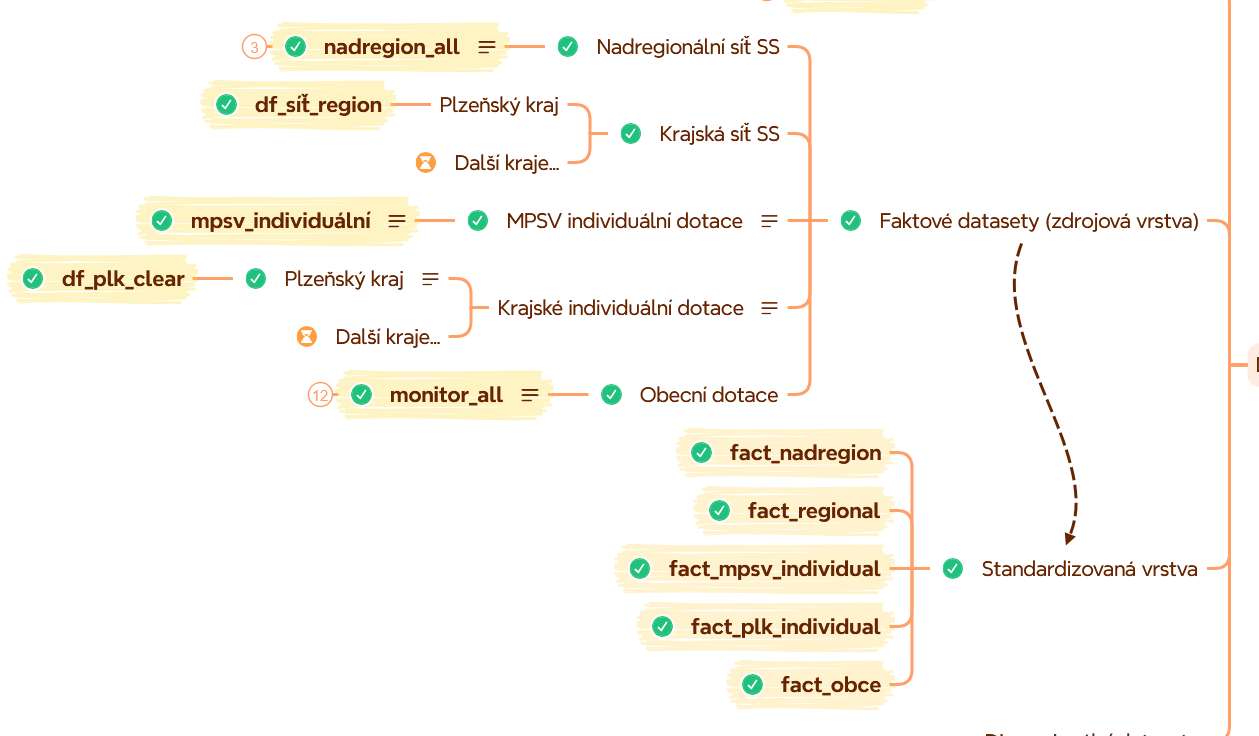

## 2.3 Standardizace

### 2.3.1 Vytvoření tabulky, která pro každý DF popisuje obsah a dostupné klíče.** 

In [153]:
data_catalog = pd.DataFrame({
    "dataset": [
        "nadregion_all",
        "síť_region",
        "mpsv_individuální",
        "df_plk_clear",
        "monitor_all"
    ],
    "instituce": [
        "MPSV",
        "Plzeňský kraj / krajská síť",
        "MPSV",
        "Plzeňský kraj",
        "obce"
    ],
    "uroven": [
        "stát",
        "krajská / nadregionální síť",
        "stát",
        "kraj",
        "obec"
    ],
    "hlavni_otazka": [
        "Podpora nadregionálních služeb",
        "Podpora služeb v regionální síti",
        "Individuální dotace MPSV",
        "Individuální dotace kraje",
        "Výdaje obcí na sociální oblast / služby"
    ]
})

In [154]:
# Výpis struktury všech DF
# Tím zjišťujeme zejména:
# zda máme všude rok;
# zda existuje IČO;
# zda existuje identifikátor sociální služby;
# zda máme druh služby;
# zda je částka skutečně číslo;
# zda se území vztahuje k sídlu poskytovatele, místu poskytování služby, nebo k obci, která peníze vydala.
# Poslední bod je metodicky zásadní: obec, která financuje, nemusí být obcí, kde je služba poskytována. V dashboardu proto nesmíme tyto dvě územní role zaměnit.

dfs = {
    "nadregion_all": nadregion_all,
    "df_síť_region": df_síť_region,
    "mpsv_individuální": mpsv_individuální,
    "df_plk_clear": df_plk_clear,
    "monitor_all": monitor_all
}

for name, df in dfs.items():
    print(f"\n{'=' * 70}")
    print(name)
    print(f"Řádky: {len(df):,} | Sloupce: {df.shape[1]}")
    display(df.head(3))
    display(pd.DataFrame({
        "sloupec": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "n_null": df.isna().sum().values,
        "n_unique": df.nunique(dropna=True).values
    }))


nadregion_all
Řádky: 1,174 | Sloupce: 12


,Název poskytovatele,IČO,ID služby,Druh služby,Přidělená dotace,Rok,Zdrojový soubor,kraj,kraj_regionalni_sit,kraje,pocet_kraju,status_kraje
0,"ADVAITA, z. ú.",65635591,4142726,služby následné péče,1 520 000 Kč,2020,nadregion_2020.csv,Liberecký kraj,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj
1,"ADVAITA, z. ú.",65635591,4853448,terapeutické komunity,4 500 000 Kč,2020,nadregion_2020.csv,Liberecký kraj,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj
2,"Anděl Strážný, z.ú.",2771527,8384795,tísňová péče,11 369 215 Kč,2020,nadregion_2020.csv,Liberecký kraj,Liberecký kraj,NaN,NaN,jednoznačně přiřazený kraj


,sloupec,dtype,n_null,n_unique
0,Název poskytovatele,object,0,168
1,IČO,string,0,121
2,ID služby,string,0,238
3,Druh služby,object,0,29
4,Přidělená dotace,object,0,1168
5,Rok,int64,0,6
6,Zdrojový soubor,object,0,6
7,kraj,object,0,15
8,kraj_regionalni_sit,object,97,14
9,kraje,object,1174,0



df_síť_region
Řádky: 59,863 | Sloupce: 224


,ID služby,IČO,Název poskytovatele,Druh služby,forma,Rok,Přidělená dotace,kraj,orp_prvni,orp_vetsinovy,orp_se_lisi,obec_prvni,stav_prirazeni,pocet_zarizeni,pocet_obci,pocet_orp,vsechna_orp,kapacita,ORP_Aš,ORP_Benešov,ORP_Beroun,ORP_Blansko,ORP_Blatná,ORP_Blovice,ORP_Bohumín,ORP_Boskovice,ORP_Brandýs nad Labem-Stará Boleslav,ORP_Brno,ORP_Broumov,ORP_Bruntál,ORP_Bučovice,ORP_Bystřice nad Pernštejnem,ORP_Bystřice pod Hostýnem,ORP_Bílina,ORP_Bílovec,ORP_Břeclav,ORP_Cheb,ORP_Chomutov,ORP_Chotěboř,ORP_Chrudim,ORP_Dačice,ORP_Dobruška,ORP_Dobříš,ORP_Domažlice,ORP_Dvůr Králové nad Labem,ORP_Děčín,ORP_Frenštát pod Radhoštěm,ORP_Frýdek-Místek,ORP_Frýdlant,ORP_Frýdlant nad Ostravicí,ORP_Havlíčkův Brod,ORP_Havířov,ORP_Hlinsko,ORP_Hlučín,ORP_Hodonín,ORP_Holešov,ORP_Holice,ORP_Horažďovice,ORP_Horšovský Týn,ORP_Hořice,ORP_Hořovice,ORP_Hradec Králové,ORP_Hranice,ORP_Humpolec,ORP_Hustopeče,ORP_Ivančice,ORP_Jablonec nad Nisou,ORP_Jablunkov,ORP_Jaroměř,ORP_Jeseník,ORP_Jihlava,ORP_Jilemnice,ORP_Jindřichův Hradec,ORP_Jičín,ORP_Kadaň,ORP_Kaplice,ORP_Karlovy Vary,ORP_Karviná,ORP_Kladno,ORP_Klatovy,ORP_Kolín,ORP_Konice,ORP_Kopřivnice,ORP_Kostelec nad Orlicí,ORP_Kralovice,ORP_Kralupy nad Vltavou,ORP_Kraslice,ORP_Kravaře,ORP_Krnov,ORP_Kroměříž,ORP_Králíky,ORP_Kutná Hora,ORP_Kuřim,ORP_Kyjov,ORP_Lanškroun,ORP_Liberec,ORP_Lipník nad Bečvou,ORP_Litomyšl,ORP_Litoměřice,ORP_Litovel,ORP_Litvínov,ORP_Louny,ORP_Lovosice,ORP_Luhačovice,ORP_Lysá nad Labem,ORP_Mariánské Lázně,ORP_Mikulov,ORP_Milevsko,ORP_Mladá Boleslav,ORP_Mnichovo Hradiště,ORP_Mohelnice,ORP_Moravská Třebová,ORP_Moravské Budějovice,ORP_Moravský Krumlov,ORP_Most,ORP_Mělník,ORP_Nepomuk,ORP_Neratovice,ORP_Nová Paka,ORP_Nové Město na Moravě,ORP_Nové Město nad Metují,ORP_Nový Bor,ORP_Nový Bydžov,ORP_Nový Jičín,ORP_Nymburk,ORP_Náchod,ORP_Náměšť nad Oslavou,ORP_Nýřany,ORP_Odry,ORP_Olomouc,ORP_Opava,ORP_Orlová,ORP_Ostrava,ORP_Ostrov,ORP_Otrokovice,ORP_Pacov,ORP_Pardubice,ORP_Pelhřimov,ORP_Plzeň,ORP_Podbořany,ORP_Poděbrady,ORP_Pohořelice,ORP_Polička,ORP_Prachatice,ORP_Praha,ORP_Prostějov,ORP_Písek,ORP_Přelouč,ORP_Přerov,ORP_Přeštice,ORP_Příbram,ORP_Rakovník,ORP_Rokycany,ORP_Rosice,ORP_Roudnice nad Labem,ORP_Rožnov pod Radhoštěm,ORP_Rumburk,ORP_Rychnov nad Kněžnou,ORP_Rýmařov,ORP_Sedlčany,ORP_Semily,ORP_Slaný,ORP_Slavkov u Brna,ORP_Soběslav,ORP_Sokolov,ORP_Stod,ORP_Strakonice,ORP_Stříbro,ORP_Sušice,ORP_Svitavy,ORP_Světlá nad Sázavou,ORP_Tachov,ORP_Tanvald,ORP_Telč,ORP_Teplice,ORP_Tišnov,ORP_Trhové Sviny,ORP_Trutnov,ORP_Turnov,ORP_Tábor,ORP_Týn nad Vltavou,ORP_Třeboň,ORP_Třebíč,ORP_Třinec,ORP_Uherské Hradiště,ORP_Uherský Brod,ORP_Uničov,ORP_Valašské Klobouky,ORP_Valašské Meziříčí,ORP_Varnsdorf,ORP_Velké Meziříčí,ORP_Veselí nad Moravou,ORP_Vimperk,ORP_Vizovice,ORP_Vlašim,ORP_Vodňany,ORP_Votice,ORP_Vrchlabí,ORP_Vsetín,ORP_Vysoké Mýto,ORP_Vyškov,ORP_Vítkov,ORP_Zlín,ORP_Znojmo,ORP_Zábřeh,ORP_Ústí nad Labem,ORP_Ústí nad Orlicí,ORP_Černošice,ORP_Česká Lípa,ORP_Česká Třebová,ORP_České Budějovice,ORP_Český Brod,ORP_Český Krumlov,ORP_Český Těšín,ORP_Čáslav,ORP_Říčany,ORP_Šlapanice,ORP_Šternberk,ORP_Šumperk,ORP_Žamberk,ORP_Žatec,ORP_Železný Brod,ORP_Židlochovice,ORP_Žďár nad Sázavou
0,4291112,49367404,Kolpingova rodina Praha 8,azylové domy,Pobytová,2010,830000.0,Hlavní město Praha,Praha,Praha,False,Praha,jednoznacne,1,1,1,Praha,22,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False

...

,Název poskytovatele,IČO,Název služby,ID služby,Druh služby,Přidělená dotace,Poskytovatel_původní,kraj,kraj_regionalni_sit,kraje,pocet_kraju,status_kraje
0,15. přední hlídka Royal Rangers Mariánské Lázně,68782004,Středisko Víteček,4003834,Sociálně terapeutické dílny,"6 190 106,00",15. přední hlídka Royal Rangers \nMariánské Lázně,Plzeňský kraj,Plzeňský kraj,NaN,NaN,jednoznačně přiřazený kraj
1,15. přední hlídka Royal Rangers Mariánské Lázně,68782004,Středisko Víteček - Osobní \nasistence,4397816,Osobní asistence,"6 174 796,00",15. přední hlídka Royal Rangers \nMariánské Lázně,Plzeňský kraj,Plzeňský kraj,NaN,NaN,jednoznačně přiřazený kraj
2,Diakonie ČCE - středisko Západní Čechy,45331154,Jdeme dál pro osoby s \npostižením,3764767,Sociální rehabilitace,"13 013 064,00",Diakonie ČCE - středisko Západní \nČechy,Plzeňský kraj,Plzeňský kraj,NaN,NaN,jednoznačně přiřazený kraj


,sloupec,dtype,n_null,n_unique
0,Název poskytovatele,string,0,14
1,IČO,string,0,14
2,Název služby,object,0,26
3,ID služby,string,0,27
4,Druh služby,object,0,7
5,Přidělená dotace,object,0,27
6,Poskytovatel_původní,object,0,14
7,kraj,object,0,2
8,kraj_regionalni_sit,object,1,1
9,kraje,object,27,0



monitor_all
Řádky: 7,838,192 | Sloupce: 20


,vykaz,tabulka_vykazu,fiskalni_obdobi,ucetni_jednotka,IČO,kraj,nuts,typ_rozpolozky,paragraf,položka,rozpocet_schvaleny,rozpocet_po_zmenach,skutecnost,rok,zdrojovy_soubor,priznak_zkopirovano,paragraf_kod,druh_sluzby,kraj_kod,kraj_nazev
0,051,100.0,2020012,1.000016e+09,75084911,Střední Morava,CZ07,2,0.0,4116.0,30500000.0,45884650.00,45681650.00,2020,monitor_2020.csv,NaN,0000,Pro příjmy (technický záznam),CZ07,NaN
1,051,100.0,2020012,1.000016e+09,75084911,Střední Morava,CZ07,2,0.0,4122.0,25435000.0,25435000.00,15484650.00,2020,monitor_2020.csv,NaN,0000,Pro příjmy (technický záznam),CZ07,NaN
2,051,100.0,2020012,1.000016e+09,75084911,Střední Morava,CZ07,2,0.0,4216.0,0.0,49534722.58,49534722.58,2020,monitor_2020.csv,NaN,0000,Pro příjmy (technický záznam),CZ07,NaN


,sloupec,dtype,n_null,n_unique
0,vykaz,object,0,2
1,tabulka_vykazu,float64,6,2
2,fiskalni_obdobi,int64,0,7
3,ucetni_jednotka,float64,6,7019
4,IČO,int64,0,7020
5,kraj,object,6,21
6,nuts,object,6,97
7,typ_rozpolozky,int64,0,3
8,paragraf,float64,6,451
9,položka,float64,6,432


### 2.3.2 Sjednocení názvů a formátů

Je užitečné vytvořit několik pomocných funkcí. Nejdříve standardizace textu, IČO, roku a částky.

In [155]:
import pandas as pd
import numpy as np
import re
import unicodedata

def clean_text(x):
    if pd.isna(x):
        return pd.NA
    
    x = str(x).strip()
    x = unicodedata.normalize("NFKC", x)
    x = re.sub(r"\s+", " ", x)
    
    return x if x else pd.NA


def clean_ico(x):
    if pd.isna(x):
        return pd.NA
    
    digits = re.sub(r"\D", "", str(x))
    
    if digits == "":
        return pd.NA
    
    return digits.zfill(8)


def clean_year(x):
    if pd.isna(x):
        return pd.NA
    
    try:
        return int(float(x))
    except (TypeError, ValueError):
        return pd.NA


def clean_amount(x):
    if pd.isna(x):
        return pd.NA
    
    if isinstance(x, str):
        x = x.replace("\xa0", "")
        x = x.replace(" ", "")
        x = x.replace("Kč", "")
        x = x.replace(",", ".")
    
    return pd.to_numeric(x, errors="coerce")

### 2.3.3 Převod každého zdroje na společné schéma

#### fact_nadregion (zdroj= nadregion_all)

In [156]:
# Standardizace DF nadregion

fact_nadregion = (
    nadregion_all
    .rename(columns={
        "Rok": "rok",
        "IČO": "ico",
        "Název poskytovatele": "nazev_poskytovatele",
        "ID služby": "id_sluzby",
        "Druh služby": "druh_sluzby",
        "Přidělená dotace": "castka_kc"
    })
    .copy()
)

fact_nadregion["zdroj_financovani"] = "MPSV – nadregionální síť"
fact_nadregion["nazev_sluzby"] = pd.NA

fact_nadregion = fact_nadregion[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj",
        "status_kraje"
    ]
].copy()

In [157]:
display(fact_nadregion.head())
print(fact_nadregion.columns.tolist())

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4142726,<NA>,služby následné péče,1 520 000 Kč,Liberecký kraj,jednoznačně přiřazený kraj
1,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4853448,<NA>,terapeutické komunity,4 500 000 Kč,Liberecký kraj,jednoznačně přiřazený kraj
2,2020,MPSV – nadregionální síť,2771527,"Anděl Strážný, z.ú.",8384795,<NA>,tísňová péče,11 369 215 Kč,Liberecký kraj,jednoznačně přiřazený kraj
3,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,4397935,<NA>,odlehčovací služby,12 034 440 Kč,Moravskoslezský kraj,jednoznačně přiřazený kraj
4,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,8033161,<NA>,odborné sociální poradenství,6 849 578 Kč,Moravskoslezský kraj,jednoznačně přiřazený kraj


['rok', 'zdroj_financovani', 'ico', 'nazev_poskytovatele', 'id_sluzby', 'nazev_sluzby', 'druh_sluzby', 'castka_kc', 'kraj', 'status_kraje']


In [158]:
fact_nadregion["castka_kc"] = (
    fact_nadregion["castka_kc"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace("Kč", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

fact_nadregion["castka_kc"] = pd.to_numeric(
    fact_nadregion["castka_kc"],
    errors="coerce"
)

In [159]:
print(fact_nadregion["castka_kc"].dtype)

display(
    fact_nadregion[
        ["rok", "nazev_poskytovatele", "druh_sluzby", "castka_kc"]
    ].head(3)
)

print(
    f"Počet neplatných / chybějících částek: "
    f"{fact_nadregion['castka_kc'].isna().sum():,}"
)

print(
    f"Celková částka: "
    f"{fact_nadregion['castka_kc'].sum():,.0f} Kč"
)

Float64


,rok,nazev_poskytovatele,druh_sluzby,castka_kc
0,2020,"ADVAITA, z. ú.",služby následné péče,1520000.0
1,2020,"ADVAITA, z. ú.",terapeutické komunity,4500000.0
2,2020,"Anděl Strážný, z.ú.",tísňová péče,11369215.0


Počet neplatných / chybějících částek: 0
Celková částka: 7,259,121,818 Kč


#### fact_mpsv_individual (zdroj= mpsv_individuální)

In [160]:
fact_mpsv_individual = (
    mpsv_individuální
    .rename(columns={
        "Rok": "rok",
        "IČO": "ico",
        "Název poskytovatele": "nazev_poskytovatele",
        "ID služby": "id_sluzby",
        "Druh služby": "druh_sluzby",
        "Přidělená dotace": "castka_kc"
    })
    .copy()
)

fact_mpsv_individual["zdroj_financovani"] = "MPSV – individuální dotace"
fact_mpsv_individual["nazev_sluzby"] = pd.NA

fact_mpsv_individual = fact_mpsv_individual[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj",
        "status_kraje"
    ]
].copy()

In [161]:
fact_mpsv_individual["castka_kc"] = (
    fact_mpsv_individual["castka_kc"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace("Kč", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

fact_mpsv_individual["castka_kc"] = pd.to_numeric(
    fact_mpsv_individual["castka_kc"],
    errors="coerce"
)

In [162]:
print(fact_mpsv_individual.columns.tolist())

print(
    f"Počet neplatných / chybějících částek: "
    f"{fact_mpsv_individual['castka_kc'].isna().sum():,}"
)

print(
    f"Celková částka: "
    f"{fact_mpsv_individual['castka_kc'].sum():,.0f} Kč"
)

display(fact_mpsv_individual.head(3))

['rok', 'zdroj_financovani', 'ico', 'nazev_poskytovatele', 'id_sluzby', 'nazev_sluzby', 'druh_sluzby', 'castka_kc', 'kraj', 'status_kraje']
Počet neplatných / chybějících částek: 0
Celková částka: 8,090,151,633 Kč


,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2020,MPSV – individuální dotace,27053679,A DOMA z.s.,1408443,<NA>,osobní asistence,154184.0,Hlavní město Praha,jednoznačně přiřazený kraj
1,2020,MPSV – individuální dotace,2672910,"ABAPO, s.r.o.",4200668,<NA>,osobní asistence,311140.0,Moravskoslezský kraj,jednoznačně přiřazený kraj
2,2020,MPSV – individuální dotace,24240931,"AC Facility, s.r.o.",6431239,<NA>,pečovatelská služba,381738.0,Neurčeno,nenalezeno v regionální síti


#### fact_df_plk_individual (zdroj= df_plk_clear)

In [163]:
# Doplňuji chybějící údaj - dotace jsou za roky 2023 - 2025, jedno dotační období, doplňuji tedy manuálně rok 2023
df_plk_clear["Rok"] = 2023

In [164]:
print(df_plk_clear["Rok"].value_counts(dropna=False))

Rok
2023    27
Name: count, dtype: int64


In [165]:
fact_plk_individual = (
    df_plk_clear
    .rename(columns={
        "Rok": "rok",
        "IČO": "ico",
        "Název poskytovatele": "nazev_poskytovatele",
        "ID služby": "id_sluzby",
        "Název služby": "nazev_sluzby",
        "Druh služby": "druh_sluzby",
        "Přidělená dotace": "castka_kc"
    })
    .copy()
)

fact_plk_individual["zdroj_financovani"] = (
    "Plzeňský kraj – individuální dotace"
)

fact_plk_individual = fact_plk_individual[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj",
        "status_kraje"
    ]
].copy()

In [166]:
fact_plk_individual["castka_kc"] = (
    fact_plk_individual["castka_kc"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace("Kč", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

fact_plk_individual["castka_kc"] = pd.to_numeric(
    fact_plk_individual["castka_kc"],
    errors="coerce"
)

In [167]:
print(fact_plk_individual.columns.tolist())

print(
    f"Počet neplatných / chybějících částek: "
    f"{fact_plk_individual['castka_kc'].isna().sum():,}"
)

print(
    f"Celková částka: "
    f"{fact_plk_individual['castka_kc'].sum():,.0f} Kč"
)

display(fact_plk_individual.head(3))

['rok', 'zdroj_financovani', 'ico', 'nazev_poskytovatele', 'id_sluzby', 'nazev_sluzby', 'druh_sluzby', 'castka_kc', 'kraj', 'status_kraje']
Počet neplatných / chybějících částek: 0
Celková částka: 286,400,260 Kč


,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2023,Plzeňský kraj – individuální dotace,68782004,15. přední hlídka Royal Rangers Mariánské Lázně,4003834,Středisko Víteček,Sociálně terapeutické dílny,6190106.0,Plzeňský kraj,jednoznačně přiřazený kraj
1,2023,Plzeňský kraj – individuální dotace,68782004,15. přední hlídka Royal Rangers Mariánské Lázně,4397816,Středisko Víteček - Osobní \nasistence,Osobní asistence,6174796.0,Plzeňský kraj,jednoznačně přiřazený kraj
2,2023,Plzeňský kraj – individuální dotace,45331154,Diakonie ČCE - středisko Západní Čechy,3764767,Jdeme dál pro osoby s \npostižením,Sociální rehabilitace,13013064.0,Plzeňský kraj,jednoznačně přiřazený kraj


#### fact_regional (zdroj = df_síť_region)

In [168]:
fact_regional = (
    df_síť_region
    .rename(columns={
        "Rok": "rok",
        "IČO": "ico",
        "Název poskytovatele": "nazev_poskytovatele",
        "ID služby": "id_sluzby",
        "Druh služby": "druh_sluzby",
        "Přidělená dotace": "castka_kc"
    })
    .copy()
)

fact_regional["zdroj_financovani"] = "Regionální síť sociálních služeb"

# Název konkrétní služby zde podle výpisu není k dispozici.
fact_regional["nazev_sluzby"] = pd.NA

# Tento DF už má sloupec "forma"; zatím jej jen zachováme.
# Do sjednoceného finančního schématu jej přidáme všem zdrojům později.

In [169]:
fact_regional = fact_regional[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj"
    ]
].copy()

In [170]:
fact_regional["status_kraje"] = "přímo ve zdrojovém datasetu"

In [171]:
fact_regional = fact_regional[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj",
        "status_kraje"
    ]
].copy()

In [172]:
fact_regional["castka_kc"] = (
    fact_regional["castka_kc"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace("Kč", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

fact_regional["castka_kc"] = pd.to_numeric(
    fact_regional["castka_kc"],
    errors="coerce"
)

In [173]:
print(fact_regional.columns.tolist())

print(f"Počet řádků: {len(fact_regional):,}")

print(
    f"Počet neplatných / chybějících částek: "
    f"{fact_regional['castka_kc'].isna().sum():,}"
)

print(
    f"Celková částka: "
    f"{fact_regional['castka_kc'].sum():,.0f} Kč"
)

display(fact_regional.head(3))

['rok', 'zdroj_financovani', 'ico', 'nazev_poskytovatele', 'id_sluzby', 'nazev_sluzby', 'druh_sluzby', 'castka_kc', 'kraj', 'status_kraje']
Počet řádků: 59,863
Počet neplatných / chybějících částek: 0
Celková částka: 231,763,758,211 Kč


,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2010,Regionální síť sociálních služeb,49367404,Kolpingova rodina Praha 8,4291112,<NA>,azylové domy,830000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
1,2010,Regionální síť sociálních služeb,42884861,EMAUZY ČR,9439661,<NA>,azylové domy,1232000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
2,2010,Regionální síť sociálních služeb,49625624,Proxima Sociale o.p.s.,2750905,<NA>,azylové domy,340000.0,Hlavní město Praha,přímo ve zdrojovém datasetu


#### fact_obce (zdroj = monitor_all)

In [174]:
fact_obce = (
    monitor_all
    .rename(columns={
        "IČO": "ico",
        "ucetni_jednotka": "nazev_poskytovatele",
        "skutecnost": "castka_kc"
    })
    .copy()
)

fact_obce["zdroj_financovani"] = "Obecní výdaje – MONITOR"
fact_obce["id_sluzby"] = pd.NA
fact_obce["nazev_sluzby"] = pd.NA
fact_obce["druh_sluzby"] = pd.NA
fact_obce["status_kraje"] = "přímo ve zdrojovém datasetu"

In [175]:
fact_obce = fact_obce[
    [
        "rok",
        "zdroj_financovani",
        "ico",
        "nazev_poskytovatele",
        "id_sluzby",
        "nazev_sluzby",
        "druh_sluzby",
        "castka_kc",
        "kraj",
        "status_kraje"
    ]
].copy()

In [176]:
fact_obce["castka_kc"] = pd.to_numeric(
    fact_obce["castka_kc"],
    errors="coerce"
)

In [177]:
import numpy as np
import pandas as pd

velikost_bloku = 200_000
n = len(fact_obce)

castka_numeric = np.empty(n, dtype="float64")

for start in range(0, n, velikost_bloku):
    end = min(start + velikost_bloku, n)
    
    castka_numeric[start:end] = pd.to_numeric(
        fact_obce["castka_kc"].iloc[start:end],
        errors="coerce"
    )
    
    print(f"Hotovo: {end:,} / {n:,}")

fact_obce["castka_kc"] = castka_numeric

Hotovo: 200,000 / 7,838,192
Hotovo: 400,000 / 7,838,192
Hotovo: 600,000 / 7,838,192
Hotovo: 800,000 / 7,838,192
Hotovo: 1,000,000 / 7,838,192
Hotovo: 1,200,000 / 7,838,192
Hotovo: 1,400,000 / 7,838,192
Hotovo: 1,600,000 / 7,838,192
Hotovo: 1,800,000 / 7,838,192
Hotovo: 2,000,000 / 7,838,192
Hotovo: 2,200,000 / 7,838,192
Hotovo: 2,400,000 / 7,838,192
Hotovo: 2,600,000 / 7,838,192
Hotovo: 2,800,000 / 7,838,192
Hotovo: 3,000,000 / 7,838,192
Hotovo: 3,200,000 / 7,838,192
Hotovo: 3,400,000 / 7,838,192
Hotovo: 3,600,000 / 7,838,192
Hotovo: 3,800,000 / 7,838,192
Hotovo: 4,000,000 / 7,838,192
Hotovo: 4,200,000 / 7,838,192
Hotovo: 4,400,000 / 7,838,192
Hotovo: 4,600,000 / 7,838,192
Hotovo: 4,800,000 / 7,838,192
Hotovo: 5,000,000 / 7,838,192
Hotovo: 5,200,000 / 7,838,192
Hotovo: 5,400,000 / 7,838,192
Hotovo: 5,600,000 / 7,838,192
Hotovo: 5,800,000 / 7,838,192
Hotovo: 6,000,000 / 7,838,192
Hotovo: 6,200,000 / 7,838,192
Hotovo: 6,400,000 / 7,838,192
Hotovo: 6,600,000 / 7,838,192
Hotovo: 6,800,000 

In [178]:
print(f"Datový typ: {fact_obce['castka_kc'].dtype}")

print(
    f"Počet neplatných / chybějících částek: "
    f"{fact_obce['castka_kc'].isna().sum():,}"
)

print(
    f"Celková částka: "
    f"{fact_obce['castka_kc'].sum():,.0f} Kč"
)

Datový typ: float64
Počet neplatných / chybějících částek: 11,267
Celková částka: 19,479,997,428,607 Kč


In [179]:
fact_obce.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2020,Obecní výdaje – MONITOR,75084911,1.000016e+09,<NA>,<NA>,<NA>,45681650.00,Střední Morava,přímo ve zdrojovém datasetu
1,2020,Obecní výdaje – MONITOR,75084911,1.000016e+09,<NA>,<NA>,<NA>,15484650.00,Střední Morava,přímo ve zdrojovém datasetu
2,2020,Obecní výdaje – MONITOR,75084911,1.000016e+09,<NA>,<NA>,<NA>,49534722.58,Střední Morava,přímo ve zdrojovém datasetu
3,2020,Obecní výdaje – MONITOR,75084911,1.000016e+09,<NA>,<NA>,<NA>,27810.00,Střední Morava,přímo ve zdrojovém datasetu
4,2020,Obecní výdaje – MONITOR,75084911,1.000016e+09,<NA>,<NA>,<NA>,29421.11,Střední Morava,přímo ve zdrojovém datasetu


## 2.4 Oprava velká písmena a duplikáty

In [180]:
import unicodedata
import pandas as pd

def standardizuj_druh_sluzby(df, sloupec="druh_sluzby"):
    vysledek = df.copy()

    if sloupec not in vysledek.columns:
        raise KeyError(
            f"V dataframe chybí sloupec '{sloupec}'. "
            f"Dostupné sloupce: {list(vysledek.columns)}"
        )

    hodnota = vysledek[sloupec].astype("string")

    # Sjednocení Unicode, nezalomitelných mezer a vícenásobných mezer.
    hodnota = hodnota.map(
        lambda x: unicodedata.normalize("NFC", x) if pd.notna(x) else pd.NA
    )

    hodnota = (
        hodnota
        .str.replace("\u00A0", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.capitalize()
    )

    vysledek[sloupec] = hodnota

    return vysledek

In [181]:
fact_nadregion = standardizuj_druh_sluzby(fact_nadregion)

fact_mpsv_individual = standardizuj_druh_sluzby(fact_mpsv_individual)

fact_regional = standardizuj_druh_sluzby(fact_regional)

fact_plk_individual = standardizuj_druh_sluzby(fact_plk_individual)

## 2.5 Další zvláštní zpracování MONITORu: výdaje obcí

Data z MONITORu nejsou stejným typem dat jako dotační rozhodnutí MPSV, krajů nebo regionálních sítí sociálních služeb.

Zatímco ostatní datasety obsahují přidělené dotace konkrétním poskytovatelům a registrovaným sociálním službám, MONITOR obsahuje účetní a rozpočtové řádky veřejných subjektů. Jeden řádek MONITORu může představovat například:

- výdaj obce na konkrétního poskytovatele;
- dotaci organizaci;
- provozní náklad obce;
- výdaj zatříděný podle rozpočtového paragrafu a položky;
- agregovaný výdaj v sociální oblasti bez vazby na konkrétní registrovanou službu.

Proto se data MONITORu **nespojují přímo** s dotačními daty služeb do dataframe `fact_financovani_sluzeb`.

V této části vznikají samostatné datové tabulky:

- `fact_vydaje_obci` — standardizované účetní a rozpočtové řádky z MONITORu;
- `fact_vydaje_obci_kraj` — pouze řádky, u kterých lze určit kraj;
- `obecni_vydaje_kraj` — kontrolní agregace výdajů na úroveň `rok × kraj`.

Sloupec `castka_kc` zde představuje hodnotu `skutecnost` z MONITORu. V této fázi obsahuje tabulka všechny dostupné rozpočtové položky, nikoli pouze sociální služby.

Před vytvořením dashboardu sociálních výdajů je nutné data dále filtrovat podle rozpočtové skladby, zejména podle sloupce `paragraf`, případně podle `polozka` a `typ_rozpolozky`. Teprve poté vznikne analytický dataset sociálních výdajů obcí, například `fact_obce_socialni`.

Kraj je v datech MONITORu uložen jako kód CZ-NUTS 3, například `CZ032` pro Plzeňský kraj. Pro srovnání s dotačními daty je vytvořen pomocný sloupec `kraj_nazev` s textovým názvem kraje.

Územní přiřazení není k dispozici u všech řádků MONITORu. Do krajských souhrnů jsou proto zařazeny pouze řádky s vyplněným a přeloženým krajem. Tento filtr pokrývá přibližně 99,9 % celkové finanční hodnoty dat, přestože pokrývá přibližně 32,1 % všech účetních řádků.

In [182]:
fact_dotace_sluzby = pd.concat(
    [
        fact_nadregion,
        fact_regional,
        fact_mpsv_individual,
        fact_plk_individual
    ],
    ignore_index=True
)

fact_vydaje_obci = fact_obce.copy()

In [183]:
obecni_vydaje_kraj = (
    fact_obce
    .groupby(["rok", "kraj"], as_index=False)
    .agg(
        obecni_vydaje_kc=("castka_kc", "sum"),
        pocet_ucetnich_jednotek=("ico", "nunique")
    )
)

display(obecni_vydaje_kraj.head(20))

,rok,kraj,obecni_vydaje_kc,pocet_ucetnich_jednotek
0,2020,Hlavní město Praha,5.040446e+11,1
1,2020,Jihomoravský kraj,3.050511e+11,795
2,2020,Jihovýchod,1.106105e+08,1
3,2020,Jihozápad,2.184658e+08,1
4,2020,Jihočeský kraj,1.394296e+11,677
5,2020,Karlovarský kraj,6.450180e+10,148
6,2020,Kraj Vysočina,1.190246e+11,765
7,2020,Královéhradecký kraj,1.152395e+11,496
8,2020,Liberecký kraj,8.400831e+10,243
9,2020,Moravskoslezsko,2.079109e+08,1


In [184]:
display(
    fact_obce[
        [
            "rok",
            "ico",
            "nazev_poskytovatele",
            "kraj",
            "castka_kc"
        ]
    ].head(20)
)

print("Typ ico:", fact_obce["ico"].dtype)
print("Typ nazev_poskytovatele:", fact_obce["nazev_poskytovatele"].dtype)

print("\nUnikátní hodnoty ico v prvních řádcích:")
display(fact_obce["ico"].drop_duplicates().head(20))

print("\nUnikátní hodnoty nazev_poskytovatele v prvních řádcích:")
display(fact_obce["nazev_poskytovatele"].drop_duplicates().head(20))

,rok,ico,nazev_poskytovatele,kraj,castka_kc
0,2020,75084911,1.000016e+09,Střední Morava,45681650.00
1,2020,75084911,1.000016e+09,Střední Morava,15484650.00
2,2020,75084911,1.000016e+09,Střední Morava,49534722.58
3,2020,75084911,1.000016e+09,Střední Morava,27810.00
4,2020,75084911,1.000016e+09,Střední Morava,29421.11
5,2020,75084911,1.000016e+09,Střední Morava,934.52
6,2020,75084911,1.000016e+09,Střední Morava,2226.02
7,2020,75084911,1.000016e+09,Střední Morava,31823081.35
8,2020,75084911,1.000016e+09,Střední Morava,32435.22
9,2020,75084911,1.000016e+09,Střední Morava,3736044.40


Typ ico: int64
Typ nazev_poskytovatele: float64

Unikátní hodnoty ico v prvních řádcích:


0       75084911
52      75086999
112     75082721
162        64581
181     75082241
272     75082314
323     75082616
378     75082136
3245      253936
3250      253979
3308      253901
3837      254169
3853      254274
3890      254304
3965      883611
3994      253928
4039      253952
4093      253961
4176      254011
4207      254037
Name: ico, dtype: int64


Unikátní hodnoty nazev_poskytovatele v prvních řádcích:


0       1.000016e+09
52      1.000003e+09
112     1.000008e+09
162     1.000018e+09
181     1.000011e+09
272     1.000002e+09
323     1.000017e+09
378     1.000008e+09
3245    1.000005e+09
3250    1.000005e+09
3308    1.000005e+09
3837    1.000005e+09
3853    1.000005e+09
3890    1.000005e+09
3965    1.000005e+09
3994    1.000005e+09
4039    1.000005e+09
4093    1.000005e+09
4176    1.000005e+09
4207    1.000005e+09
Name: nazev_poskytovatele, dtype: float64

In [185]:
fact_obce = fact_obce.rename(
    columns={
        "nazev_poskytovatele": "kod_ucetni_jednotky"
    }
)

fact_obce["ico"] = (
    fact_obce["ico"]
    .astype("Int64")
    .astype("string")
    .str.zfill(8)
)

fact_obce["kod_ucetni_jednotky"] = (
    fact_obce["kod_ucetni_jednotky"]
    .astype("Int64")
    .astype("string")
)

In [186]:
print(fact_obce[["ico", "kod_ucetni_jednotky"]].dtypes)

display(
    fact_obce[
        [
            "rok",
            "ico",
            "kod_ucetni_jednotky",
            "kraj",
            "castka_kc"
        ]
    ].head(10)
)

ico                    string[python]
kod_ucetni_jednotky    string[python]
dtype: object


,rok,ico,kod_ucetni_jednotky,kraj,castka_kc
0,2020,75084911,1000016082,Střední Morava,45681650.00
1,2020,75084911,1000016082,Střední Morava,15484650.00
2,2020,75084911,1000016082,Střední Morava,49534722.58
3,2020,75084911,1000016082,Střední Morava,27810.00
4,2020,75084911,1000016082,Střední Morava,29421.11
5,2020,75084911,1000016082,Střední Morava,934.52
6,2020,75084911,1000016082,Střední Morava,2226.02
7,2020,75084911,1000016082,Střední Morava,31823081.35
8,2020,75084911,1000016082,Střední Morava,32435.22
9,2020,75084911,1000016082,Střední Morava,3736044.40


In [187]:
obecni_vydaje_kraj = (
    fact_obce
    .groupby(["rok", "kraj"], as_index=False)
    .agg(
        obecni_vydaje_kc=("castka_kc", "sum"),
        pocet_ucetnich_jednotek=("ico", "nunique")
    )
)

In [188]:
kraj_map = {
    "CZ010": "Hlavní město Praha",
    "CZ020": "Středočeský kraj",
    "CZ031": "Jihočeský kraj",
    "CZ032": "Plzeňský kraj",
    "CZ041": "Karlovarský kraj",
    "CZ042": "Ústecký kraj",
    "CZ051": "Liberecký kraj",
    "CZ052": "Královéhradecký kraj",
    "CZ053": "Pardubický kraj",
    "CZ063": "Kraj Vysočina",
    "CZ064": "Jihomoravský kraj",
    "CZ071": "Olomoucký kraj",
    "CZ072": "Zlínský kraj",
    "CZ080": "Moravskoslezský kraj"
}

fact_obce["kraj_nazev"] = fact_obce["kraj"].map(kraj_map)

In [189]:
print(
    "Řádky s platným kódem kraje, ale bez názvu:",
    (
        fact_obce["kraj"].notna()
        & fact_obce["kraj_nazev"].isna()
    ).sum()
)

print(
    "Řádky bez kraje už ve zdroji:",
    fact_obce["kraj"].isna().sum()
)

display(
    fact_obce[
        ["kraj", "kraj_nazev"]
    ]
    .value_counts(dropna=False)
    .reset_index(name="pocet_radku")
    .sort_values("kraj")
)

Řádky s platným kódem kraje, ale bez názvu: 7838186
Řádky bez kraje už ve zdroji: 6


,kraj,kraj_nazev,pocet_radku
13,Hlavní město Praha,NaN,19336
1,Jihomoravský kraj,NaN,964633
20,Jihovýchod,NaN,92
15,Jihozápad,NaN,116
2,Jihočeský kraj,NaN,727576
12,Karlovarský kraj,NaN,183817
3,Kraj Vysočina,NaN,708878
6,Královéhradecký kraj,NaN,542539
11,Liberecký kraj,NaN,290995
16,Moravskoslezsko,NaN,106


In [190]:
fact_obce_kraj = fact_obce[
    fact_obce["kraj_nazev"].notna()
].copy()

print(f"Řádků s přiřazeným krajem: {len(fact_obce_kraj):,}")
print(
    f"Podíl řádků s přiřazeným krajem: "
    f"{len(fact_obce_kraj) / len(fact_obce):.1%}"
)
print(
    f"Částka v řádcích s přiřazeným krajem: "
    f"{fact_obce_kraj['castka_kc'].sum():,.0f} Kč"
)
print(
    f"Podíl částky s přiřazeným krajem: "
    f"{fact_obce_kraj['castka_kc'].sum() / fact_obce['castka_kc'].sum():.1%}"
)

Řádků s přiřazeným krajem: 0
Podíl řádků s přiřazeným krajem: 0.0%
Částka v řádcích s přiřazeným krajem: 0 Kč
Podíl částky s přiřazeným krajem: 0.0%


In [191]:
obecni_vydaje_kraj = (
    fact_obce_kraj
    .groupby(["rok", "kraj_nazev"], as_index=False)
    .agg(
        obecni_vydaje_kc=("castka_kc", "sum"),
        pocet_ucetnich_jednotek=("ico", "nunique"),
        pocet_radku=("castka_kc", "size")
    )
    .sort_values(["rok", "kraj_nazev"])
)

display(obecni_vydaje_kraj.head(20))

,rok,kraj_nazev,obecni_vydaje_kc,pocet_ucetnich_jednotek,pocet_radku


In [192]:
obecni_vydaje_kraj = (
    fact_obce_kraj
    .groupby(["rok", "kraj_nazev"], as_index=False)
    .agg(
        obecni_vydaje_kc=("castka_kc", "sum"),
        pocet_ucetnich_jednotek=("ico", "nunique"),
        pocet_radku=("castka_kc", "size")
    )
    .sort_values(["rok", "kraj_nazev"])
    .reset_index(drop=True)
)

display(obecni_vydaje_kraj.head(20))

,rok,kraj_nazev,obecni_vydaje_kc,pocet_ucetnich_jednotek,pocet_radku


In [193]:
pokryti_obce_kraj = pd.DataFrame({
    "ukazatel": [
        "řádky celkem",
        "řádky s přiřazeným krajem",
        "podíl řádků s krajem",
        "částka celkem",
        "částka s přiřazeným krajem",
        "podíl částky s krajem"
    ],
    "hodnota": [
        len(fact_obce),
        len(fact_obce_kraj),
        len(fact_obce_kraj) / len(fact_obce),
        fact_obce["castka_kc"].sum(),
        fact_obce_kraj["castka_kc"].sum(),
        fact_obce_kraj["castka_kc"].sum() / fact_obce["castka_kc"].sum()
    ]
})

display(pokryti_obce_kraj)

,ukazatel,hodnota
0,řádky celkem,7.838192e+06
1,řádky s přiřazeným krajem,0.000000e+00
2,podíl řádků s krajem,0.000000e+00
3,částka celkem,1.948000e+13
4,částka s přiřazeným krajem,0.000000e+00
5,podíl částky s krajem,0.000000e+00


In [194]:
fact_obce_kraj.head()

,rok,zdroj_financovani,ico,kod_ucetni_jednotky,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_nazev


In [195]:
obecni_vydaje_kraj.head()

,rok,kraj_nazev,obecni_vydaje_kc,pocet_ucetnich_jednotek,pocet_radku


## 2.6 Krajská agregace financování sociálních služeb

Dataframe `financovani_kraj` obsahuje souhrn financování sociálních služeb na úrovni:

```text
rok × kraj
```

Vzniká agregací detailního dataframe `fact_financovani_sluzeb`, který spojuje dotační data z těchto zdrojů:

- MPSV – nadregionální síť sociálních služeb;
- MPSV – individuální dotace;
- Plzeňský kraj – individuální dotace;
- regionální síť sociálních služeb.

Každý řádek dataframe `financovani_kraj` představuje souhrn financování sociálních služeb v jednom kraji v jednom roce.

#### Obsažené proměnné

| Sloupec | Význam |
|---|---|
| `rok` | Rok přidělení dotace |
| `kraj` | Kraj, do něhož byla služba přiřazena |
| `dotace_sluzby_kc` | Součet přidělených dotací sociálním službám v Kč |
| `pocet_sluzeb` | Počet unikátních registrovaných sociálních služeb (`id_sluzby`) |
| `pocet_poskytovatelu` | Počet unikátních poskytovatelů sociálních služeb (`ico`) |

Do krajské agregace jsou zahrnuty pouze řádky s jednoznačně určeným krajem. Z agregace jsou vyloučeny služby s hodnotami:

- `Více krajů` — služba působí ve více krajích a její dotaci nelze bez alokačního klíče přiřadit jedinému kraji;
- `Neurčeno` — kraj nebylo možné určit z dostupných dat.

Tím se předchází chybnému násobení nebo nesprávnému územnímu přiřazení dotací.

#### Metodické omezení

Součet `dotace_sluzby_kc` představuje součet položek ze všech zahrnutých dotačních zdrojů. Před interpretací jako „celkové financování služeb v kraji“ je nutné ověřit, zda se jednotlivé zdroje nepřekrývají — například zda krajská dotace nereprezentuje další rozdělení prostředků, které již byly v jiném datasetu zachyceny.

Dataframe slouží jako podklad pro krajské dashboardy a meziroční srovnání financování, počtu služeb a počtu poskytovatelů.

In [196]:
# ============================================================
# KRAJSKÁ AGREGACE
# Hlavní factová tabulka financování sociálních služeb
# ============================================================

# Nová celorepubliková větev krajských individuálních dotací.
# Obsahuje i původních 27 plzeňských záznamů.
# fact_plk_individual sem proto už samostatně NEPŘIDÁVÁME.

fact_krajske_individualni_pro_fact = (
    fact_krajske_individualni_dashboard.copy()
)

# Doplnění sloupce, který mají dosavadní standardizované factové tabulky.
# Pokud není kraj služby ověřený, ponecháváme informaci "Neurčeno".
fact_krajske_individualni_pro_fact["status_kraje"] = np.where(
    fact_krajske_individualni_pro_fact["kraj"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("neurčeno"),
    "neurčený kraj",
    "kraj uvedený ve zdroji"
)

# Hlavní factový dataframe pro dashboardy financování služeb.
# fact_obce sem NEPATŘÍ: tvoří samostatnou větev obecních výdajů.
fact_financovani_sluzeb = pd.concat(
    [
        fact_nadregion,
        fact_mpsv_individual,
        fact_krajske_individualni_pro_fact,
        fact_regional
    ],
    ignore_index=True,
    sort=False
)

In [197]:
# ============================================================
# OPRAVA ROKU: PLZEŇSKÝ KRAJ V KRAJSKÝCH INDIVIDUÁLNÍCH DOTACÍCH
# ============================================================

maska_plzen_bez_roku = (
    fact_krajske_individualni_dashboard["kraj_poskytovatel_dotace"]
    .eq("Plzeňský kraj")
    & fact_krajske_individualni_dashboard["rok"].isna()
)

print(
    "Počet plzeňských řádků bez roku před opravou:",
    maska_plzen_bez_roku.sum()
)

fact_krajske_individualni_dashboard.loc[
    maska_plzen_bez_roku,
    "rok"
] = 2023

fact_krajske_individualni_dashboard["rok"] = pd.to_numeric(
    fact_krajske_individualni_dashboard["rok"],
    errors="coerce"
).astype("Int64")

print(
    "Počet plzeňských řádků bez roku po opravě:",
    (
        fact_krajske_individualni_dashboard.loc[
            fact_krajske_individualni_dashboard[
                "kraj_poskytovatel_dotace"
            ].eq("Plzeňský kraj"),
            "rok"
        ]
        .isna()
        .sum()
    )
)

display(
    fact_krajske_individualni_dashboard
    .loc[
        fact_krajske_individualni_dashboard[
            "kraj_poskytovatel_dotace"
        ].eq("Plzeňský kraj")
    ]
    .groupby("rok", dropna=False)
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .reset_index()
)

Počet plzeňských řádků bez roku před opravou: 0
Počet plzeňských řádků bez roku po opravě: 0


,rok,radku,castka_celkem_kc
0,2023,27,286400260.0


In [198]:
# ============================================================
# KONTROLA: fact_financovani_sluzeb PO DOPLNĚNÍ 14 KRAJŮ
# ============================================================

# ------------------------------------------------------------
# 1. SOUHRN VŠECH ZDROJŮ V HLAVNÍM FACTOVÉM DATAFRAME
# ------------------------------------------------------------

kontrola_zdroju_financovani = (
    fact_financovani_sluzeb
    .groupby("zdroj_financovani", dropna=False)
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum"),
        prvni_rok=("rok", "min"),
        posledni_rok=("rok", "max"),
        pocet_kraju=("kraj", "nunique"),
        chybi_castka=("castka_kc", lambda x: x.isna().sum())
    )
    .reset_index()
    .sort_values("castka_celkem_kc", ascending=False)
)

print("=" * 100)
print("1. KONTROLA ZDROJŮ VE fact_financovani_sluzeb")
print("=" * 100)

display(kontrola_zdroju_financovani)


# ------------------------------------------------------------
# 2. DETAIL NOVÉ VĚTVE: KRAJSKÉ INDIVIDUÁLNÍ DOTACE
# ------------------------------------------------------------

krajske_individualni_v_hlavnim_factu = (
    fact_financovani_sluzeb
    .loc[
        fact_financovani_sluzeb["zdroj_financovani"]
        .eq("Krajské individuální dotace")
    ]
    .copy()
)

kontrola_kraje_rok = (
    krajske_individualni_v_hlavnim_factu
    .groupby(
        [
            "kraj_poskytovatel_dotace",
            "rok"
        ],
        dropna=False
    )
    .agg(
        radku=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum"),
        pocet_sluzeb=("id_sluzby", "nunique"),
        nulove_nebo_zaporne_castky=(
            "castka_kc",
            lambda x: (x <= 0).sum()
        )
    )
    .reset_index()
    .sort_values(
        [
            "kraj_poskytovatel_dotace",
            "rok"
        ]
    )
)

print("\n" + "=" * 100)
print("2. KRAJSKÉ INDIVIDUÁLNÍ DOTACE PODLE KRAJE A ROKU")
print("=" * 100)

display(kontrola_kraje_rok)


# ------------------------------------------------------------
# 3. AUTOMATICKÉ KONTROLNÍ PODMÍNKY
# ------------------------------------------------------------

ocekavany_pocet_radku = 7798
ocekavany_pocet_kraju = 14
ocekavana_castka = 7_788_269_607.30

skutecny_pocet_radku = len(krajske_individualni_v_hlavnim_factu)

skutecny_pocet_kraju = (
    krajske_individualni_v_hlavnim_factu[
        "kraj_poskytovatel_dotace"
    ]
    .nunique()
)

skutecna_castka = (
    krajske_individualni_v_hlavnim_factu["castka_kc"]
    .sum()
)

# Starý samostatný plzeňský zdroj nesmí v hlavní tabulce zůstat.
stare_plzenske_zdroje = (
    fact_financovani_sluzeb["zdroj_financovani"]
    .astype("string")
    .str.contains(
        "Plzeňský kraj.*individuální",
        case=False,
        regex=True,
        na=False
    )
    .sum()
)

vysledky_kontroly = pd.DataFrame(
    [
        {
            "kontrola": "Počet řádků krajských individuálních dotací",
            "ocekavano": ocekavany_pocet_radku,
            "skutecnost": skutecny_pocet_radku,
            "stav": (
                "OK"
                if skutecny_pocet_radku == ocekavany_pocet_radku
                else "KONTROLA NUTNÁ"
            )
        },
        {
            "kontrola": "Počet krajů poskytujících individuální dotace",
            "ocekavano": ocekavany_pocet_kraju,
            "skutecnost": skutecny_pocet_kraju,
            "stav": (
                "OK"
                if skutecny_pocet_kraju == ocekavany_pocet_kraju
                else "KONTROLA NUTNÁ"
            )
        },
        {
            "kontrola": "Celková částka krajských individuálních dotací",
            "ocekavano": ocekavana_castka,
            "skutecnost": skutecna_castka,
            "stav": (
                "OK"
                if np.isclose(
                    skutecna_castka,
                    ocekavana_castka,
                    rtol=0,
                    atol=0.01
                )
                else "KONTROLA NUTNÁ"
            )
        },
        {
            "kontrola": "Starý samostatný plzeňský individuální zdroj",
            "ocekavano": 0,
            "skutecnost": stare_plzenske_zdroje,
            "stav": (
                "OK"
                if stare_plzenske_zdroje == 0
                else "KONTROLA NUTNÁ"
            )
        }
    ]
)

print("\n" + "=" * 100)
print("3. AUTOMATICKÝ VÝSLEDEK KONTROL")
print("=" * 100)

display(vysledky_kontroly)

1. KONTROLA ZDROJŮ VE fact_financovani_sluzeb


,zdroj_financovani,radku,castka_celkem_kc,prvni_rok,posledni_rok,pocet_kraju,chybi_castka
3,Regionální síť sociálních služeb,59863,231763758211.0,2010,2026,14,0.0
1,MPSV – individuální dotace,16749,8090151633.49,2020,2025,15,0.0
2,MPSV – nadregionální síť,1174,7259121818.0,2020,2025,15,0.0
0,Krajské individuální dotace,5958,2216239171.3,2023,2025,14,0.0



2. KRAJSKÉ INDIVIDUÁLNÍ DOTACE PODLE KRAJE A ROKU


,kraj_poskytovatel_dotace,rok,radku,castka_celkem_kc,pocet_sluzeb,nulove_nebo_zaporne_castky
0,Hlavní město Praha,2023,110,48223000.0,4,0.0
1,Hlavní město Praha,2024,45,28455000.0,5,0.0
2,Hlavní město Praha,2025,115,65723300.0,9,0.0
3,Jihomoravský kraj,2023,316,143519100.0,315,0.0
4,Jihomoravský kraj,2024,310,156610300.0,310,0.0
5,Jihomoravský kraj,2025,306,177520200.0,306,0.0
6,Jihočeský kraj,2023,215,47240000.0,201,0.0
7,Jihočeský kraj,2024,154,50000000.0,153,0.0
8,Jihočeský kraj,2025,180,48000000.0,160,0.0
9,Karlovarský kraj,2023,72,8125000.0,1,6.0



3. AUTOMATICKÝ VÝSLEDEK KONTROL


,kontrola,ocekavano,skutecnost,stav
0,Počet řádků krajských individuálních dotací,7.798000e+03,5.958000e+03,KONTROLA NUTNÁ
1,Počet krajů poskytujících individuální dotace,1.400000e+01,1.400000e+01,OK
2,Celková částka krajských individuálních dotací,7.788270e+09,2.216239e+09,KONTROLA NUTNÁ
3,Starý samostatný plzeňský individuální zdroj,0.000000e+00,0.000000e+00,OK


In [199]:
import pandas as pd

def najdi_varianty_velikosti_pismen(df, sloupec="druh_sluzby"):
    if sloupec not in df.columns:
        raise KeyError(
            f"V dataframe chybí sloupec '{sloupec}'. "
            f"Dostupné sloupce: {list(df.columns)}"
        )

    pomocny = df[[sloupec]].copy()

    # Z hodnot vytvoří porovnávací klíč:
    # sjednotí Unicode, mezery a ignoruje velikost písmen.
    pomocny["puvodni_hodnota"] = (
        pomocny[sloupec]
        .astype("string")
        .str.normalize("NFC")
        .str.replace("\u00A0", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    pomocny["normalizovano"] = (
        pomocny["puvodni_hodnota"]
        .str.casefold()
    )

    return (
        pomocny
        .dropna(subset=["puvodni_hodnota"])
        .groupby("normalizovano", as_index=False)
        .agg(
            pocet_variant=(
                "puvodni_hodnota",
                "nunique"
            ),
            varianty=(
                "puvodni_hodnota",
                lambda s: " | ".join(
                    sorted(s.dropna().unique())
                )
            ),
            pocet_radku=(
                "puvodni_hodnota",
                "size"
            )
        )
        .query("pocet_variant > 1")
        .sort_values(
            ["pocet_variant", "pocet_radku"],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )

In [200]:
fact_financovani_sluzeb = standardizuj_druh_sluzby(
    fact_financovani_sluzeb
)

In [201]:
display(
    najdi_varianty_velikosti_pismen(
        fact_financovani_sluzeb
    )
)

,normalizovano,pocet_variant,varianty,pocet_radku


In [202]:
financovani_kraj = (
    fact_financovani_sluzeb
    .query("kraj.notna() and kraj != 'Více krajů' and kraj != 'Neurčeno'")
    .groupby(["rok", "kraj"], as_index=False)
    .agg(
        dotace_sluzby_kc=("castka_kc", "sum"),
        pocet_sluzeb=("id_sluzby", "nunique"),
        pocet_poskytovatelu=("ico", "nunique")
    )
)

In [203]:
obecni_vydaje_kraj_join = obecni_vydaje_kraj.rename(
    columns={"kraj_nazev": "kraj"}
)

In [204]:
financovani_kraj = financovani_kraj.merge(
    obecni_vydaje_kraj_join[
        ["rok", "kraj", "obecni_vydaje_kc"]
    ],
    on=["rok", "kraj"],
    how="left",
    validate="one_to_one"
)

In [205]:
financovani_kraj["obecni_vydaje_kc"] = (
    financovani_kraj["obecni_vydaje_kc"]
    .fillna(0)
)

In [206]:
display(
    fact_financovani_sluzeb["castka_kc"]
    .describe()
)

count           83744.0
mean     2977279.218019
std      5113415.439151
min                 0.0
25%            326889.5
50%           1208000.0
75%           3239694.0
max         108521800.0
Name: castka_kc, dtype: Float64

In [207]:
kontrola_podle_zdroje = (
    fact_financovani_sluzeb
    .groupby("zdroj_financovani", as_index=False)
    .agg(
        radky=("castka_kc", "size"),
        celkem_kc=("castka_kc", "sum"),
        chybi_rok=("rok", lambda s: s.isna().sum()),
        chybi_ico=("ico", lambda s: s.isna().sum()),
        chybi_id_sluzby=("id_sluzby", lambda s: s.isna().sum()),
        chybi_kraj=("kraj", lambda s: s.isna().sum())
    )
    .sort_values("celkem_kc", ascending=False)
)

display(kontrola_podle_zdroje)

,zdroj_financovani,radky,celkem_kc,chybi_rok,chybi_ico,chybi_id_sluzby,chybi_kraj
3,Regionální síť sociálních služeb,59863,231763758211.0,0,0,0,793
1,MPSV – individuální dotace,16749,8090151633.49,0,2,0,0
2,MPSV – nadregionální síť,1174,7259121818.0,0,0,0,0
0,Krajské individuální dotace,5958,2216239171.3,0,0,0,0


In [208]:
fact_financovani_sluzeb.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df
0,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4142726,NaN,Služby následné péče,1520000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
1,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4853448,NaN,Terapeutické komunity,4500000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
2,2020,MPSV – nadregionální síť,2771527,"Anděl Strážný, z.ú.",8384795,NaN,Tísňová péče,11369215.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
3,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,4397935,NaN,Odlehčovací služby,12034440.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
4,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,8033161,NaN,Odborné sociální poradenství,6849578.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN


In [209]:
fact_nadregion.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4142726,<NA>,Služby následné péče,1520000.0,Liberecký kraj,jednoznačně přiřazený kraj
1,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4853448,<NA>,Terapeutické komunity,4500000.0,Liberecký kraj,jednoznačně přiřazený kraj
2,2020,MPSV – nadregionální síť,2771527,"Anděl Strážný, z.ú.",8384795,<NA>,Tísňová péče,11369215.0,Liberecký kraj,jednoznačně přiřazený kraj
3,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,4397935,<NA>,Odlehčovací služby,12034440.0,Moravskoslezský kraj,jednoznačně přiřazený kraj
4,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,8033161,<NA>,Odborné sociální poradenství,6849578.0,Moravskoslezský kraj,jednoznačně přiřazený kraj


In [210]:
fact_mpsv_individual.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2020,MPSV – individuální dotace,27053679,A DOMA z.s.,1408443,<NA>,Osobní asistence,154184.0,Hlavní město Praha,jednoznačně přiřazený kraj
1,2020,MPSV – individuální dotace,2672910,"ABAPO, s.r.o.",4200668,<NA>,Osobní asistence,311140.0,Moravskoslezský kraj,jednoznačně přiřazený kraj
2,2020,MPSV – individuální dotace,24240931,"AC Facility, s.r.o.",6431239,<NA>,Pečovatelská služba,381738.0,Neurčeno,nenalezeno v regionální síti
3,2020,MPSV – individuální dotace,24240931,"AC Facility, s.r.o.",7825745,<NA>,Domovy se zvláštním režimem,666305.0,Neurčeno,nenalezeno v regionální síti
4,2020,MPSV – individuální dotace,67365256,"ACORUS, z.ú.",3009554,<NA>,Krizová pomoc,3117.0,Hlavní město Praha,nenalezeno v regionální síti


In [211]:
fact_regional.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2010,Regionální síť sociálních služeb,49367404,Kolpingova rodina Praha 8,4291112,<NA>,Azylové domy,830000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
1,2010,Regionální síť sociálních služeb,42884861,EMAUZY ČR,9439661,<NA>,Azylové domy,1232000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
2,2010,Regionální síť sociálních služeb,49625624,Proxima Sociale o.p.s.,2750905,<NA>,Azylové domy,340000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
3,2010,Regionální síť sociálních služeb,26546841,"Otevřené srdce, o.p.s.",3462209,<NA>,Azylové domy,1683000.0,Hlavní město Praha,přímo ve zdrojovém datasetu
4,2010,Regionální síť sociálních služeb,69780145,Středisko křesťanské pomoci Horní Počernice,6348050,<NA>,Azylové domy,3510000.0,Hlavní město Praha,přímo ve zdrojovém datasetu


In [212]:
fact_plk_individual.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje
0,2023,Plzeňský kraj – individuální dotace,68782004,15. přední hlídka Royal Rangers Mariánské Lázně,4003834,Středisko Víteček,Sociálně terapeutické dílny,6190106.0,Plzeňský kraj,jednoznačně přiřazený kraj
1,2023,Plzeňský kraj – individuální dotace,68782004,15. přední hlídka Royal Rangers Mariánské Lázně,4397816,Středisko Víteček - Osobní \nasistence,Osobní asistence,6174796.0,Plzeňský kraj,jednoznačně přiřazený kraj
2,2023,Plzeňský kraj – individuální dotace,45331154,Diakonie ČCE - středisko Západní Čechy,3764767,Jdeme dál pro osoby s \npostižením,Sociální rehabilitace,13013064.0,Plzeňský kraj,jednoznačně přiřazený kraj
3,2023,Plzeňský kraj – individuální dotace,49774034,Diecézní charita Plzeň,7827989,SOS Domažlice,Sociální rehabilitace,4124451.0,Plzeňský kraj,jednoznačně přiřazený kraj
4,2023,Plzeňský kraj – individuální dotace,49774034,Diecézní charita Plzeň,9156799,Středisko sociální \nrehabilitace,Sociální rehabilitace,9174799.0,Plzeňský kraj,jednoznačně přiřazený kraj


In [213]:
fact_obce.head()

,rok,zdroj_financovani,ico,kod_ucetni_jednotky,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_nazev
0,2020,Obecní výdaje – MONITOR,75084911,1000016082,<NA>,<NA>,<NA>,45681650.00,Střední Morava,přímo ve zdrojovém datasetu,NaN
1,2020,Obecní výdaje – MONITOR,75084911,1000016082,<NA>,<NA>,<NA>,15484650.00,Střední Morava,přímo ve zdrojovém datasetu,NaN
2,2020,Obecní výdaje – MONITOR,75084911,1000016082,<NA>,<NA>,<NA>,49534722.58,Střední Morava,přímo ve zdrojovém datasetu,NaN
3,2020,Obecní výdaje – MONITOR,75084911,1000016082,<NA>,<NA>,<NA>,27810.00,Střední Morava,přímo ve zdrojovém datasetu,NaN
4,2020,Obecní výdaje – MONITOR,75084911,1000016082,<NA>,<NA>,<NA>,29421.11,Střední Morava,přímo ve zdrojovém datasetu,NaN


In [214]:
fact_financovani_sluzeb.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df
0,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4142726,NaN,Služby následné péče,1520000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
1,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4853448,NaN,Terapeutické komunity,4500000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
2,2020,MPSV – nadregionální síť,2771527,"Anděl Strážný, z.ú.",8384795,NaN,Tísňová péče,11369215.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
3,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,4397935,NaN,Odlehčovací služby,12034440.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
4,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,8033161,NaN,Odborné sociální poradenství,6849578.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN


# 3. Výstupy pro dashboard

In [215]:
dashboard_financovani_sluzeb = (
    fact_financovani_sluzeb[
        [
            "rok",
            "kraj",
            "zdroj_financovani",
            "druh_sluzby",
            "ico",
            "id_sluzby",
            "nazev_poskytovatele",
            "castka_kc"
        ]
    ]
    .copy()
)

In [216]:
dashboard_financovani_sluzeb = fact_financovani_sluzeb.copy()

In [217]:
dashboard_financovani_kraj_rok_sluzba = (
    fact_financovani_sluzeb
    .groupby(
        [
            "rok",
            "kraj",
            "druh_sluzby",
            "zdroj_financovani"
        ],
        dropna=False,
        as_index=False
    )
    .agg(
        financovani_kc=("castka_kc", "sum"),
        pocet_zaznamu=("castka_kc", "size"),
        pocet_poskytovatelu=("ico", "nunique"),
        pocet_sluzeb=("id_sluzby", "nunique")
    )
)

In [218]:
dashboard_obecni_vydaje = (
    vydaje_obce_paragraf
    .rename(
        columns={
            "Rok": "rok",
            "ICO": "ico_obce",
            "NUTS": "nuts",
            "Paragraf_kod": "paragraf",
            "Druh_sluzby": "nazev_paragrafu",
            "Vydaje": "obecni_vydaje_kc"
        }
    )
    .groupby(
        [
            "rok",
            "nuts",
            "paragraf",
            "nazev_paragrafu"
        ],
        dropna=False,
        as_index=False
    )
    .agg(
        obecni_vydaje_kc=("obecni_vydaje_kc", "sum"),
        pocet_obci=("ico_obce", "nunique")
    )
)

In [219]:
dashboard_obecni_vydaje = (
    dashboard_obecni_vydaje
    .assign(
        nuts=lambda x: x["nuts"].astype("string").str.strip(),
        kraj_nuts=lambda x: x["nuts"].str.slice(0, 5)
    )
)

In [220]:
dim_kraj = (
    fact_obce[
        ["kraj", "kraj_nazev"]
    ]
    .dropna(subset=["kraj"])
    .assign(
        kraj_nuts=lambda x: (
            x["kraj"]
            .astype("string")
            .str.strip()
        )
    )
    .loc[
        lambda x: x["kraj_nuts"].str.len() == 5,
        ["kraj_nuts", "kraj_nazev"]
    ]
    .drop_duplicates()
    .sort_values("kraj_nuts")
    .reset_index(drop=True)
)

display(dim_kraj)

,kraj_nuts,kraj_nazev


In [221]:
dashboard_obecni_vydaje = (
    dashboard_obecni_vydaje
    .assign(
        nuts=lambda x: x["nuts"].astype("string").str.strip(),
        kraj_nuts=lambda x: x["nuts"].str.slice(0, 5)
    )
)

In [222]:
dashboard_obecni_vydaje_kraj = (
    dashboard_obecni_vydaje
    .merge(
        dim_kraj,
        on="kraj_nuts",
        how="left",
        validate="m:1"
    )
)

In [223]:
print(dashboard_obecni_vydaje_kraj.columns.tolist())

display(
    dashboard_obecni_vydaje_kraj[
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "nuts",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci"
        ]
    ].head(5)
)

['rok', 'nuts', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_obci', 'kraj_nuts', 'kraj_nazev']


,rok,kraj_nuts,kraj_nazev,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci
0,2020,CZ010,NaN,CZ0100,4311,Základní sociální poradenství,376277.00,1
1,2020,CZ010,NaN,CZ0100,4312,Odborné sociální poradenství,597268.40,1
2,2020,CZ010,NaN,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1
3,2020,CZ010,NaN,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1
4,2020,CZ010,NaN,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1


In [224]:
display(
    dashboard_obecni_vydaje_kraj[
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "nuts",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci"
        ]
    ]
    .head(5)
)

print(
    "Nezařazené řádky bez názvu kraje:",
    dashboard_obecni_vydaje_kraj["kraj_nazev"].isna().sum()
)

,rok,kraj_nuts,kraj_nazev,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci
0,2020,CZ010,NaN,CZ0100,4311,Základní sociální poradenství,376277.00,1
1,2020,CZ010,NaN,CZ0100,4312,Odborné sociální poradenství,597268.40,1
2,2020,CZ010,NaN,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1
3,2020,CZ010,NaN,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1
4,2020,CZ010,NaN,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1


Nezařazené řádky bez názvu kraje: 11837


In [225]:
dashboard_obecni_vydaje_pro_kraj = (
    dashboard_obecni_vydaje[
        [
            "rok",
            "nuts",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci"
        ]
    ]
    .copy()
    .assign(
        nuts=lambda x: (
            x["nuts"]
            .astype("string")
            .str.strip()
        ),
        kraj_nuts=lambda x: (
            x["nuts"]
            .str.slice(0, 5)
        )
    )
)

dashboard_obecni_vydaje_kraj = (
    dashboard_obecni_vydaje_pro_kraj
    .merge(
        dim_kraj[
            ["kraj_nuts", "kraj_nazev"]
        ],
        on="kraj_nuts",
        how="left",
        validate="m:1"
    )
)

In [226]:
print(dashboard_obecni_vydaje_kraj.columns.tolist())

display(
    dashboard_obecni_vydaje_kraj[
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "nuts",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci"
        ]
    ]
    .head(5)
)

print(
    "Nezařazené řádky bez názvu kraje:",
    dashboard_obecni_vydaje_kraj["kraj_nazev"].isna().sum()
)

['rok', 'nuts', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_obci', 'kraj_nuts', 'kraj_nazev']


,rok,kraj_nuts,kraj_nazev,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci
0,2020,CZ010,NaN,CZ0100,4311,Základní sociální poradenství,376277.00,1
1,2020,CZ010,NaN,CZ0100,4312,Odborné sociální poradenství,597268.40,1
2,2020,CZ010,NaN,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1
3,2020,CZ010,NaN,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1
4,2020,CZ010,NaN,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1


Nezařazené řádky bez názvu kraje: 11837


In [227]:
display(dim_kraj)

print("Počet řádků dimenze:", len(dim_kraj))
print("Počet chybějících názvů:", dim_kraj["kraj_nazev"].isna().sum())

,kraj_nuts,kraj_nazev


Počet řádků dimenze: 0
Počet chybějících názvů: 0


In [228]:
import pandas as pd

dim_kraj = pd.DataFrame(
    {
        "kraj_nuts": [
            "CZ010",
            "CZ020",
            "CZ031",
            "CZ032",
            "CZ041",
            "CZ042",
            "CZ051",
            "CZ052",
            "CZ053",
            "CZ063",
            "CZ064",
            "CZ071",
            "CZ072",
            "CZ080"
        ],
        "kraj_nazev": [
            "Hlavní město Praha",
            "Středočeský kraj",
            "Jihočeský kraj",
            "Plzeňský kraj",
            "Karlovarský kraj",
            "Ústecký kraj",
            "Liberecký kraj",
            "Královéhradecký kraj",
            "Pardubický kraj",
            "Kraj Vysočina",
            "Jihomoravský kraj",
            "Olomoucký kraj",
            "Zlínský kraj",
            "Moravskoslezský kraj"
        ]
    }
)

display(dim_kraj)

,kraj_nuts,kraj_nazev
0,CZ010,Hlavní město Praha
1,CZ020,Středočeský kraj
2,CZ031,Jihočeský kraj
3,CZ032,Plzeňský kraj
4,CZ041,Karlovarský kraj
5,CZ042,Ústecký kraj
6,CZ051,Liberecký kraj
7,CZ052,Královéhradecký kraj
8,CZ053,Pardubický kraj
9,CZ063,Kraj Vysočina


In [229]:
dashboard_obecni_vydaje_kraj = (
    dashboard_obecni_vydaje_pro_kraj
    .merge(
        dim_kraj,
        on="kraj_nuts",
        how="left",
        validate="m:1",
        indicator="stav_merge"
    )
)

In [230]:
print(
    dashboard_obecni_vydaje_kraj["stav_merge"]
    .value_counts(dropna=False)
)

print(
    "Řádky bez názvu kraje:",
    dashboard_obecni_vydaje_kraj["kraj_nazev"]
    .isna()
    .sum()
)

display(
    dashboard_obecni_vydaje_kraj[
        [
            "rok",
            "nuts",
            "kraj_nuts",
            "kraj_nazev",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci",
            "stav_merge"
        ]
    ]
    .head(5)
)

stav_merge
both          11837
left_only         0
right_only        0
Name: count, dtype: int64
Řádky bez názvu kraje: 0


,rok,nuts,kraj_nuts,kraj_nazev,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci,stav_merge
0,2020,CZ0100,CZ010,Hlavní město Praha,4311,Základní sociální poradenství,376277.00,1,both
1,2020,CZ0100,CZ010,Hlavní město Praha,4312,Odborné sociální poradenství,597268.40,1,both
2,2020,CZ0100,CZ010,Hlavní město Praha,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1,both
3,2020,CZ0100,CZ010,Hlavní město Praha,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1,both
4,2020,CZ0100,CZ010,Hlavní město Praha,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1,both


In [231]:
dashboard_obecni_vydaje_kraj = (
    dashboard_obecni_vydaje_kraj
    .drop(columns="stav_merge")
)

In [232]:
soucet_detail = vydaje_obce_paragraf["Vydaje"].sum()

soucet_dashboard = (
    dashboard_obecni_vydaje_kraj["obecni_vydaje_kc"]
    .sum()
)

rozdil = abs(soucet_detail - soucet_dashboard)

print(f"Zdrojový detail: {soucet_detail:,.2f} Kč")
print(f"Dashboard:       {soucet_dashboard:,.2f} Kč")
print(f"Rozdíl:          {rozdil:,.2f} Kč")

assert rozdil < 0.01, (
    f"Součet se po agregaci nebo merge změnil o {rozdil:,.2f} Kč."
)

Zdrojový detail: 297,089,417,554.18 Kč
Dashboard:       297,089,417,554.18 Kč
Rozdíl:          0.00 Kč


In [233]:
dashboard_obecni_vydaje_kraj_rok_paragraf = (
    dashboard_obecni_vydaje_kraj
    .groupby(
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "paragraf",
            "nazev_paragrafu"
        ],
        as_index=False,
        dropna=False
    )
    .agg(
        obecni_vydaje_kc=("obecni_vydaje_kc", "sum"),
        pocet_uzemnich_jednotek=("nuts", "nunique")
    )
)

In [234]:
print(dashboard_obecni_vydaje_kraj.columns.tolist())

assert dashboard_obecni_vydaje_kraj["kraj_nazev"].notna().all(), (
    "Některé řádky nemají přiřazený název kraje."
)

['rok', 'nuts', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_obci', 'kraj_nuts', 'kraj_nazev']


In [235]:
# Financování služeb: rok × kraj
dashboard_financovani_kraj_rok = (
    dashboard_financovani_sluzeb
    .groupby(
        ["rok", "kraj"],
        as_index=False,
        dropna=False
    )
    .agg(
        financovani_sluzeb_kc=("castka_kc", "sum"),
        pocet_sluzeb=("id_sluzby", "nunique"),
        pocet_poskytovatelu=("ico", "nunique")
    )
)

In [236]:
# Obecní výdaje: rok × kraj
dashboard_obecni_vydaje_kraj_rok = (
    dashboard_obecni_vydaje_kraj
    .groupby(
        ["rok", "kraj_nuts", "kraj_nazev"],
        as_index=False,
        dropna=False
    )
    .agg(
        obecni_vydaje_kc=("obecni_vydaje_kc", "sum")
    )
)

In [237]:
dashboard_srovnani_kraj_rok = (
    dashboard_financovani_kraj_rok
    .merge(
        dashboard_obecni_vydaje_kraj_rok[
            [
                "rok",
                "kraj_nuts",
                "kraj_nazev",
                "obecni_vydaje_kc"
            ]
        ],
        left_on=["rok", "kraj"],
        right_on=["rok", "kraj_nuts"],
        how="outer",
        validate="1:1",
        indicator=True
    )
)

In [238]:
display(
    dashboard_financovani_kraj_rok_sluzba[
        ["kraj"]
    ]
    .drop_duplicates()
    .sort_values("kraj")
)

,kraj
0,Hlavní město Praha
31,Jihomoravský kraj
55,Jihočeský kraj
80,Karlovarský kraj
102,Kraj Vysočina
6256,Královehradecký kraj
119,Královéhradecký kraj
138,Liberecký kraj
161,Moravskoslezský kraj
3250,Neurčeno


In [239]:
dashboard_obecni_vydaje_kraj_rok = (
    dashboard_obecni_vydaje_kraj
    .groupby(
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev"
        ],
        as_index=False,
        dropna=False
    )
    .agg(
        obecni_vydaje_kc=("obecni_vydaje_kc", "sum"),
        pocet_uzemnich_jednotek=("nuts", "nunique"),
        pocet_paragrafu=("paragraf", "nunique")
    )
    .sort_values(["rok", "kraj_nazev"])
    .reset_index(drop=True)
)

In [240]:
dashboard_obecni_vydaje_kraj_rok_paragraf = (
    dashboard_obecni_vydaje_kraj
    .groupby(
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "paragraf",
            "nazev_paragrafu"
        ],
        as_index=False,
        dropna=False
    )
    .agg(
        obecni_vydaje_kc=("obecni_vydaje_kc", "sum"),
        pocet_uzemnich_jednotek=("nuts", "nunique")
    )
    .sort_values(
        ["rok", "kraj_nazev", "obecni_vydaje_kc"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

In [241]:
soucet_zdroj = dashboard_obecni_vydaje_kraj["obecni_vydaje_kc"].sum()

soucet_kraj_rok = (
    dashboard_obecni_vydaje_kraj_rok["obecni_vydaje_kc"]
    .sum()
)

soucet_kraj_rok_paragraf = (
    dashboard_obecni_vydaje_kraj_rok_paragraf["obecni_vydaje_kc"]
    .sum()
)

print(f"Detailní tabulka:         {soucet_zdroj:,.2f} Kč")
print(f"Souhrn kraj × rok:        {soucet_kraj_rok:,.2f} Kč")
print(f"Souhrn kraj × rok × par.: {soucet_kraj_rok_paragraf:,.2f} Kč")

assert abs(soucet_zdroj - soucet_kraj_rok) < 0.01
assert abs(soucet_zdroj - soucet_kraj_rok_paragraf) < 0.01

Detailní tabulka:         297,089,417,554.18 Kč
Souhrn kraj × rok:        297,089,417,554.18 Kč
Souhrn kraj × rok × par.: 297,089,417,554.18 Kč


In [242]:
assert not dashboard_obecni_vydaje_kraj_rok.duplicated(
    subset=["rok", "kraj_nuts"]
).any(), "Duplicitní kombinace rok × kraj."

assert not dashboard_obecni_vydaje_kraj_rok_paragraf.duplicated(
    subset=["rok", "kraj_nuts", "paragraf"]
).any(), "Duplicitní kombinace rok × kraj × paragraf."

soucet_detail = dashboard_obecni_vydaje_kraj["obecni_vydaje_kc"].sum()

soucet_kraj_rok = (
    dashboard_obecni_vydaje_kraj_rok["obecni_vydaje_kc"]
    .sum()
)

soucet_kraj_rok_paragraf = (
    dashboard_obecni_vydaje_kraj_rok_paragraf["obecni_vydaje_kc"]
    .sum()
)

assert abs(soucet_detail - soucet_kraj_rok) < 0.01, (
    "Nesedí součet: detail vs. kraj × rok."
)

assert abs(soucet_detail - soucet_kraj_rok_paragraf) < 0.01, (
    "Nesedí součet: detail vs. kraj × rok × paragraf."
)

print("Kontroly prošly: agregace jsou unikátní a finanční součty sedí.")

Kontroly prošly: agregace jsou unikátní a finanční součty sedí.


# 4. Datový audit (=kontrola relevance at a DF)

## Audit DF dashboard_financovani_sluzeb

In [243]:
# Kód pro audit

def rychly_audit_financovani(
    df,
    castka="Přidělená dotace",
    rok="Rok",
    ico="IČO",
    id_sluzby="ID služby",
    kraj=None,
    orp=None
):
    print("=== ZÁKLADNÍ INFORMACE ===")
    print(f"Počet řádků: {len(df):,}")
    print(f"Počet sloupců: {df.shape[1]}")
    print("\nDatové typy:")
    display(df.dtypes.to_frame("dtype"))

    print("\n=== CHYBĚJÍCÍ HODNOTY ===")
    missing = (
        df.isna()
          .sum()
          .sort_values(ascending=False)
          .to_frame("počet_chybějících")
    )
    missing["podíl_%"] = (missing["počet_chybějících"] / len(df) * 100).round(2)
    display(missing[missing["počet_chybějících"] > 0])

    print("\n=== KONTROLA ČÁSTEK ===")
    if castka in df.columns:
        print(df[castka].describe())
        print(f"Záporné částky: {(df[castka] < 0).sum():,}")
        print(f"Nulové částky: {(df[castka] == 0).sum():,}")
        print(f"Chybějící částky: {df[castka].isna().sum():,}")

        print("\n10 nejvyšších částek:")
        display(
            df.nlargest(
                10,
                castka
            )[[c for c in [rok, ico, id_sluzby, kraj, orp, castka] if c in df.columns]]
        )

    print("\n=== KONTROLA LET ===")
    if rok in df.columns:
        display(
            df[rok]
            .value_counts(dropna=False)
            .sort_index()
            .to_frame("počet_záznamů")
        )

    print("\n=== DUPLICITY ===")
    klice = [c for c in [rok, ico, id_sluzby] if c in df.columns]

    if klice:
        dup = df[df.duplicated(subset=klice, keep=False)].sort_values(klice)
        print(f"Klíč duplicity: {klice}")
        print(f"Řádků v duplicitních skupinách: {len(dup):,}")
        print(f"Počet duplicitních kombinací: {dup[klice].drop_duplicates().shape[0]:,}")

        if not dup.empty:
            display(dup.head(20))
    else:
        print("Nelze sestavit klíč pro kontrolu duplicit.")

    print("\n=== PODEZŘELÉ HODNOTY ===")
    if castka in df.columns:
        podezrele = df[
            (df[castka] < 0)
            | (df[castka].isna())
        ]
        display(podezrele.head(20))

    print("\n=== NÁHODNÝ VZOREK ===")
    display(df.sample(min(10, len(df)), random_state=42))

In [244]:
rychly_audit_financovani(
    dashboard_financovani_sluzeb,
    castka="castka_kc",
    rok="rok",
    ico="ico",
    id_sluzby="id_sluzby",
    kraj="kraj"
)

=== ZÁKLADNÍ INFORMACE ===
Počet řádků: 83,744
Počet sloupců: 16

Datové typy:


,dtype
rok,Int64
zdroj_financovani,object
ico,object
nazev_poskytovatele,object
id_sluzby,object
nazev_sluzby,object
druh_sluzby,object
castka_kc,Float64
kraj,object
status_kraje,object



=== CHYBĚJÍCÍ HODNOTY ===


,počet_chybějících,podíl_%
id_zaznamu_zdroj,78488,93.72
nazev_sluzby,78327,93.53
kraj_poskytovatel_dotace,77786,92.89
puvod_zaznamu,77786,92.89
uroven_detailu,77786,92.89
status_standardizace,77786,92.89
zdrojovy_df,77786,92.89
kraj,793,0.95
ico,2,0.00
nazev_poskytovatele,2,0.00



=== KONTROLA ČÁSTEK ===
count           83744.0
mean     2977279.218019
std      5113415.439151
min                 0.0
25%            326889.5
50%           1208000.0
75%           3239694.0
max         108521800.0
Name: castka_kc, dtype: Float64
Záporné částky: 0
Nulové částky: 335
Chybějící částky: 0

10 nejvyšších částek:


...

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df
2097,2020,MPSV – individuální dotace,13583212,Domov bez bariér,4721932,NaN,Domovy pro osoby se zdravotním postižením,429632.0,Královéhradecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
5450,2020,MPSV – individuální dotace,13583212,Domov bez bariér,4721932,NaN,Domovy pro osoby se zdravotním postižením,118087.0,Královéhradecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
8305,2020,MPSV – individuální dotace,13583212,Domov bez bariér,4721932,NaN,Domovy pro osoby se zdravotním postižením,1879294.0,Královéhradecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
51563,2020,Regionální síť sociálních služeb,13583212,Domov bez bariér,4721932,NaN,Domovy pro osoby se zdravotním postižením,19303220.0,Královéhradecký kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
6351,2020,MPSV – individuální dotace,1383566,Luhačovická o.p.s.,7849904,NaN,Osobní asistence,99988.0,Moravskoslezský kraj,nenalezeno v regionální síti,NaN,<NA>,NaN,NaN,NaN,NaN
9721,2020,MPSV – individuální dotace,1383566,Luhačovická o.p.s.,7849904,NaN,Osobní asistence,317425.0,Moravskoslezský kraj,nenalezeno v regionální síti,NaN,<NA>,NaN,NaN,NaN,NaN
4329,2020,MPSV – individuální dotace,1402871,Sluneční domov o.p.s.,3745494,NaN,Týdenní stacionáře,28987.0,Hlavní město Praha,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
11033,2020,MPSV – individuální dotace,1402871,Sluneční domov o.p.s.,3745494,NaN,Týdenní stacionáře,90941.0,Hlavní město Praha,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
1331,2020,MPSV – individuální dotace,14866391,Asociace vozíčkářů a zdravotně i mentálně post...,2234056,NaN,Odborné sociální poradenství,4720.0,Ústecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
7471,2020,MPSV – individuální dotace,14866391,Asociace vozíčkářů a zdravotně i mentálně post...,2234056,NaN,Odborné sociální poradenství,92836.0,Ústecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN



=== PODEZŘELÉ HODNOTY ===


,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df



=== NÁHODNÝ VZOREK ===


,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df
79992,2026,Regionální síť sociálních služeb,28015819,"Centrum sociálních služeb Sokolov, o.p.s.",3136162,NaN,Pečovatelská služba,8282700.0,Karlovarský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
17761,2022,MPSV – individuální dotace,69968209,"Res vitae, z.s.",5706154,NaN,Odborné sociální poradenství,4695.0,Karlovarský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
79107,2026,Regionální síť sociálních služeb,00675547,"Česká unie neslyšících, z.ú.",2378879,NaN,Sociálně aktivizační služby pro seniory a osob...,1356000.0,Hlavní město Praha,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
62554,2022,Regionální síť sociálních služeb,49543547,Oblastní charita Kutná Hora,8884756,NaN,Nízkoprahová zařízení pro děti a mládež,3909200.0,Středočeský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
10055,2020,MPSV – individuální dotace,26850176,"Mobilní hospic Ondrášek, o.p.s",8949406,NaN,Odborné sociální poradenství,83521.0,Zlínský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
62740,2022,Regionální síť sociálních služeb,71209859,"Domov Domino, poskytovatel sociálních služeb",7003499,NaN,Domovy pro osoby se zdravotním postižením,9216700.0,Středočeský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
14516,2021,MPSV – individuální dotace,48773514,Charita Nový Hrozenkov,8251985,NaN,Denní stacionáře,245818.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
25952,2010,Regionální síť sociálních služeb,00377805,"Centrum sociálních služeb Tachov, příspěvková ...",3967049,NaN,Domovy pro seniory,7857000.0,Plzeňský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
46748,2019,Regionální síť sociálních služeb,45671770,"Centrum sociálních služeb Znojmo, příspěvková ...",5919491,NaN,Noclehárny,550700.0,Jihomoravský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN
82379,2026,Regionální síť sociálních služeb,71234489,Zařízení sociální intervence Kladno,1776214,NaN,Azylové domy,3667400.0,Středočeský kraj,přímo ve zdrojovém datasetu,NaN,<NA>,NaN,NaN,NaN,NaN


## Audit DF dashboard_financovani_kra_rok_sluzba

In [245]:
# Audit agregované tabulky:
# jeden řádek = rok × kraj × druh_sluzby × zdroj_financovani

df_audit_kraj_rok_sluzba = dashboard_financovani_kraj_rok_sluzba.copy()

# Základní rozsah
print("=== ZÁKLADNÍ INFORMACE ===")
print(f"Počet řádků: {len(df_audit_kraj_rok_sluzba):,}")
print(f"Počet sloupců: {df_audit_kraj_rok_sluzba.shape[1]}")
print(f"Celkové financování: {df_audit_kraj_rok_sluzba['financovani_kc'].sum():,.0f} Kč")

# Chybějící hodnoty
print("\n=== CHYBĚJÍCÍ HODNOTY ===")
missing = (
    df_audit_kraj_rok_sluzba
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("počet_chybějících")
)
missing["podíl_%"] = (
    missing["počet_chybějících"] / len(df_audit_kraj_rok_sluzba) * 100
).round(2)

display(missing[missing["počet_chybějících"] > 0])

# Kontrola financování
print("\n=== KONTROLA FINANCOVÁNÍ ===")
print(df_audit_kraj_rok_sluzba["financovani_kc"].describe())

print(
    "Záporné částky:",
    (df_audit_kraj_rok_sluzba["financovani_kc"] < 0).sum()
)
print(
    "Nulové částky:",
    (df_audit_kraj_rok_sluzba["financovani_kc"] == 0).sum()
)
print(
    "Chybějící částky:",
    df_audit_kraj_rok_sluzba["financovani_kc"].isna().sum()
)

print("\n10 nejvyšších agregovaných částek:")
display(
    df_audit_kraj_rok_sluzba.nlargest(
        10,
        "financovani_kc"
    )[
        [
            "rok",
            "kraj",
            "druh_sluzby",
            "zdroj_financovani",
            "financovani_kc",
            "pocet_zaznamu",
            "pocet_poskytovatelu",
            "pocet_sluzeb"
        ]
    ]
)

# Časové pokrytí
print("\n=== KONTROLA LET ===")
display(
    df_audit_kraj_rok_sluzba["rok"]
    .value_counts()
    .sort_index()
    .to_frame("počet_řádků")
)

# Povinné identifikátory agregace
print("\n=== CHYBĚJÍCÍ HODNOTY V KLÍČI AGREGACE ===")
klic = ["rok", "kraj", "druh_sluzby", "zdroj_financovani"]

for sloupec in klic:
    pocet = (
        df_audit_kraj_rok_sluzba[sloupec].isna().sum()
        + df_audit_kraj_rok_sluzba[sloupec].astype("string").str.strip().eq("").sum()
        if sloupec != "rok"
        else df_audit_kraj_rok_sluzba[sloupec].isna().sum()
    )
    print(f"{sloupec}: {pocet:,}")

# Duplicitní řádky na očekávané granularitě
print("\n=== DUPLICITY ===")

duplicitni = (
    df_audit_kraj_rok_sluzba[
        df_audit_kraj_rok_sluzba.duplicated(subset=klic, keep=False)
    ]
    .sort_values(klic)
)

print(f"Klíč duplicity: {klic}")
print(f"Řádků v duplicitních skupinách: {len(duplicitni):,}")
print(
    "Počet duplicitních kombinací:",
    duplicitni[klic].drop_duplicates().shape[0]
)

if not duplicitni.empty:
    display(duplicitni.head(20))

# Kontrola počtů
print("\n=== KONTROLA POČTŮ ===")

problemy_poctu = df_audit_kraj_rok_sluzba[
    (df_audit_kraj_rok_sluzba["pocet_zaznamu"] <= 0)
    | (df_audit_kraj_rok_sluzba["pocet_poskytovatelu"] <= 0)
    | (df_audit_kraj_rok_sluzba["pocet_sluzeb"] <= 0)
    | (
        df_audit_kraj_rok_sluzba["pocet_poskytovatelu"]
        > df_audit_kraj_rok_sluzba["pocet_zaznamu"]
    )
    | (
        df_audit_kraj_rok_sluzba["pocet_sluzeb"]
        > df_audit_kraj_rok_sluzba["pocet_zaznamu"]
    )
]

print(f"Řádků s nelogickými počty: {len(problemy_poctu):,}")

if not problemy_poctu.empty:
    display(problemy_poctu.head(20))

# Náhodný vzorek
print("\n=== NÁHODNÝ VZOREK ===")
display(df_audit_kraj_rok_sluzba.sample(10, random_state=42))

=== ZÁKLADNÍ INFORMACE ===
Počet řádků: 7,990
Počet sloupců: 8
Celkové financování: 249,329,270,834 Kč

=== CHYBĚJÍCÍ HODNOTY ===


,počet_chybějících,podíl_%
kraj,312,3.9



=== KONTROLA FINANCOVÁNÍ ===
count             7990.0
mean     31205165.310862
std      69652395.978745
min                  0.0
25%           1805641.25
50%            6395104.5
75%           25992202.5
max          793162358.0
Name: financovani_kc, dtype: Float64
Záporné částky: 0
Nulové částky: 14
Chybějící částky: 0

10 nejvyšších agregovaných částek:


,rok,kraj,druh_sluzby,zdroj_financovani,financovani_kc,pocet_zaznamu,pocet_poskytovatelu,pocet_sluzeb
5862,2023,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,793162358.0,58,56,58
7164,2025,Moravskoslezský kraj,Domovy pro seniory,Regionální síť sociálních služeb,771075400.0,65,59,65
5674,2023,Moravskoslezský kraj,Domovy pro seniory,Regionální síť sociálních služeb,757454000.0,64,58,64
6401,2024,Moravskoslezský kraj,Domovy pro seniory,Regionální síť sociálních služeb,726513700.0,64,58,64
4442,2021,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,713395100.0,59,57,59
4146,2021,Moravskoslezský kraj,Domovy pro seniory,Regionální síť sociálních služeb,698805271.0,62,56,62
4973,2022,Moravskoslezský kraj,Domovy pro seniory,Regionální síť sociálních služeb,695738785.0,64,58,64
6587,2024,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,678541400.0,61,59,61
7372,2025,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,664070400.0,61,59,61
5170,2022,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,642315383.0,59,57,59



=== KONTROLA LET ===


,počet_řádků
rok,
2010,359
2011,349
2015,427
2016,404
2017,398
2018,393
2019,426
2020,923
2021,967



=== CHYBĚJÍCÍ HODNOTY V KLÍČI AGREGACE ===
rok: 0
kraj: 312
druh_sluzby: 0
zdroj_financovani: 0

=== DUPLICITY ===
Klíč duplicity: ['rok', 'kraj', 'druh_sluzby', 'zdroj_financovani']
Řádků v duplicitních skupinách: 0
Počet duplicitních kombinací: 0

=== KONTROLA POČTŮ ===
Řádků s nelogickými počty: 0

=== NÁHODNÝ VZOREK ===


,rok,kraj,druh_sluzby,zdroj_financovani,financovani_kc,pocet_zaznamu,pocet_poskytovatelu,pocet_sluzeb
4953,2022,Liberecký kraj,Sociální rehabilitace,Regionální síť sociálních služeb,74043141.0,10,10,10
5464,2023,Jihočeský kraj,Průvodcovské a předčitatelské služby,Regionální síť sociálních služeb,6351000.0,2,2,2
7487,2025,Ústecký kraj,Odlehčovací služby p,Krajské individuální dotace,85680.0,4,4,4
7608,2026,Jihomoravský kraj,Tlumočnické služby,Regionální síť sociálních služeb,4066500.0,3,3,3
2653,2019,Středočeský kraj,Domovy pro seniory,Regionální síť sociálních služeb,547892540.0,58,57,58
4623,2021,Ústecký kraj,Týdenní stacionáře,MPSV – individuální dotace,440469.0,2,2,2
1087,2015,Ústecký kraj,Domovy se zvláštním režimem,Regionální síť sociálních služeb,121866000.0,30,28,30
3837,2021,Jihočeský kraj,Intervenční centra,Regionální síť sociálních služeb,2988000.0,1,1,1
4112,2021,Liberecký kraj,Sociální rehabilitace,MPSV – individuální dotace,1133771.0,6,6,6
1783,2017,Pardubický kraj,Domy na půl cesty,Regionální síť sociálních služeb,313000.0,3,3,3


In [246]:
# Nezávislá kontrola, zda agregovaná tabulka odpovídá zdrojovým datům

klic_agregace = [
    "rok",
    "kraj",
    "druh_sluzby",
    "zdroj_financovani"
]

# Agregace z původní řádkové tabulky
kontrola_ze_zdroje = (
    dashboard_financovani_sluzeb
    .groupby(klic_agregace, dropna=False)
    .agg(
        financovani_kc=("castka_kc", "sum"),
        pocet_zaznamu=("castka_kc", "size"),
        pocet_poskytovatelu=("ico", "nunique"),
        pocet_sluzeb=("id_sluzby", "nunique")
    )
    .reset_index()
)

# Porovnání tabulek
porovnani_agregace = kontrola_ze_zdroje.merge(
    dashboard_financovani_kraj_rok_sluzba,
    on=klic_agregace,
    how="outer",
    suffixes=("_zdroj", "_dashboard"),
    indicator=True,
    validate="one_to_one"
)

# Označení rozdílů; zaokrouhlení chrání před drobnými rozdíly typu float
porovnani_agregace["rozdil_financovani"] = (
    porovnani_agregace["financovani_kc_dashboard"].fillna(0)
    - porovnani_agregace["financovani_kc_zdroj"].fillna(0)
).round(2)

porovnani_agregace["rozdil_pocet_zaznamu"] = (
    porovnani_agregace["pocet_zaznamu_dashboard"].fillna(0)
    - porovnani_agregace["pocet_zaznamu_zdroj"].fillna(0)
)

porovnani_agregace["rozdil_pocet_poskytovatelu"] = (
    porovnani_agregace["pocet_poskytovatelu_dashboard"].fillna(0)
    - porovnani_agregace["pocet_poskytovatelu_zdroj"].fillna(0)
)

porovnani_agregace["rozdil_pocet_sluzeb"] = (
    porovnani_agregace["pocet_sluzeb_dashboard"].fillna(0)
    - porovnani_agregace["pocet_sluzeb_zdroj"].fillna(0)
)

neshody_agregace = porovnani_agregace[
    (porovnani_agregace["_merge"] != "both")
    | (porovnani_agregace["rozdil_financovani"] != 0)
    | (porovnani_agregace["rozdil_pocet_zaznamu"] != 0)
    | (porovnani_agregace["rozdil_pocet_poskytovatelu"] != 0)
    | (porovnani_agregace["rozdil_pocet_sluzeb"] != 0)
].copy()

print(f"Počet skupin vytvořených ze zdroje: {len(kontrola_ze_zdroje):,}")
print(
    "Počet skupin v dashboardové tabulce: "
    f"{len(dashboard_financovani_kraj_rok_sluzba):,}"
)
print(f"Počet neshod: {len(neshody_agregace):,}")

if neshody_agregace.empty:
    print("\n✅ Agregovaná tabulka přesně odpovídá zdrojovým datům.")
else:
    print("\n⚠️ Nalezeny neshody — zobrazují se první řádky:")
    display(
        neshody_agregace[
            klic_agregace
            + [
                "_merge",
                "financovani_kc_zdroj",
                "financovani_kc_dashboard",
                "rozdil_financovani",
                "pocet_zaznamu_zdroj",
                "pocet_zaznamu_dashboard",
                "rozdil_pocet_zaznamu",
                "pocet_poskytovatelu_zdroj",
                "pocet_poskytovatelu_dashboard",
                "rozdil_pocet_poskytovatelu",
                "pocet_sluzeb_zdroj",
                "pocet_sluzeb_dashboard",
                "rozdil_pocet_sluzeb"
            ]
        ].head(30)
    )

Počet skupin vytvořených ze zdroje: 7,990
Počet skupin v dashboardové tabulce: 7,990
Počet neshod: 0

✅ Agregovaná tabulka přesně odpovídá zdrojovým datům.


## Audit DF dashboard_obecni_vydaje_kraj

In [247]:
display(dashboard_obecni_vydaje_kraj.head())

print("Rozměr tabulky:", dashboard_obecni_vydaje_kraj.shape)

print("\nNázvy sloupců:")
print(dashboard_obecni_vydaje_kraj.columns.tolist())

print("\nDatové typy:")
display(dashboard_obecni_vydaje_kraj.dtypes.to_frame("dtype"))

print("\nChybějící hodnoty:")
missing = (
    dashboard_obecni_vydaje_kraj
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("počet_chybějících")
)

missing["podíl_%"] = (
    missing["počet_chybějících"]
    / len(dashboard_obecni_vydaje_kraj)
    * 100
).round(2)

display(missing[missing["počet_chybějících"] > 0])

,rok,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci,kraj_nuts,kraj_nazev
0,2020,CZ0100,4311,Základní sociální poradenství,376277.00,1,CZ010,Hlavní město Praha
1,2020,CZ0100,4312,Odborné sociální poradenství,597268.40,1,CZ010,Hlavní město Praha
2,2020,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1,CZ010,Hlavní město Praha
3,2020,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1,CZ010,Hlavní město Praha
4,2020,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1,CZ010,Hlavní město Praha


Rozměr tabulky: (11837, 8)

Názvy sloupců:
['rok', 'nuts', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_obci', 'kraj_nuts', 'kraj_nazev']

Datové typy:


,dtype
rok,int64
nuts,string[python]
paragraf,string[python]
nazev_paragrafu,object
obecni_vydaje_kc,float64
pocet_obci,int64
kraj_nuts,object
kraj_nazev,object



Chybějící hodnoty:


,počet_chybějících,podíl_%


In [248]:
# Audit tabulky obecních výdajů:
# jeden řádek = rok × nuts × paragraf

df_audit_obecni_vydaje = dashboard_obecni_vydaje_kraj.copy()

print("=== ZÁKLADNÍ INFORMACE ===")
print(f"Počet řádků: {len(df_audit_obecni_vydaje):,}")
print(f"Počet sloupců: {df_audit_obecni_vydaje.shape[1]}")
print(
    f"Celkové obecní výdaje: "
    f"{df_audit_obecni_vydaje['obecni_vydaje_kc'].sum():,.2f} Kč"
)

print("\n=== KONTROLA VÝDAJŮ ===")
print(df_audit_obecni_vydaje["obecni_vydaje_kc"].describe())

print(
    "Záporné výdaje:",
    (df_audit_obecni_vydaje["obecni_vydaje_kc"] < 0).sum()
)
print(
    "Nulové výdaje:",
    (df_audit_obecni_vydaje["obecni_vydaje_kc"] == 0).sum()
)
print(
    "Chybějící výdaje:",
    df_audit_obecni_vydaje["obecni_vydaje_kc"].isna().sum()
)

print("\n10 nejvyšších obecních výdajů:")
display(
    df_audit_obecni_vydaje.nlargest(10, "obecni_vydaje_kc")[
        [
            "rok",
            "nuts",
            "kraj_nuts",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_obci"
        ]
    ]
)

print("\n=== KONTROLA LET ===")
display(
    df_audit_obecni_vydaje["rok"]
    .value_counts()
    .sort_index()
    .to_frame("počet_řádků")
)

print("\n=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===")
klic = ["rok", "nuts", "paragraf"]

for sloupec in klic:
    if sloupec == "rok":
        pocet_chybi = df_audit_obecni_vydaje[sloupec].isna().sum()
    else:
        pocet_chybi = (
            df_audit_obecni_vydaje[sloupec].isna().sum()
            + df_audit_obecni_vydaje[sloupec].astype("string").str.strip().eq("").sum()
        )

    print(f"{sloupec}: {pocet_chybi:,}")

print("\n=== DUPLICITY ===")

duplicitni = (
    df_audit_obecni_vydaje[
        df_audit_obecni_vydaje.duplicated(subset=klic, keep=False)
    ]
    .sort_values(klic)
)

print(f"Klíč duplicity: {klic}")
print(f"Řádků v duplicitních skupinách: {len(duplicitni):,}")
print(
    "Počet duplicitních kombinací:",
    duplicitni[klic].drop_duplicates().shape[0]
)

if not duplicitni.empty:
    display(duplicitni.head(20))

print("\n=== KONTROLA POČTU OBCÍ ===")

problemy_pocet_obci = df_audit_obecni_vydaje[
    df_audit_obecni_vydaje["pocet_obci"] <= 0
]

print(f"Řádků s počtem obcí <= 0: {len(problemy_pocet_obci):,}")

if not problemy_pocet_obci.empty:
    display(problemy_pocet_obci.head(20))

print("\n=== NÁHODNÝ VZOREK ===")
display(df_audit_obecni_vydaje.sample(10, random_state=42))

=== ZÁKLADNÍ INFORMACE ===
Počet řádků: 11,837
Počet sloupců: 8
Celkové obecní výdaje: 297,089,417,554.18 Kč

=== KONTROLA VÝDAJŮ ===
count    1.183700e+04
mean     2.509837e+07
std      1.079751e+08
min      0.000000e+00
25%      1.060000e+05
50%      9.640000e+05
75%      9.094500e+06
max      2.325803e+09
Name: obecni_vydaje_kc, dtype: float64
Záporné výdaje: 0
Nulové výdaje: 354
Chybějící výdaje: 0

10 nejvyšších obecních výdajů:


,rok,nuts,kraj_nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci
7810,2024,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.325803e+09,1
9820,2025,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.314928e+09,1
5841,2023,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.272487e+09,1
3875,2022,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1.923806e+09,1
11239,2025,CZ064,CZ064,4357,Domovy pro osoby se zdravotním postižením a do...,1.612740e+09,1
1936,2021,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1.596320e+09,1
10091,2025,CZ031,CZ031,4350,Domovy pro seniory,1.531772e+09,1
12,2020,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1.529500e+09,1
11672,2025,CZ080,CZ080,4357,Domovy pro osoby se zdravotním postižením a do...,1.511175e+09,1
9644,2024,CZ080,CZ080,4357,Domovy pro osoby se zdravotním postižením a do...,1.473301e+09,1



=== KONTROLA LET ===


,počet_řádků
rok,
2020,1924
2021,1939
2022,1966
2023,1969
2024,2010
2025,2029



=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===
rok: 0
nuts: 0
paragraf: 0

=== DUPLICITY ===
Klíč duplicity: ['rok', 'nuts', 'paragraf']
Řádků v duplicitních skupinách: 0
Počet duplicitních kombinací: 0

=== KONTROLA POČTU OBCÍ ===
Řádků s počtem obcí <= 0: 0

=== NÁHODNÝ VZOREK ===


,rok,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci,kraj_nuts,kraj_nazev
8178,2024,CZ0314,4359,Ostatní služby a činnosti v oblasti sociální péče,9394394.18,16,CZ031,Jihočeský kraj
900,2020,CZ0512,4334,Pečovatelská služba pro rodinu a děti,0.00,1,CZ051,Liberecký kraj
4115,2022,CZ020B,4355,Týdenní stacionáře,3000.00,2,CZ020,Středočeský kraj
10767,2025,CZ0512,4371,Raná péče a sociálně aktivizační služby pro ro...,1723000.00,2,CZ051,Liberecký kraj
8718,2024,CZ0511,4344,Sociální rehabilitace,602039.00,2,CZ051,Liberecký kraj
1905,2020,CZ0806,4349,Ostatní sociální péče a pomoc ostatním skupiná...,27085510.81,3,CZ080,Moravskoslezský kraj
6946,2023,CZ0525,4378,Terénní programy,39464.00,3,CZ052,Královéhradecký kraj
6657,2023,CZ0426,4350,Domovy pro seniory,30000.00,4,CZ042,Ústecký kraj
10190,2025,CZ0314,4359,Ostatní služby a činnosti v oblasti sociální péče,6095841.38,18,CZ031,Jihočeský kraj
6562,2023,CZ0421,4378,Terénní programy,2846474.74,4,CZ042,Ústecký kraj


In [249]:
top_3_obecni_vydaje = (
    dashboard_obecni_vydaje_kraj
    .nlargest(3, "obecni_vydaje_kc")
    .sort_values("obecni_vydaje_kc", ascending=False)
    .copy()
)

top_3_obecni_vydaje["obecni_vydaje_kc_format"] = (
    top_3_obecni_vydaje["obecni_vydaje_kc"]
    .map(lambda x: f"{x:,.2f} Kč".replace(",", " ").replace(".", ","))
)

display(
    top_3_obecni_vydaje[
        [
            "rok",
            "nuts",
            "kraj_nuts",
            "paragraf",
            "nazev_paragrafu",
            "pocet_obci",
            "obecni_vydaje_kc_format"
        ]
    ]
)

,rok,nuts,kraj_nuts,paragraf,nazev_paragrafu,pocet_obci,obecni_vydaje_kc_format
7810,2024,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1,"2 325 803 043,16 Kč"
9820,2025,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1,"2 314 927 612,54 Kč"
5841,2023,CZ0100,CZ010,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1,"2 272 486 607,14 Kč"


In [250]:
dashboard_obecni_vydaje_kraj.head()

,rok,nuts,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_obci,kraj_nuts,kraj_nazev
0,2020,CZ0100,4311,Základní sociální poradenství,376277.00,1,CZ010,Hlavní město Praha
1,2020,CZ0100,4312,Odborné sociální poradenství,597268.40,1,CZ010,Hlavní město Praha
2,2020,CZ0100,4319,Ostatní výdaje související se sociálním porade...,2684573.25,1,CZ010,Hlavní město Praha
3,2020,CZ0100,4324,Zařízení pro děti vyžadující okamžitou pomoc,19971419.00,1,CZ010,Hlavní město Praha
4,2020,CZ0100,4329,Ostatní sociální péče a pomoc dětem a mládeži,33488854.14,1,CZ010,Hlavní město Praha


## Audit DF dashboard_obecni_vydaje_kraj_rok

In [251]:
display(dashboard_obecni_vydaje_kraj_rok.head())

print("Rozměr tabulky:", dashboard_obecni_vydaje_kraj_rok.shape)

print("\nNázvy sloupců:")
print(dashboard_obecni_vydaje_kraj_rok.columns.tolist())

print("\nDatové typy:")
display(dashboard_obecni_vydaje_kraj_rok.dtypes.to_frame("dtype"))

print("\nChybějící hodnoty:")
missing = (
    dashboard_obecni_vydaje_kraj_rok
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("počet_chybějících")
)

missing["podíl_%"] = (
    missing["počet_chybějících"]
    / len(dashboard_obecni_vydaje_kraj_rok)
    * 100
).round(2)

display(missing[missing["počet_chybějících"] > 0])

,rok,kraj_nuts,kraj_nazev,obecni_vydaje_kc,pocet_uzemnich_jednotek,pocet_paragrafu
0,2020,CZ010,Hlavní město Praha,5.277668e+09,1,31
1,2020,CZ064,Jihomoravský kraj,5.036613e+09,8,32
2,2020,CZ031,Jihočeský kraj,2.481210e+09,8,32
3,2020,CZ041,Karlovarský kraj,1.249600e+09,4,31
4,2020,CZ063,Kraj Vysočina,2.192201e+09,6,31


Rozměr tabulky: (84, 6)

Názvy sloupců:
['rok', 'kraj_nuts', 'kraj_nazev', 'obecni_vydaje_kc', 'pocet_uzemnich_jednotek', 'pocet_paragrafu']

Datové typy:


,dtype
rok,int64
kraj_nuts,object
kraj_nazev,object
obecni_vydaje_kc,float64
pocet_uzemnich_jednotek,int64
pocet_paragrafu,int64



Chybějící hodnoty:


,počet_chybějících,podíl_%


In [252]:
# Audit tabulky:
# jeden řádek = rok × kraj

df_audit_obecni_kraj_rok = dashboard_obecni_vydaje_kraj_rok.copy()

print("=== ZÁKLADNÍ INFORMACE ===")
print(f"Počet řádků: {len(df_audit_obecni_kraj_rok):,}")
print(f"Počet sloupců: {df_audit_obecni_kraj_rok.shape[1]}")
print(
    "Celkové obecní výdaje: "
    f"{df_audit_obecni_kraj_rok['obecni_vydaje_kc'].sum():,.2f} Kč"
)

print("\n=== KONTROLA VÝDAJŮ ===")
print(df_audit_obecni_kraj_rok["obecni_vydaje_kc"].describe())

print(
    "Záporné výdaje:",
    (df_audit_obecni_kraj_rok["obecni_vydaje_kc"] < 0).sum()
)
print(
    "Nulové výdaje:",
    (df_audit_obecni_kraj_rok["obecni_vydaje_kc"] == 0).sum()
)
print(
    "Chybějící výdaje:",
    df_audit_obecni_kraj_rok["obecni_vydaje_kc"].isna().sum()
)

print("\n10 nejvyšších krajských výdajů:")
display(
    df_audit_obecni_kraj_rok.nlargest(10, "obecni_vydaje_kc")[
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "obecni_vydaje_kc",
            "pocet_uzemnich_jednotek",
            "pocet_paragrafu"
        ]
    ]
)

print("\n=== KONTROLA LET ===")
display(
    df_audit_obecni_kraj_rok["rok"]
    .value_counts()
    .sort_index()
    .to_frame("počet_krajů")
)

print("\n=== KONTROLA KRAJŮ ===")
display(
    df_audit_obecni_kraj_rok["kraj_nazev"]
    .value_counts()
    .sort_index()
    .to_frame("počet_let")
)

print("\n=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===")
klic = ["rok", "kraj_nuts"]

for sloupec in klic:
    if sloupec == "rok":
        pocet_chybi = df_audit_obecni_kraj_rok[sloupec].isna().sum()
    else:
        pocet_chybi = (
            df_audit_obecni_kraj_rok[sloupec].isna().sum()
            + df_audit_obecni_kraj_rok[sloupec]
              .astype("string")
              .str.strip()
              .eq("")
              .sum()
        )

    print(f"{sloupec}: {pocet_chybi:,}")

print("\n=== DUPLICITY ===")

duplicitni = (
    df_audit_obecni_kraj_rok[
        df_audit_obecni_kraj_rok.duplicated(subset=klic, keep=False)
    ]
    .sort_values(klic)
)

print(f"Klíč duplicity: {klic}")
print(f"Řádků v duplicitních skupinách: {len(duplicitni):,}")
print(
    "Počet duplicitních kombinací:",
    duplicitni[klic].drop_duplicates().shape[0]
)

if not duplicitni.empty:
    display(duplicitni)

print("\n=== KONTROLA POČTŮ ===")

problemy_poctu = df_audit_obecni_kraj_rok[
    (df_audit_obecni_kraj_rok["pocet_uzemnich_jednotek"] <= 0)
    | (df_audit_obecni_kraj_rok["pocet_paragrafu"] <= 0)
]

print(f"Řádků s nelogickými počty: {len(problemy_poctu):,}")

if not problemy_poctu.empty:
    display(problemy_poctu)

print("\n=== NÁHODNÝ VZOREK ===")
display(df_audit_obecni_kraj_rok.sample(10, random_state=42))

=== ZÁKLADNÍ INFORMACE ===
Počet řádků: 84
Počet sloupců: 6
Celkové obecní výdaje: 297,089,417,554.18 Kč

=== KONTROLA VÝDAJŮ ===
count    8.400000e+01
mean     3.536779e+09
std      1.778060e+09
min      1.220635e+09
25%      2.196168e+09
50%      2.930416e+09
75%      5.015531e+09
max      8.193479e+09
Name: obecni_vydaje_kc, dtype: float64
Záporné výdaje: 0
Nulové výdaje: 0
Chybějící výdaje: 0

10 nejvyšších krajských výdajů:


,rok,kraj_nuts,kraj_nazev,obecni_vydaje_kc,pocet_uzemnich_jednotek,pocet_paragrafu
77,2025,CZ080,Moravskoslezský kraj,8.193479e+09,7,31
63,2024,CZ080,Moravskoslezský kraj,7.507596e+09,7,31
71,2025,CZ064,Jihomoravský kraj,7.246817e+09,8,30
49,2023,CZ080,Moravskoslezský kraj,7.085195e+09,7,31
35,2022,CZ080,Moravskoslezský kraj,6.721140e+09,7,31
56,2024,CZ010,Hlavní město Praha,6.617526e+09,1,31
70,2025,CZ010,Hlavní město Praha,6.410924e+09,1,30
21,2021,CZ080,Moravskoslezský kraj,6.396098e+09,7,31
42,2023,CZ010,Hlavní město Praha,6.205038e+09,1,31
57,2024,CZ064,Jihomoravský kraj,5.999492e+09,8,30



=== KONTROLA LET ===


,počet_krajů
rok,
2020,14
2021,14
2022,14
2023,14
2024,14
2025,14



=== KONTROLA KRAJŮ ===


,počet_let
kraj_nazev,
Hlavní město Praha,6
Jihomoravský kraj,6
Jihočeský kraj,6
Karlovarský kraj,6
Kraj Vysočina,6
Královéhradecký kraj,6
Liberecký kraj,6
Moravskoslezský kraj,6
Olomoucký kraj,6



=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===
rok: 0
kraj_nuts: 0

=== DUPLICITY ===
Klíč duplicity: ['rok', 'kraj_nuts']
Řádků v duplicitních skupinách: 0
Počet duplicitních kombinací: 0

=== KONTROLA POČTŮ ===
Řádků s nelogickými počty: 0

=== NÁHODNÝ VZOREK ===


,rok,kraj_nuts,kraj_nazev,obecni_vydaje_kc,pocet_uzemnich_jednotek,pocet_paragrafu
73,2025,CZ041,Karlovarský kraj,1.749700e+09,4,31
0,2020,CZ010,Hlavní město Praha,5.277668e+09,1,31
58,2024,CZ031,Jihočeský kraj,3.780418e+09,8,31
22,2021,CZ071,Olomoucký kraj,1.282588e+09,6,31
12,2020,CZ072,Zlínský kraj,2.053128e+09,5,31
70,2025,CZ010,Hlavní město Praha,6.410924e+09,1,30
10,2020,CZ032,Plzeňský kraj,1.798189e+09,8,32
18,2021,CZ063,Kraj Vysočina,2.585281e+09,6,32
4,2020,CZ063,Kraj Vysočina,2.192201e+09,6,31
65,2024,CZ053,Pardubický kraj,2.581879e+09,5,32


## Audit DF dashboard_obecni_vydaje_kraj_rok_paragraf

In [253]:
display(dashboard_obecni_vydaje_kraj_rok_paragraf.head())

print("Rozměr tabulky:", dashboard_obecni_vydaje_kraj_rok_paragraf.shape)

print("\nNázvy sloupců:")
print(dashboard_obecni_vydaje_kraj_rok_paragraf.columns.tolist())

print("\nDatové typy:")
display(
    dashboard_obecni_vydaje_kraj_rok_paragraf
    .dtypes
    .to_frame("dtype")
)

print("\nChybějící hodnoty:")
missing = (
    dashboard_obecni_vydaje_kraj_rok_paragraf
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("počet_chybějících")
)

missing["podíl_%"] = (
    missing["počet_chybějících"]
    / len(dashboard_obecni_vydaje_kraj_rok_paragraf)
    * 100
).round(2)

display(missing[missing["počet_chybějících"] > 0])

,rok,kraj_nuts,kraj_nazev,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_uzemnich_jednotek
0,2020,CZ010,Hlavní město Praha,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1.529500e+09,1
1,2020,CZ010,Hlavní město Praha,4350,Domovy pro seniory,1.102779e+09,1
2,2020,CZ010,Hlavní město Praha,4357,Domovy pro osoby se zdravotním postižením a do...,1.024542e+09,1
3,2020,CZ010,Hlavní město Praha,4351,"Osobní asistence, pečovatelská služba a podpor...",6.163413e+08,1
4,2020,CZ010,Hlavní město Praha,4345,Centra sociálně rehabilitačních služeb,4.351041e+08,1


Rozměr tabulky: (2618, 7)

Názvy sloupců:
['rok', 'kraj_nuts', 'kraj_nazev', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_uzemnich_jednotek']

Datové typy:


,dtype
rok,int64
kraj_nuts,object
kraj_nazev,object
paragraf,string[python]
nazev_paragrafu,object
obecni_vydaje_kc,float64
pocet_uzemnich_jednotek,int64



Chybějící hodnoty:


,počet_chybějících,podíl_%


In [254]:
display(dashboard_obecni_vydaje_kraj_rok_paragraf.head())

print("Rozměr tabulky:", dashboard_obecni_vydaje_kraj_rok_paragraf.shape)

print("\nNázvy sloupců:")
print(dashboard_obecni_vydaje_kraj_rok_paragraf.columns.tolist())

print("\nDatové typy:")
display(
    dashboard_obecni_vydaje_kraj_rok_paragraf
    .dtypes
    .to_frame("dtype")
)

print("\nChybějící hodnoty:")
missing = (
    dashboard_obecni_vydaje_kraj_rok_paragraf
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("počet_chybějících")
)

missing["podíl_%"] = (
    missing["počet_chybějících"]
    / len(dashboard_obecni_vydaje_kraj_rok_paragraf)
    * 100
).round(2)

display(missing[missing["počet_chybějících"] > 0])

,rok,kraj_nuts,kraj_nazev,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_uzemnich_jednotek
0,2020,CZ010,Hlavní město Praha,4349,Ostatní sociální péče a pomoc ostatním skupiná...,1.529500e+09,1
1,2020,CZ010,Hlavní město Praha,4350,Domovy pro seniory,1.102779e+09,1
2,2020,CZ010,Hlavní město Praha,4357,Domovy pro osoby se zdravotním postižením a do...,1.024542e+09,1
3,2020,CZ010,Hlavní město Praha,4351,"Osobní asistence, pečovatelská služba a podpor...",6.163413e+08,1
4,2020,CZ010,Hlavní město Praha,4345,Centra sociálně rehabilitačních služeb,4.351041e+08,1


Rozměr tabulky: (2618, 7)

Názvy sloupců:
['rok', 'kraj_nuts', 'kraj_nazev', 'paragraf', 'nazev_paragrafu', 'obecni_vydaje_kc', 'pocet_uzemnich_jednotek']

Datové typy:


,dtype
rok,int64
kraj_nuts,object
kraj_nazev,object
paragraf,string[python]
nazev_paragrafu,object
obecni_vydaje_kc,float64
pocet_uzemnich_jednotek,int64



Chybějící hodnoty:


,počet_chybějících,podíl_%


In [255]:
# Audit tabulky:
# jeden řádek = rok × kraj × paragraf

df_audit_obecni_kraj_rok_paragraf = (
    dashboard_obecni_vydaje_kraj_rok_paragraf.copy()
)

print("=== ZÁKLADNÍ INFORMACE ===")
print(f"Počet řádků: {len(df_audit_obecni_kraj_rok_paragraf):,}")
print(f"Počet sloupců: {df_audit_obecni_kraj_rok_paragraf.shape[1]}")
print(
    "Celkové obecní výdaje: "
    f"{df_audit_obecni_kraj_rok_paragraf['obecni_vydaje_kc'].sum():,.2f} Kč"
)

print("\n=== KONTROLA VÝDAJŮ ===")
print(df_audit_obecni_kraj_rok_paragraf["obecni_vydaje_kc"].describe())

print(
    "Záporné výdaje:",
    (df_audit_obecni_kraj_rok_paragraf["obecni_vydaje_kc"] < 0).sum()
)
print(
    "Nulové výdaje:",
    (df_audit_obecni_kraj_rok_paragraf["obecni_vydaje_kc"] == 0).sum()
)
print(
    "Chybějící výdaje:",
    df_audit_obecni_kraj_rok_paragraf["obecni_vydaje_kc"].isna().sum()
)

print("\n10 nejvyšších krajských výdajů podle paragrafu:")
display(
    df_audit_obecni_kraj_rok_paragraf.nlargest(10, "obecni_vydaje_kc")[
        [
            "rok",
            "kraj_nuts",
            "kraj_nazev",
            "paragraf",
            "nazev_paragrafu",
            "obecni_vydaje_kc",
            "pocet_uzemnich_jednotek"
        ]
    ]
)

print("\n=== KONTROLA LET ===")
display(
    df_audit_obecni_kraj_rok_paragraf["rok"]
    .value_counts()
    .sort_index()
    .to_frame("počet_řádků")
)

print("\n=== KONTROLA KRAJŮ ===")
display(
    df_audit_obecni_kraj_rok_paragraf["kraj_nazev"]
    .value_counts()
    .sort_index()
    .to_frame("počet_řádků")
)

print("\n=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===")
klic = ["rok", "kraj_nuts", "paragraf"]

for sloupec in klic:
    if sloupec == "rok":
        pocet_chybi = df_audit_obecni_kraj_rok_paragraf[sloupec].isna().sum()
    else:
        pocet_chybi = (
            df_audit_obecni_kraj_rok_paragraf[sloupec].isna().sum()
            + df_audit_obecni_kraj_rok_paragraf[sloupec]
              .astype("string")
              .str.strip()
              .eq("")
              .sum()
        )

    print(f"{sloupec}: {pocet_chybi:,}")

print("\n=== DUPLICITY ===")

duplicitni = (
    df_audit_obecni_kraj_rok_paragraf[
        df_audit_obecni_kraj_rok_paragraf.duplicated(
            subset=klic,
            keep=False
        )
    ]
    .sort_values(klic)
)

print(f"Klíč duplicity: {klic}")
print(f"Řádků v duplicitních skupinách: {len(duplicitni):,}")
print(
    "Počet duplicitních kombinací:",
    duplicitni[klic].drop_duplicates().shape[0]
)

if not duplicitni.empty:
    display(duplicitni.head(20))

print("\n=== KONTROLA POČTU ÚZEMNÍCH JEDNOTEK ===")

problemy_poctu = df_audit_obecni_kraj_rok_paragraf[
    df_audit_obecni_kraj_rok_paragraf["pocet_uzemnich_jednotek"] <= 0
]

print(f"Řádků s počtem územních jednotek <= 0: {len(problemy_poctu):,}")

if not problemy_poctu.empty:
    display(problemy_poctu.head(20))

print("\n=== NÁHODNÝ VZOREK ===")
display(df_audit_obecni_kraj_rok_paragraf.sample(10, random_state=42))

=== ZÁKLADNÍ INFORMACE ===
Počet řádků: 2,618
Počet sloupců: 7
Celkové obecní výdaje: 297,089,417,554.18 Kč

=== KONTROLA VÝDAJŮ ===
count    2.618000e+03
mean     1.134795e+08
std      2.826985e+08
min      0.000000e+00
25%      2.695663e+06
50%      2.141726e+07
75%      7.024383e+07
max      2.669823e+09
Name: obecni_vydaje_kc, dtype: float64
Záporné výdaje: 0
Nulové výdaje: 32
Chybějící výdaje: 0

10 nejvyšších krajských výdajů podle paragrafu:


,rok,kraj_nuts,kraj_nazev,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_uzemnich_jednotek
2398,2025,CZ080,Moravskoslezský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,2.669823e+09,7
1965,2024,CZ080,Moravskoslezský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,2.380533e+09,7
1748,2024,CZ010,Hlavní město Praha,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.325803e+09,1
2183,2025,CZ010,Hlavní město Praha,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.314928e+09,1
1312,2023,CZ010,Hlavní město Praha,4349,Ostatní sociální péče a pomoc ostatním skupiná...,2.272487e+09,1
1531,2023,CZ080,Moravskoslezský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,2.197961e+09,7
2213,2025,CZ064,Jihomoravský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,2.011321e+09,8
1095,2022,CZ080,Moravskoslezský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,1.989172e+09,7
656,2021,CZ080,Moravskoslezský kraj,4357,Domovy pro osoby se zdravotním postižením a do...,1.978223e+09,7
2243,2025,CZ031,Jihočeský kraj,4350,Domovy pro seniory,1.938209e+09,8



=== KONTROLA LET ===


,počet_řádků
rok,
2020,439
2021,436
2022,437
2023,436
2024,435
2025,435



=== KONTROLA KRAJŮ ===


,počet_řádků
kraj_nazev,
Hlavní město Praha,185
Jihomoravský kraj,184
Jihočeský kraj,189
Karlovarský kraj,186
Kraj Vysočina,189
Královéhradecký kraj,187
Liberecký kraj,189
Moravskoslezský kraj,187
Olomoucký kraj,181



=== CHYBĚJÍCÍ HODNOTY V KLÍČI ===
rok: 0
kraj_nuts: 0
paragraf: 0

=== DUPLICITY ===
Klíč duplicity: ['rok', 'kraj_nuts', 'paragraf']
Řádků v duplicitních skupinách: 0
Počet duplicitních kombinací: 0

=== KONTROLA POČTU ÚZEMNÍCH JEDNOTEK ===
Řádků s počtem územních jednotek <= 0: 0

=== NÁHODNÝ VZOREK ===


,rok,kraj_nuts,kraj_nazev,paragraf,nazev_paragrafu,obecni_vydaje_kc,pocet_uzemnich_jednotek
2240,2025,CZ064,Jihomoravský kraj,4334,Pečovatelská služba pro rodinu a děti,3.150340e+05,3
175,2020,CZ052,Královéhradecký kraj,4319,Ostatní výdaje související se sociálním porade...,4.906690e+06,5
1253,2022,CZ072,Zlínský kraj,4350,Domovy pro seniory,6.954044e+08,5
1461,2023,CZ063,Kraj Vysočina,4319,Ostatní výdaje související se sociálním porade...,9.230235e+05,5
2430,2025,CZ071,Olomoucký kraj,4350,Domovy pro seniory,4.743825e+08,6
1288,2022,CZ042,Ústecký kraj,4374,"Azylové domy, nízkoprahová denní centra a nocl...",1.214737e+08,7
581,2021,CZ063,Kraj Vysočina,4341,Sociální pomoc osobám v hmotné nouzi a občanům...,6.173077e+06,4
2295,2025,CZ041,Karlovarský kraj,4373,Domy na půl cesty,3.563500e+06,3
2460,2025,CZ053,Pardubický kraj,4351,"Osobní asistence, pečovatelská služba a podpor...",5.105761e+08,5
1071,2022,CZ051,Liberecký kraj,4359,Ostatní služby a činnosti v oblasti sociální péče,3.376672e+07,5


In [256]:
posledni_rok = dashboard_obecni_vydaje_kraj_rok["rok"].max()

dw_vydaje_kraje = (
    dashboard_obecni_vydaje_kraj_rok
    .loc[
        dashboard_obecni_vydaje_kraj_rok["rok"].eq(posledni_rok),
        [
            "kraj_nazev",
            "obecni_vydaje_kc"
        ]
    ]
    .sort_values(
        "obecni_vydaje_kc",
        ascending=False
    )
    .rename(
        columns={
            "kraj_nazev": "Kraj",
            "obecni_vydaje_kc": "Obecní výdaje (Kč)"
        }
    )
    .reset_index(drop=True)
)

display(dw_vydaje_kraje)

print(f"Rok pro graf: {posledni_rok}")
print(f"Počet krajů: {len(dw_vydaje_kraje)}")

,Kraj,Obecní výdaje (Kč)
0,Moravskoslezský kraj,8.193479e+09
1,Jihomoravský kraj,7.246817e+09
2,Hlavní město Praha,6.410924e+09
3,Středočeský kraj,5.863029e+09
4,Ústecký kraj,5.561737e+09
5,Jihočeský kraj,4.302592e+09
6,Královéhradecký kraj,3.909526e+09
7,Zlínský kraj,3.821712e+09
8,Pardubický kraj,3.145618e+09
9,Plzeňský kraj,2.664659e+09


Rok pro graf: 2025
Počet krajů: 14


In [257]:
assert len(dw_vydaje_kraje) == 14, (
    f"Očekává se 14 krajů, ale graf obsahuje {len(dw_vydaje_kraje)}."
)

assert dw_vydaje_kraje["Obecní výdaje (Kč)"].notna().all(), (
    "V grafu je chybějící částka."
)

In [258]:
dw_vydaje_kraje.to_csv(
    "dw_obecni_vydaje_kraje.csv",
    index=False,
    encoding="utf-8-sig"
)

In [259]:
# Složka pro exporty — vytvoří se, pokud ještě neexistuje
export_slozka = Path("export_dashboard")
export_slozka.mkdir(exist_ok=True)

# Přehled DataFrame a cílových názvů souborů
exporty = {
    "dashboard_financovani_sluzeb": dashboard_financovani_sluzeb,
    "dashboard_financovani_kraj_rok_sluzba": dashboard_financovani_kraj_rok_sluzba,
    "dashboard_obecni_vydaje_kraj": dashboard_obecni_vydaje_kraj,
    "dashboard_obecni_vydaje_kraj_rok": dashboard_obecni_vydaje_kraj_rok,
    "dashboard_obecni_vydaje_kraj_rok_paragraf": dashboard_obecni_vydaje_kraj_rok_paragraf,
}

# Export jednotlivých tabulek
for nazev, df in exporty.items():
    cesta = export_slozka / f"{nazev}.csv"

    df.to_csv(
        cesta,
        index=False,
        sep=";",
        encoding="utf-8-sig",
        decimal=","
    )

    print(
        f"Exportováno: {cesta} | "
        f"řádky: {len(df):,} | "
        f"sloupce: {len(df.columns)}"
    )

Exportováno: export_dashboard\dashboard_financovani_sluzeb.csv | řádky: 83,744 | sloupce: 16
Exportováno: export_dashboard\dashboard_financovani_kraj_rok_sluzba.csv | řádky: 7,990 | sloupce: 8
Exportováno: export_dashboard\dashboard_obecni_vydaje_kraj.csv | řádky: 11,837 | sloupce: 8
Exportováno: export_dashboard\dashboard_obecni_vydaje_kraj_rok.csv | řádky: 84 | sloupce: 6
Exportováno: export_dashboard\dashboard_obecni_vydaje_kraj_rok_paragraf.csv | řádky: 2,618 | sloupce: 7


In [260]:
dashboard_financovani_kraj_rok_sluzba.head()

,rok,kraj,druh_sluzby,zdroj_financovani,financovani_kc,pocet_zaznamu,pocet_poskytovatelu,pocet_sluzeb
0,2010,Hlavní město Praha,Azylové domy,Regionální síť sociálních služeb,34569000.0,17,12,17
1,2010,Hlavní město Praha,Centra denních služeb,Regionální síť sociálních služeb,7169001.0,6,6,6
2,2010,Hlavní město Praha,Chráněné bydlení,Regionální síť sociálních služeb,22760000.0,13,11,13
3,2010,Hlavní město Praha,Denní stacionáře,Regionální síť sociálních služeb,23574000.0,16,16,16
4,2010,Hlavní město Praha,Domovy pro osoby se zdravotním postižením,Regionální síť sociálních služeb,29681000.0,5,5,5


In [261]:
fact_financovani_sluzeb.head()

,rok,zdroj_financovani,ico,nazev_poskytovatele,id_sluzby,nazev_sluzby,druh_sluzby,castka_kc,kraj,status_kraje,kraj_poskytovatel_dotace,id_zaznamu_zdroj,puvod_zaznamu,uroven_detailu,status_standardizace,zdrojovy_df
0,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4142726,NaN,Služby následné péče,1520000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
1,2020,MPSV – nadregionální síť,65635591,"ADVAITA, z. ú.",4853448,NaN,Terapeutické komunity,4500000.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
2,2020,MPSV – nadregionální síť,2771527,"Anděl Strážný, z.ú.",8384795,NaN,Tísňová péče,11369215.0,Liberecký kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
3,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,4397935,NaN,Odlehčovací služby,12034440.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN
4,2020,MPSV – nadregionální síť,3632661,Andělé Stromu života p. s.,8033161,NaN,Odborné sociální poradenství,6849578.0,Moravskoslezský kraj,jednoznačně přiřazený kraj,NaN,<NA>,NaN,NaN,NaN,NaN


In [262]:
# ============================================================
# SROVNÁNÍ KRAJSKÝCH INDIVIDUÁLNÍCH DOTACÍ
# Podle poskytujícího kraje, roky 2023–2025
# ============================================================

srovnani_individualnich_dotaci_kraje_2023_2025 = (
    fact_financovani_sluzeb
    .loc[
        (
            fact_financovani_sluzeb["zdroj_financovani"]
            .eq("Krajské individuální dotace")
        )
        & (
            fact_financovani_sluzeb["rok"]
            .isin([2023, 2024, 2025])
        )
    ]
    .groupby(
        "kraj_poskytovatel_dotace",
        dropna=False
    )
    .agg(
        pocet_zaznamu=("castka_kc", "size"),
        castka_celkem_kc=("castka_kc", "sum"),
        prvni_rok=("rok", "min"),
        posledni_rok=("rok", "max")
    )
    .reset_index()
    .sort_values(
        "castka_celkem_kc",
        ascending=False
    )
)

display(
    srovnani_individualnich_dotaci_kraje_2023_2025.style.format(
        {
            "castka_celkem_kc": "{:,.2f} Kč"
        },
        thousands=" ",
        decimal=","
    )
)

,kraj_poskytovatel_dotace,pocet_zaznamu,castka_celkem_kc,prvni_rok,posledni_rok
1,Jihomoravský kraj,932,"477 649 600,00 Kč",2 023,2 025
10,Plzeňský kraj,27,"286 400 260,00 Kč",2 023,2 023
11,Středočeský kraj,532,"224 597 337,00 Kč",2 023,2 025
8,Olomoucký kraj,377,"221 472 167,94 Kč",2 023,2 025
13,Ústecký kraj,888,"145 743 683,00 Kč",2 023,2 025
2,Jihočeský kraj,549,"145 240 000,00 Kč",2 023,2 025
0,Hlavní město Praha,270,"142 401 300,00 Kč",2 023,2 025
6,Liberecký kraj,366,"136 490 000,00 Kč",2 023,2 025
7,Moravskoslezský kraj,541,"131 226 200,00 Kč",2 025,2 025
5,Královéhradecký kraj,529,"115 821 107,00 Kč",2 024,2 025


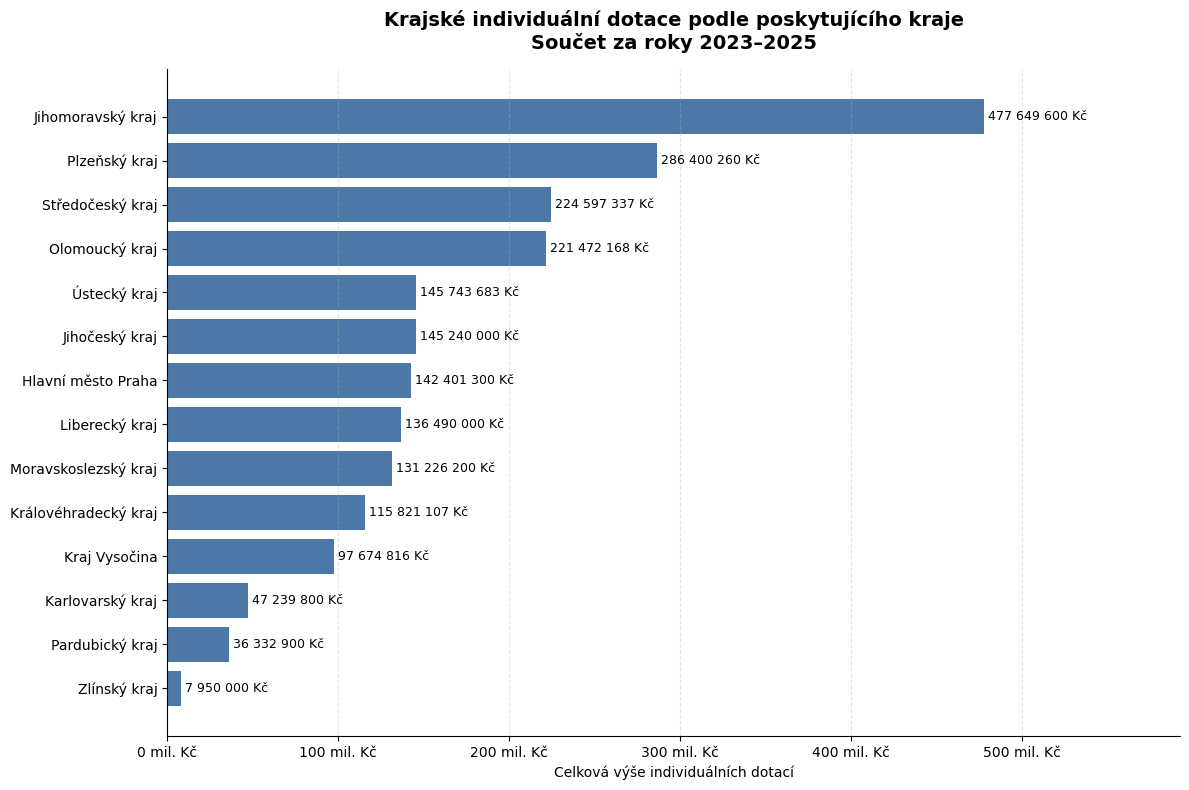

In [263]:
# ============================================================
# GRAF: KRAJSKÉ INDIVIDUÁLNÍ DOTACE PODLE KRAJE
# Součet za roky 2023–2025
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


# Data seřazená sestupně podle celkové částky.
graf_data = (
    srovnani_individualnich_dotaci_kraje_2023_2025[
        [
            "kraj_poskytovatel_dotace",
            "castka_celkem_kc"
        ]
    ]
    .sort_values(
        "castka_celkem_kc",
        ascending=False
    )
    .copy()
)


# Pro horizontální graf otočíme pořadí:
# nejvyšší hodnota se zobrazí nahoře.
graf_data = graf_data.iloc[::-1]


# Velikost grafu: šířka × výška v palcích.
fig, ax = plt.subplots(figsize=(12, 8))

sloupce = ax.barh(
    graf_data["kraj_poskytovatel_dotace"],
    graf_data["castka_celkem_kc"],
    color="#4C78A8"
)


# Osa X: částky v milionech Kč pro čitelnější měřítko.
ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x / 1_000_000:,.0f} mil. Kč"
        .replace(",", " ")
    )
)


# Hodnota u každého sloupce.
for sloupec, castka in zip(sloupce, graf_data["castka_celkem_kc"]):
    ax.text(
        sloupec.get_width(),
        sloupec.get_y() + sloupec.get_height() / 2,
        f" {castka:,.0f} Kč".replace(",", " "),
        va="center",
        ha="left",
        fontsize=9
    )


# Vzhled grafu.
ax.set_title(
    "Krajské individuální dotace podle poskytujícího kraje\n"
    "Součet za roky 2023–2025",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Celková výše individuálních dotací")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.35)

# Odstranění horního a pravého okraje grafu.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Místo vpravo pro popisky hodnot.
ax.set_xlim(
    0,
    graf_data["castka_celkem_kc"].max() * 1.24
)

plt.tight_layout()
plt.show()

# Sjednocení názvů - Druhy služeb

In [264]:
prehled_druhu_sluzeb = (
    dashboard_financovani_sluzeb
    .groupby(
        ["zdroj_financovani", "druh_sluzby"],
        dropna=False
    )
    .agg(
        pocet_radku=("druh_sluzby", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .reset_index()
    .sort_values(
        ["druh_sluzby", "zdroj_financovani"]
    )
)

display(prehled_druhu_sluzeb)

,zdroj_financovani,druh_sluzby,pocet_radku,castka_celkem_kc
0,Krajské individuální dotace,Azylové domy,101,116613288.0
119,MPSV – individuální dotace,Azylové domy,661,135296499.0
156,MPSV – nadregionální síť,Azylové domy,17,52702345.0
179,Regionální síť sociálních služeb,Azylové domy,1690,4063319467.0
1,Krajské individuální dotace,Centra denních služeb,39,8404130.0
...,...,...,...,...
114,Krajské individuální dotace,§ 70 - sociální rehabilitace,53,10932491.0
115,Krajské individuální dotace,§ 70 a) - centrum duševního zdraví,2,1489400.0
116,Krajské individuální dotace,§ 70 sociální rehabilitace,63,18602000.0
117,Krajské individuální dotace,§ 70a centrum duševního zdraví,3,983000.0


In [265]:
ciselnik_puvodnich_druhu = (
    dashboard_financovani_sluzeb
    .groupby(
        ["zdroj_financovani", "druh_sluzby"],
        dropna=False
    )
    .agg(
        pocet_radku=("druh_sluzby", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .reset_index()
    .sort_values(["zdroj_financovani", "druh_sluzby"])
)

display(ciselnik_puvodnich_druhu)

,zdroj_financovani,druh_sluzby,pocet_radku,castka_celkem_kc
0,Krajské individuální dotace,Azylové domy,101,116613288.0
1,Krajské individuální dotace,Centra denních služeb,39,8404130.0
2,Krajské individuální dotace,Centrum duševního zdraví,3,732500.0
3,Krajské individuální dotace,Chráněné bydlení,108,43919450.0
4,Krajské individuální dotace,Denní stacionář,2,1111430.0
...,...,...,...,...
207,Regionální síť sociálních služeb,Terapeutické komunity,152,567528405.0
208,Regionální síť sociálních služeb,Terénní programy,2278,4164000858.0
209,Regionální síť sociálních služeb,Tlumočnické služby,329,670083501.0
210,Regionální síť sociálních služeb,Tísňová péče,130,692141491.0


In [266]:
mapovani_druhu_sluzeb = {
    "§ 37 - odborné sociální poradenství": "Odborné sociální poradenství",
    "§ 37 - odborné sociální poradenství s prvky terapie": "Odborné sociální poradenství",
    "§ 37 odborné sociální poradenství": "Odborné sociální poradenství",
    "§ 39 - osobní asistence": "Osobní asistence",
    "§ 39 osobní asistence": "Osobní asistence",
    "§ 40 - pečovatelská služba": "Pečovatelská služba",
    "§ 40 pečovatelská služba": "Pečovatelská služba",
    "§ 41 - tísňová péče": "Tísňová péče",
    "§ 41 tísňová péče": "Tísňová péče",
    "§ 42 - průvodcovské a předčitatelské služby": "Průvodcovské a předčitatelské služby",
    "§ 42 - průvodcovské a předčítatelské služby": "Průvodcovské a předčitatelské služby",
    "§ 42 průvodcovské a předčitatelské služby": "Průvodcovské a předčitatelské služby",
    "§ 43 - podpora samostatného bydlení": "Podpora samostatného bydlení",
    "§ 43 podpora samostatného bydlení": "Podpora samostatného bydlení",
    "§ 44 - odlehčovací služby": "Odlehčovací služby",
    "§ 44 odlehčovací služby": "Odlehčovací služby",
    "§ 45 - centra denních služeb": "Centra denních služeb",
    "§ 45 centra denních služeb": "Centra denních služeb",
    "§ 46 - denní stacionáře": "Denní stacionáře",
    "§ 46 denní stacionáře": "Denní stacionáře",
    "§ 47 - týdenní stacionáře": "Týdenní stacionáře",
    "§ 47 týdenní stacionáře": "Týdenní stacionáře",
    "§ 48 - domovy pro osoby se zdravotním postižením": "Domovy pro osoby se zdravotním postižením",
    "§ 48 domovy pro osoby se zdravotním postižením": "Domovy pro osoby se zdravotním postižením",
    "§ 49 - domovy pro seniory": "Domovy pro seniory",
    "§ 49 domovy pro seniory": "Domovy pro seniory",
    "§ 50 - domovy se zvláštním režimem": "Domovy se zvláštním režimem",
    "§ 50 domovy se zvláštním režimem": "Domovy se zvláštním režimem",
    "§ 51 - chráněné bydlení": "Chráněné bydlení",
    "§ 51 chráněné bydlení": "Chráněné bydlení",
    "§ 52 - sociální služby poskytované ve zdravotnických zařízeních ústavní péče": "Sociální služby poskytované ve zdravotnických zařízeních lůžkové péče",
    "§ 52 sociální služby poskytované ve zdravotnických zařízeních lůžkové péče": "Sociální služby poskytované ve zdravotnických zařízeních lůžkové péče",
    "§ 54 - raná péče": "Raná péče",
    "§ 54 raná péče": "Raná péče",
    "§ 55 telefonická krizová pomoc": "Telefonická krizová pomoc",
    "§ 56 - tlumočnické služby": "Tlumočnické služby",
    "§ 56 tlumočnické služby": "Tlumočnické služby",
    "§ 57 - azylové domy": "Azylové domy",
    "§ 57 azylové domy": "Azylové domy",
    "§ 58 - domy na půl cesty": "Domy na půl cesty",
    "§ 58 domy na půl cesty": "Domy na půl cesty",
    "§ 59 - kontaktní centra": "Kontaktní centra",
    "§ 59 kontaktní centra": "Kontaktní centra",
    "§ 59 kontatní centra": "Kontaktní centra",
    "§ 60 - krizová pomoc": "Krizová pomoc",
    "§ 60 a) - intervenční centra": "Intervenční centra",
    "§ 60 krizová pomoc": "Krizová pomoc",
    "§ 60a intervenční centra": "Intervenční centra",
    "§ 61 - nízkoprahová denní centra": "Nízkoprahová denní centra",
    "§ 61 nízkoprahová denní centra": "Nízkoprahová denní centra",
    "§ 62 - nízkoprahová zařízení pro děti a mládež": "Nízkoprahová zařízení pro děti a mládež",
    "§ 62 nízkoprahová zařízení pro děti a mládež": "Nízkoprahová zařízení pro děti a mládež",
    "§ 63 - noclehárny": "Noclehárny",
    "§ 63 noclehárny": "Noclehárny",
    "§ 64 - služby následné péče": "Služby následné péče",
    "§ 64 služby následné péče": "Služby následné péče",
    "§ 65 - sociálně aktivizační služby pro rodiny s dětmi": "Sociálně aktivizační služby pro rodiny s dětmi",
    "§ 65 sociálně aktivizační služby pro rodiny s dětmi": "Sociálně aktivizační služby pro rodiny s dětmi",
    "§ 66 - sociálně aktivizační služby pro seniory a osoby se zdravotním postižením": "Sociálně aktivizační služby pro seniory a osoby se zdravotním postižením",
    "§ 66 sociálně aktivizační služby pro seniory a osoby se zdravotním postižením": "Sociálně aktivizační služby pro seniory a osoby se zdravotním postižením",
    "§ 67 - sociálně terapeutické dílny": "Sociálně terapeutické dílny",
    "§ 67 sociálně terapeutické dílny": "Sociálně terapeutické dílny",
    "§ 68 - terapeutické komunity": "Terapeutické komunity",
    "§ 68 terapeutické komunity": "Terapeutické komunity",
    "§ 69 - terénní programy": "Terénní programy",
    "§ 69 terénní programy": "Terénní programy",
    "§ 70 - sociální rehabilitace": "Sociální rehabilitace",
    "§ 70 a) - centrum duševního zdraví": "Centrum duševního zdraví",
    "§ 70 sociální rehabilitace": "Sociální rehabilitace",
    "§ 70a centrum duševního zdraví": "Centrum duševního zdraví",
    "§ 90 - hospicová péče terén": "Hospicová péče",
    "Neregistrovaná služby": "Neidentifikováno",
    "Sas pro seniory a osoby se zdravotním postižením": "Sociálně aktivizační služby pro seniory a osoby se zdravotním postižením",
    "Odlehčovací služba": "Odlehčovací služby",
    "Domov se zvláštním režimem": "Domovy se zvláštním režimem",
    "Sociálně-aktivizační služby pro rodiny s dětmi": "Sociálně aktivizační služby pro rodiny s dětmi", 
    "Homesharing - alternativní odlehčovací služba": "Odlehčovací služby",
    "Domovy se zdravotním postižením": "Domovy pro osoby se zdravotním postižením",
    "Intervence v oblasti aba": "Neidentifikováno",
    "Odlehčovací služby p": "Odlehčovací služby",
    "Ranná péče": "Raná péče",
    "Sociální rehabilitace t/a/p": "Sociální rehabilitace",
    "Odlehčovací služby t/p": "Odlehčovací služby",
    "Odlehčovací služby a/p": "Odlehčovací služby",
    "Služba následné péče": "Služby následné péče",
    "Odlehčovací služby a/t": "Odlehčovací služby",
    "Odlehčovací služby t": "Odlehčovací služby",
    "Neregistrovaná služba": "Neidentifikováno",
    "Nespecifikováno": "Neidentifikováno"
    
}

In [267]:
# Zachování původního názvu kvůli auditu.
dashboard_financovani_sluzeb["druh_sluzby_puvodni"] = (
    dashboard_financovani_sluzeb["druh_sluzby"]
    .astype("string")
)

# Standardní název: mapované hodnoty se převedou,
# ostatní zatím zůstanou beze změny.
dashboard_financovani_sluzeb["druh_sluzby_standard"] = (
    dashboard_financovani_sluzeb["druh_sluzby"]
    .map(mapovani_druhu_sluzeb)
    .fillna(dashboard_financovani_sluzeb["druh_sluzby"])
    .astype("string")
)

In [268]:
audit_standardizace = (
    dashboard_financovani_sluzeb
    .groupby("druh_sluzby_standard", dropna=False)
    .agg(
        pocet_puvodnich_variant=("druh_sluzby_puvodni", "nunique"),
        puvodni_varianty=(
            "druh_sluzby_puvodni",
            lambda x: " | ".join(sorted(x.dropna().unique()))
        ),
        pocet_radku=("druh_sluzby_standard", "size"),
        castka_celkem_kc=("castka_kc", "sum")
    )
    .sort_values("pocet_puvodnich_variant", ascending=False)
)

display(audit_standardizace)

,pocet_puvodnich_variant,puvodni_varianty,pocet_radku,castka_celkem_kc
druh_sluzby_standard,,,,
Odlehčovací služby,10,Homesharing - alternativní odlehčovací služba ...,4521,6819240892.0
Sociálně aktivizační služby pro rodiny s dětmi,4,Sociálně aktivizační služby pro rodiny s dětmi...,3127,5714535492.0
Domovy se zvláštním režimem,4,Domov se zvláštním režimem | Domovy se zvláštn...,5671,34487476076.0
Průvodcovské a předčitatelské služby,4,Průvodcovské a předčitatelské služby | § 42 - ...,208,146282081.0
Raná péče,4,Ranná péče | Raná péče | § 54 - raná péče | § ...,821,2404725475.0
Služby následné péče,4,Služba následné péče | Služby následné péče | ...,723,982391098.0
Kontaktní centra,4,Kontaktní centra | § 59 - kontaktní centra | §...,1016,1303574094.0
Sociální rehabilitace,4,Sociální rehabilitace | Sociální rehabilitace ...,3942,8296806042.0
Odborné sociální poradenství,4,Odborné sociální poradenství | § 37 - odborné ...,7640,9227971417.940001


In [269]:
sloupce_kontrola = [
    "rok",
    "kraj",
    "zdroj_financovani",
    "druh_sluzby",
    "druh_sluzby_puvodni",
    "druh_sluzby_standard",
    "castka_kc"
]

print(
    dashboard_financovani_sluzeb
    .columns[
        dashboard_financovani_sluzeb.columns.isin(sloupce_kontrola)
    ]
    .tolist()
)

['rok', 'zdroj_financovani', 'druh_sluzby', 'castka_kc', 'kraj', 'druh_sluzby_puvodni', 'druh_sluzby_standard']


In [270]:
display(
    dashboard_financovani_sluzeb.loc[
        dashboard_financovani_sluzeb["druh_sluzby"]
        .astype("string")
        .str.contains(r"§ 70|§ 37", regex=True, na=False),
        [
            "zdroj_financovani",
            "druh_sluzby",
            "druh_sluzby_standard",
            "castka_kc"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["druh_sluzby_standard", "druh_sluzby"]
    )
)

,zdroj_financovani,druh_sluzby,druh_sluzby_standard,castka_kc
20458,Krajské individuální dotace,§ 70 a) - centrum duševního zdraví,Centrum duševního zdraví,1360000.0
20459,Krajské individuální dotace,§ 70 a) - centrum duševního zdraví,Centrum duševního zdraví,129400.0
18371,Krajské individuální dotace,§ 70a centrum duševního zdraví,Centrum duševního zdraví,300000.0
18377,Krajské individuální dotace,§ 70a centrum duševního zdraví,Centrum duševního zdraví,383000.0
20007,Krajské individuální dotace,§ 37 - odborné sociální poradenství,Odborné sociální poradenství,0.0
...,...,...,...,...
21833,Krajské individuální dotace,§ 70 sociální rehabilitace,Sociální rehabilitace,134000.0
21836,Krajské individuální dotace,§ 70 sociální rehabilitace,Sociální rehabilitace,516000.0
21854,Krajské individuální dotace,§ 70 sociální rehabilitace,Sociální rehabilitace,490000.0
21856,Krajské individuální dotace,§ 70 sociální rehabilitace,Sociální rehabilitace,414000.0


In [271]:
dashboard_financovani_sluzeb.to_csv(
    "dashboard_financovani_sluzeb.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

In [272]:
from pathlib import Path
import pandas as pd

cesta_tableau_csv = Path(
    r"C:\Users\jakub\Desktop\Finance_SS\dashboard_financovani_sluzeb.csv"
)

print("Soubor existuje:", cesta_tableau_csv.exists())
print("Cesta:", cesta_tableau_csv)

Soubor existuje: True
Cesta: C:\Users\jakub\Desktop\Finance_SS\dashboard_financovani_sluzeb.csv


In [273]:
kontrola_csv = pd.read_csv(
    cesta_tableau_csv,
    sep=";",
    encoding="utf-8-sig"
)

print("Počet řádků:", f"{len(kontrola_csv):,}")
print("Počet sloupců:", len(kontrola_csv.columns))
print("\nObsahuje druh_sluzby_standard:",
      "druh_sluzby_standard" in kontrola_csv.columns)

print("\nPosledních 8 sloupců:")
print(kontrola_csv.columns.tolist()[-8:])

Počet řádků: 83,744
Počet sloupců: 18

Obsahuje druh_sluzby_standard: True

Posledních 8 sloupců:
['kraj_poskytovatel_dotace', 'id_zaznamu_zdroj', 'puvod_zaznamu', 'uroven_detailu', 'status_standardizace', 'zdrojovy_df', 'druh_sluzby_puvodni', 'druh_sluzby_standard']


C:\Users\jakub\AppData\Local\Temp\ipykernel_8016\3953463709.py:1: DtypeWarning: Columns (2,4,5,10,11,12,13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  kontrola_csv = pd.read_csv(


In [274]:
nazvy_ke_kontrole = [
    "Neregistrovaná služby",
    "Intervence v oblasti aba",
    "Odlehčovací služba",
    "Domov se zvláštním režimem",
    "Sociálně-aktivizační služby pro rodiny s dětmi",
    "Homesharing - alternativní odlehčovací služba",
    "Domovy se zdravotním postižením",
    "Odlehčovací služby p",
    "Ranná péče",
    "Sociální rehabilitace t/a/p",
    "Odlehčovací služby t/p",
    "Odlehčovací služby a/p",
    "Služba následné péče",
    "Odlehčovací služby a/t",
]

overeni_mapovani_csv = (
    kontrola_csv.loc[
        kontrola_csv["druh_sluzby"].isin(nazvy_ke_kontrole),
        [
            "druh_sluzby",
            "druh_sluzby_standard",
            "zdroj_financovani",
            "castka_kc"
        ]
    ]
    .drop_duplicates()
    .sort_values(["druh_sluzby", "zdroj_financovani"])
)

display(overeni_mapovani_csv)

,druh_sluzby,druh_sluzby_standard,zdroj_financovani,castka_kc
17852,Domov se zvláštním režimem,Domovy se zvláštním režimem,MPSV – individuální dotace,1500000.0
19798,Domovy se zdravotním postižením,Domovy pro osoby se zdravotním postižením,Krajské individuální dotace,475000.0
23442,Homesharing - alternativní odlehčovací služba,Odlehčovací služby,Krajské individuální dotace,301630.0
23441,Intervence v oblasti aba,Neidentifikováno,Krajské individuální dotace,154640.0
17854,Odlehčovací služba,Odlehčovací služby,MPSV – individuální dotace,5239200.0
22686,Odlehčovací služby a/p,Odlehčovací služby,Krajské individuální dotace,12180.0
22802,Odlehčovací služby a/p,Odlehčovací služby,Krajské individuální dotace,8050.0
23132,Odlehčovací služby a/p,Odlehčovací služby,Krajské individuální dotace,12750.0
23235,Odlehčovací služby a/p,Odlehčovací služby,Krajské individuální dotace,8530.0
22618,Odlehčovací služby a/t,Odlehčovací služby,Krajské individuální dotace,11380.0
